In [126]:
import sys
import warnings
from pathlib import Path
from typing import Self

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import RobustScaler, SplineTransformer, StandardScaler
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL, DecomposeResult
from statsmodels.tsa.stattools import acf, adfuller, kpss

sys.path.insert(0, str(Path.cwd().parent))

from data_utils.fancy_barplot import fancy_bars
from data_utils.fast_OLS import DiagnosticoOLS
from data_utils.triple_plot import normality_report
from data_utils.vif_resume import vif_table

In [127]:
datos_por_hoja = pd.read_excel("../data/Base_de_Datos.xlsx", sheet_name=None)
df_ensamble = datos_por_hoja["Ensamble"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_ensamble.columns = df_ensamble.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_ensamble = df_ensamble.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_ensamble = df_ensamble.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_ensamble.columns.name = None

In [128]:
df_ensamble

,Año,Mes,Dia,Turno,Proceso,Indice,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2019,Oct,NaN,NaN,Linea 1,0.34,309181,105121.54,NaN,0,NaN,NaN,NaN
1,2019,Oct,NaN,NaN,Linea 2,0.19,309181,58744.486037,NaN,0,NaN,NaN,NaN
2,2019,Oct,NaN,NaN,Linea 3,0.2,309181,61836.2,NaN,0,NaN,NaN,NaN
3,2019,Oct,NaN,NaN,Linea 4,0.27,309181,83478.87,NaN,0,NaN,NaN,NaN
4,2019,Oct,NaN,NaN,Ensamble,1,309181,309181,124270,2.487978,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
405,2026,Jul,NaN,NaN,Linea 1,0.34,279900,95166.0,32581.806,2.920833,2.241444,529.577718,50397793.117626
406,2026,Jul,NaN,NaN,Linea 2,0.19,279900,53181.086942,20681.034,2.571491,2.102712,529.577718,28163518.667088
407,2026,Jul,NaN,NaN,Linea 3,0.2,279900,55980.0,0,0,1.499576,529.577718,29645760.657427
408,2026,Jul,NaN,NaN,Linea 4,0.27,279900,75573.0,28363.0464,2.664488,2.203593,529.577718,40021776.887526


# Analizar Nulos

In [129]:
def nan_diagnosis(df: pd.DataFrame, name: str = "el df") -> None:
    """Return a graph that show null values."""
    n_cols = len(df.columns)
    ancho = max(10, int(n_cols * 0.35))
    alto = 5

    tamano_letra = max(6, 10 - n_cols // 10)

    # Porcentaje de nulos por columna
    pct_nulos = df.isnull().mean() * 100

    try:
        ax = msno.matrix(df, figsize=(ancho, alto), fontsize=tamano_letra) or plt.gca()
        plt.title(f"Patrón de Faltantes en {name}")

        if len(ax.get_xticks()) == n_cols:
            ax.set_xticks(range(n_cols))
            ax.set_xticklabels(
                [f"{c} ({p:.1f}%)" for c, p in zip(df.columns, pct_nulos, strict=False)],
                rotation=45,
                ha="left",
                fontsize=tamano_letra,
            )

        plt.show()

    except Exception:
        plt.figure(figsize=(ancho, alto))
        missing_pattern = df.isnull()

        plt.imshow(missing_pattern.astype(int), aspect="auto", cmap="RdYlGn_r")

        plt.xticks(
            ticks=range(n_cols),
            labels=[
                f"{c} ({p:.1f}%)" for c, p in zip(missing_pattern.columns, pct_nulos, strict=False)
            ],
            rotation=90,
            fontsize=tamano_letra,
            ha="center",
        )
        plt.yticks([])
        plt.title("Patrón de Faltantes (blanco = faltante)")
        plt.colorbar(label="1=Faltante, 0=Presente")

        plt.tight_layout()  # Evita que las etiquetas se corten abajo
        plt.show()

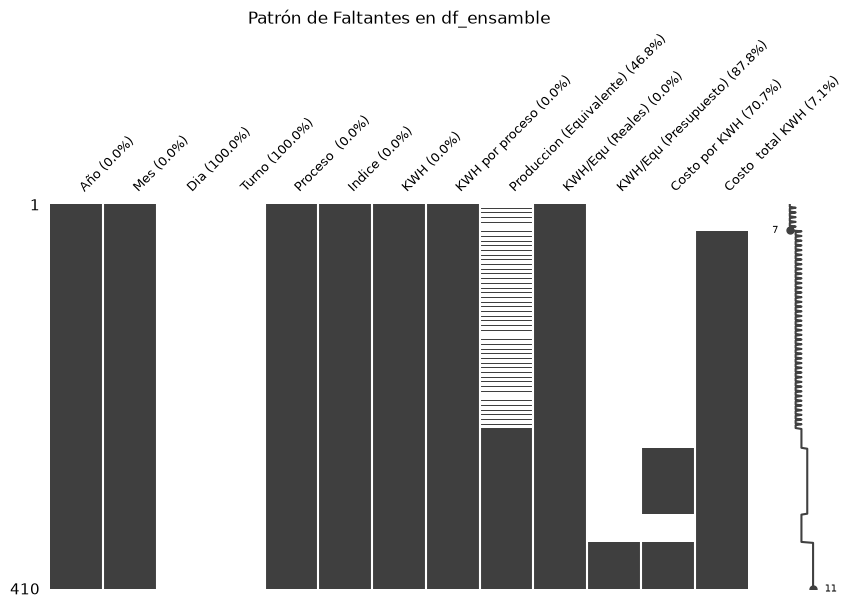

In [130]:
nan_diagnosis(df_ensamble, name="df_ensamble")

In [131]:
df_ensamble["Proceso "].unique()

<ArrowStringArray>
['Linea 1', 'Linea 2', 'Linea 3', 'Linea 4', 'Ensamble']
Length: 5, dtype: str

In [132]:
no_ensamble = df_ensamble[df_ensamble["Proceso "] != "Ensamble"]["Produccion (Equivalente)"]
solo_ensamble = df_ensamble[df_ensamble["Proceso "] == "Ensamble"]["Produccion (Equivalente)"]

print(f"Null values in non-Ensamble rows: {no_ensamble.isnull().sum()}")
print(f"Null values in Ensamble rows: {solo_ensamble.isnull().sum()}")

Null values in non-Ensamble rows: 192
Null values in Ensamble rows: 0


Parece ser que el consolidado por fabrica de este df es el proceso=Ensamble

In [133]:
df_ensamble[df_ensamble["Proceso "] != "OREC"]["Produccion (Equivalente)"] * df_ensamble[
    df_ensamble["Proceso "] != "OREC"
]["Indice"]

0              NaN
1              NaN
2              NaN
3              NaN
4           124270
          ...     
405    11077.81404
406    3929.402884
407            0.0
408    7658.022528
409     81625.8864
Length: 410, dtype: object

## Eliminar columas sin datos o constantes.

In [134]:
cols_to_drop = []
for col in df_ensamble.columns:
    if df_ensamble[col].isnull().all() or df_ensamble[col].nunique() == 1:
        cols_to_drop.append(col)
print(f"Columns to drop: {cols_to_drop}")

df_ensamble.drop(columns=cols_to_drop, inplace=True)

Columns to drop: ['Dia', 'Turno']


# Transformar al tipo correcto

In [135]:
df_ensamble.info()

<class 'pandas.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Año                       410 non-null    object
 1   Mes                       410 non-null    str   
 2   Proceso                   410 non-null    str   
 3   Indice                    410 non-null    object
 4   KWH                       410 non-null    object
 5   KWH por proceso           410 non-null    object
 6   Produccion (Equivalente)  218 non-null    object
 7   KWH/Equ (Reales)          410 non-null    object
 8   KWH/Equ (Presupuesto)     50 non-null     object
 9   Costo por KWH             120 non-null    object
 10  Costo  total KWH          381 non-null    object
dtypes: object(9), str(2)
memory usage: 39.4+ KB


In [136]:
df_ensamble = df_ensamble.rename(
    columns={"Costo  total KWH": "Costo total KWH", "Proceso ": "Proceso"}
)

In [137]:
df_ensamble["KWH"]

0      309181
1      309181
2      309181
3      309181
4      309181
        ...  
405    279900
406    279900
407    279900
408    279900
409    279900
Name: KWH, Length: 410, dtype: object

In [138]:
cols_numericas = [
    "Año",
    "Indice",
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]
for col in cols_numericas:
    df_ensamble[col] = (
        df_ensamble[col]
        .astype(str)
        .str.strip()
        # Nota: en esta base el punto es el separador DECIMAL (0 valores con
        # coma, 567 con punto), por eso NO se eliminan los puntos.
        .str.replace(",", ".", regex=False)  # Convierte coma decimal a punto
    )

# 2. Conversión a tipos de datos específicos

# Año e Indice a enteros (usando Int64 para soportar posibles valores nulos)
df_ensamble["Año"] = pd.to_numeric(df_ensamble["Año"], errors="coerce").astype("Int64")
df_ensamble["Indice"] = pd.to_numeric(df_ensamble["Indice"], errors="coerce")
# Columnas continuas/métricas a flotantes (float64)
cols_float = [
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

for col in cols_float:
    df_ensamble[col] = pd.to_numeric(df_ensamble[col], errors="coerce")

# Columnas de texto/categoría
df_ensamble["Mes"] = df_ensamble["Mes"].astype("category")  # o .astype(str)

# Verifica el resultado
df_ensamble.info()

<class 'pandas.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Año                       410 non-null    Int64   
 1   Mes                       410 non-null    category
 2   Proceso                   410 non-null    str     
 3   Indice                    410 non-null    float64 
 4   KWH                       410 non-null    int64   
 5   KWH por proceso           410 non-null    float64 
 6   Produccion (Equivalente)  218 non-null    float64 
 7   KWH/Equ (Reales)          410 non-null    float64 
 8   KWH/Equ (Presupuesto)     50 non-null     float64 
 9   Costo por KWH             120 non-null    float64 
 10  Costo total KWH           381 non-null    float64 
dtypes: Int64(1), category(1), float64(7), int64(1), str(1)
memory usage: 36.0 KB


In [139]:
meses_abr = {
    "ene": 1,
    "feb": 2,
    "mar": 3,
    "abr": 4,
    "may": 5,
    "jun": 6,
    "jul": 7,
    "ago": 8,
    "sep": 9,
    "oct": 10,
    "nov": 11,
    "dic": 12,
}

# 1. Limpiar texto y mapear a número
mes_num = (
    df_ensamble["Mes"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(".", "", regex=False)  # Quita puntos si vienen como 'Ene.'
    .map(meses_abr)
)

# 2. Crear la columna de Fecha (primer día de cada mes)
df_ensamble["Fecha"] = pd.to_datetime(
    {"year": df_ensamble["Año"], "month": mes_num, "day": 1}, errors="coerce"
)

In [140]:
# La hoja viene en orden cronologico, 5 filas por mes. Un solo bloque rompe el orden:
# las filas 10-14, entre nov-2019 y ene-2020, traen el anio 2020. Es diciembre de 2019
# mal digitado; sin corregirlo 2019-12 queda vacio y 2020-12 mezcla dos meses.
# Se corrige aqui, antes de repartir los dias, para que cada mes quede con sus 5 filas.
FILAS_POR_MES = 5
bloque = df_ensamble.index // FILAS_POR_MES
calendario = pd.date_range(df_ensamble["Fecha"].iloc[0], periods=bloque.max() + 1, freq="MS")
esperada = pd.Series(calendario[bloque], index=df_ensamble.index)

mal = df_ensamble["Fecha"] != esperada
desfase = (df_ensamble.loc[mal, "Fecha"] - esperada[mal]).dt.days

# Si la hoja cambia y el patron deja de ser este, mejor fallar que re-fechar a ciegas
assert mal.sum() == FILAS_POR_MES, "se esperaba un unico bloque mal rotulado"
assert desfase.between(365, 366).all(), "el desfase no es de un anio exacto"

print(
    f"filas corregidas: {list(df_ensamble.index[mal])}  "
    f"{df_ensamble.loc[mal, 'Fecha'].iloc[0]:%Y-%m} -> {esperada[mal].iloc[0]:%Y-%m}"
)
df_ensamble.loc[mal, "Año"] = esperada[mal].dt.year
df_ensamble.loc[mal, "Fecha"] = esperada[mal]

filas corregidas: [10, 11, 12, 13, 14]  2020-12 -> 2019-12


In [141]:
# Anio fiscal: va de octubre a septiembre y se nombra por el anio calendario en que cierra
# (oct-2019 a sep-2020 = FY2020). Se calcula aqui, con el diciembre ya corregido: antes las
# filas 10-14 caerian en el anio fiscal equivocado.
MES_INICIO_FISCAL = 10


def anio_fiscal(fechas: pd.DatetimeIndex) -> pd.Index:
    """Anio fiscal de cada fecha, nombrado por el anio calendario en que cierra."""
    return (fechas.year + (fechas.month >= MES_INICIO_FISCAL)).rename("fiscal year")


def inicio_fiscal(anio: int) -> pd.Timestamp:
    """Primer dia del anio fiscal `anio` (FY2025 empieza el 2024-10-01)."""
    return pd.Timestamp(year=anio - 1, month=MES_INICIO_FISCAL, day=1)


def rotulo_fiscal(anio: int, corto: bool = False) -> str:
    """`FY2025`, o `FY25` en los ejes donde no cabe el anio completo."""
    return f"FY{anio % 100:02d}" if corto else f"FY{anio}"


df_ensamble["fiscal year"] = anio_fiscal(pd.DatetimeIndex(df_ensamble["Fecha"]))
df_ensamble.groupby("fiscal year")["Fecha"].agg(["min", "max", "size"])

,min,max,size
fiscal year,,,
2020,2019-10-01,2020-09-01,60
2021,2020-10-01,2021-09-01,60
2022,2021-10-01,2022-09-01,60
2023,2022-10-01,2023-09-01,60
2024,2023-10-01,2024-09-01,60
2025,2024-10-01,2025-09-01,60
2026,2025-10-01,2026-07-01,50


In [142]:
base_fecha = pd.to_datetime(df_ensamble["Fecha"])

# 2. Número de aparición (0, 1, 2, ...) dentro de cada grupo Año-Mes
k = df_ensamble.groupby(["Año", "Mes"]).cumcount()

# 3. Total de registros por cada grupo Año-Mes
n = df_ensamble.groupby(["Año", "Mes"])["Fecha"].transform("count")

# 4. Total de días del mes específico (considera años bisiestos automáticamente)
dias_en_mes = base_fecha.dt.days_in_month

# 5. Calcular el día correspondiente con distribución uniforme entre el día 1 y el último día del
# mes
# Para n == 1 el incremento es 0 (queda día 1). Para n > 1 el último registro queda cerca del final
# del mes.
incremento_dias = (k * (dias_en_mes - 1) / (n - 1).replace(0, 1)).round()

# 6. Sumar los días a la fecha base (día 1)
df_ensamble["Fecha"] = base_fecha + pd.to_timedelta(incremento_dias, unit="D")

In [143]:
df_ensamble["Fecha"]

0     2019-10-01
1     2019-10-09
2     2019-10-16
3     2019-10-23
4     2019-10-31
         ...    
405   2026-07-01
406   2026-07-09
407   2026-07-16
408   2026-07-23
409   2026-07-31
Name: Fecha, Length: 410, dtype: datetime64[us]

# Split the data

In [144]:
df_ensamble.shape

(410, 13)

In [145]:
# El split tiene que ser temporal, asi que las filas se ordenan por fecha antes
# de partirlas. df_ensamble no se toca: las secciones de series de tiempo dependen
# de el. El indice original se conserva, para poder rastrear cada fila.
orden = df_ensamble.sort_values("Fecha")

X = orden.drop(columns=["Mes", "Año", "fiscal year", "Produccion (Equivalente)"])
y = orden["Produccion (Equivalente)"]
X.shape, y.shape

((410, 9), (410,))

In [146]:
# Split temporal: el ultimo fold de TimeSeriesSplit deja todo el pasado en train y el
# futuro en test. El corte es el inicio de un anio fiscal, asi ningun anio fiscal queda
# repartido entre train y test.
FY_TEST = 2025  # primer anio fiscal de la ventana de test
CORTE = inicio_fiscal(FY_TEST)
test_size = int((orden["fiscal year"] >= FY_TEST).sum())

# n_splits=2 es el minimo que admite sklearn; solo interesa el ultimo fold, el que
# entrena con todo lo anterior al corte. El corte se expresa en anios fiscales y no en
# un numero de filas para que la frontera caiga siempre en un inicio de anio fiscal.
tscv = TimeSeriesSplit(n_splits=2, test_size=test_size)
*_, (i_train, i_test) = tscv.split(X)

X_train, X_test = X.iloc[i_train], X.iloc[i_test]
y_train, y_test = y.iloc[i_train], y.iloc[i_test]

In [147]:
fiscal_train = orden.loc[X_train.index, "fiscal year"]
fiscal_test = orden.loc[X_test.index, "fiscal year"]
print(
    f"train FY{fiscal_train.min()}-FY{fiscal_train.max()}  "
    f"{X_train['Fecha'].min():%Y-%m} -> {X_train['Fecha'].max():%Y-%m}"
    f"  ({len(X_train)} filas)"
)
print(
    f"test  FY{fiscal_test.min()}-FY{fiscal_test.max()}  "
    f"{X_test['Fecha'].min():%Y-%m} -> {X_test['Fecha'].max():%Y-%m}"
    f"  ({len(X_test)} filas)"
)
print(
    f"sin solape: {X_train['Fecha'].max() < X_test['Fecha'].min()}  |  "
    f"target no nulo: train={y_train.notna().sum()} test={y_test.notna().sum()}"
)
X_train.shape, X_test.shape

train FY2020-FY2024  2019-10 -> 2024-09  (300 filas)
test  FY2025-FY2026  2024-10 -> 2026-07  (110 filas)
sin solape: True  |  target no nulo: train=108 test=110


((300, 9), (110, 9))

In [148]:
df_train = pd.concat([X_train, y_train], axis=1)

# Iniciar el análisis exploratorio de datos (EDA) con las funciones personalizadas

In [149]:
df_train.columns

Index(['Proceso', 'Indice', 'KWH', 'KWH por proceso', 'KWH/Equ (Reales)',
       'KWH/Equ (Presupuesto)', 'Costo por KWH', 'Costo total KWH', 'Fecha',
       'Produccion (Equivalente)'],
      dtype='str')

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 5 distinct values across 300 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


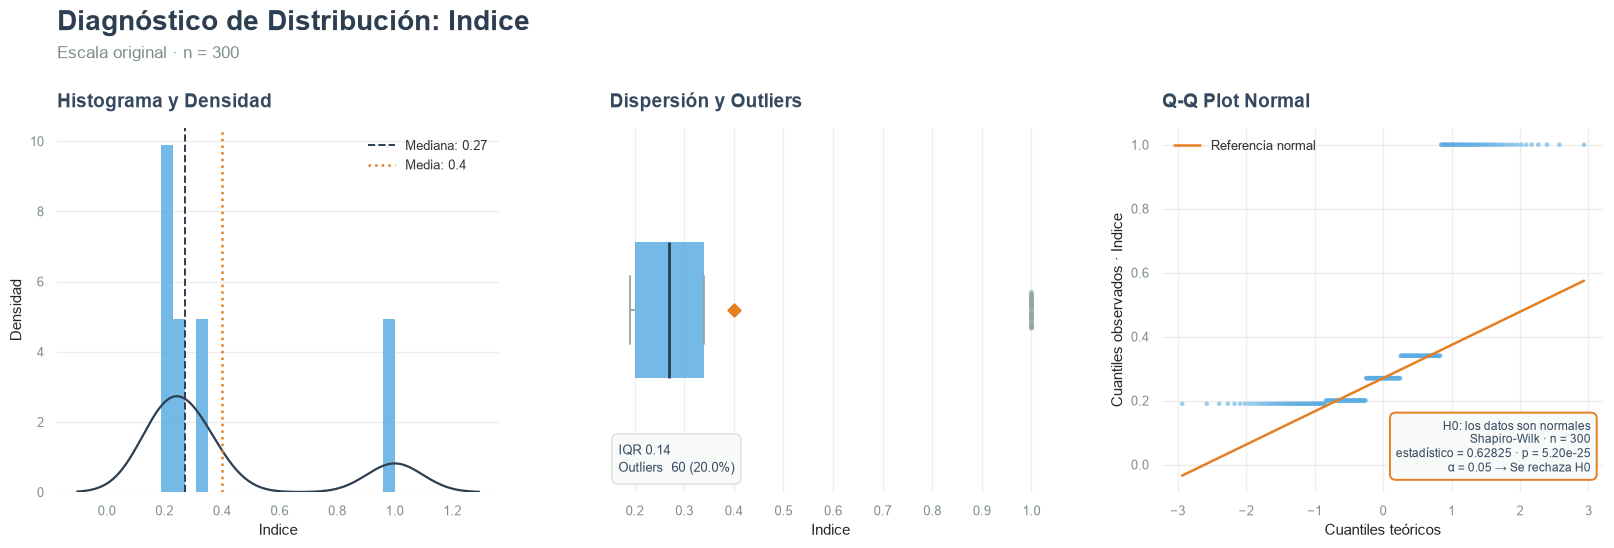

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 60 distinct values across 300 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


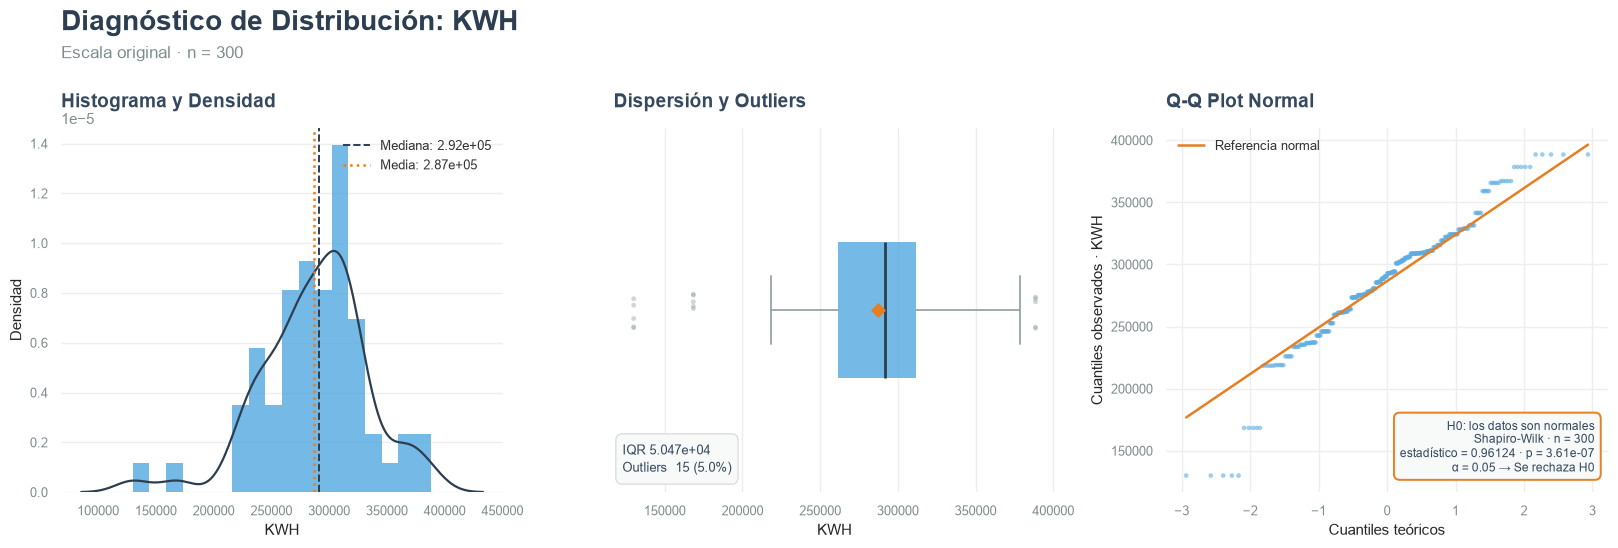

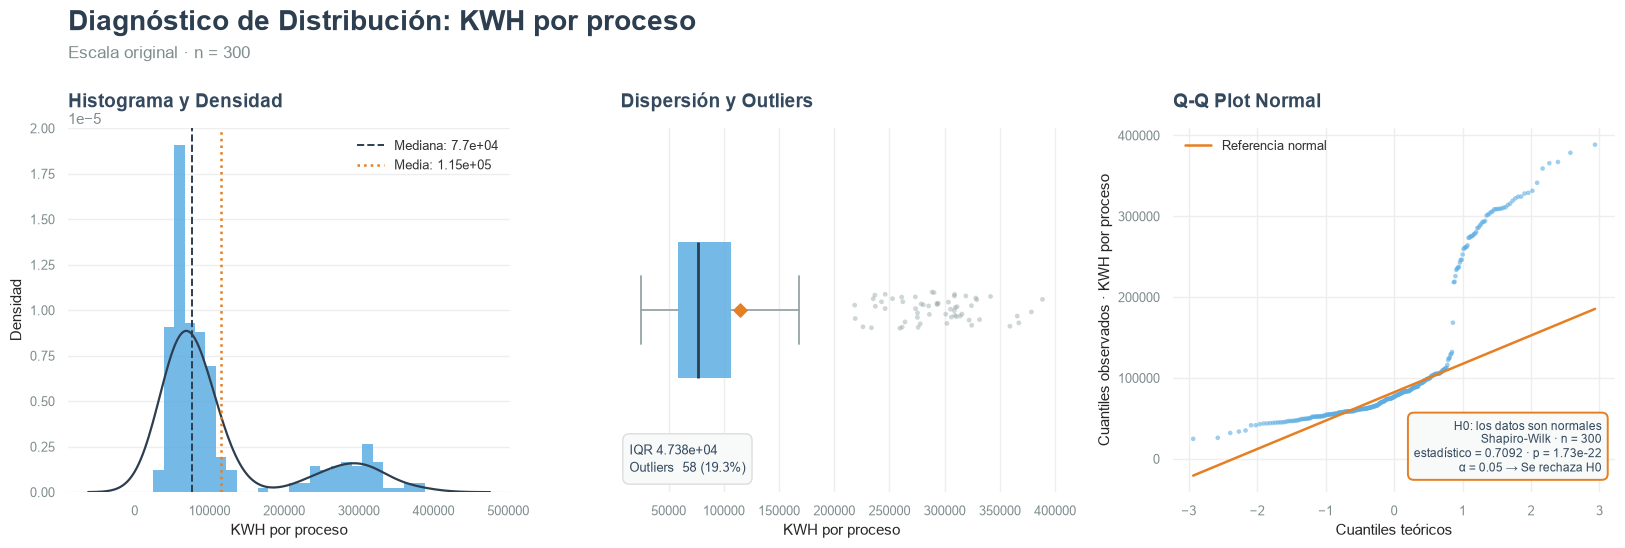

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 109 distinct values across 300 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


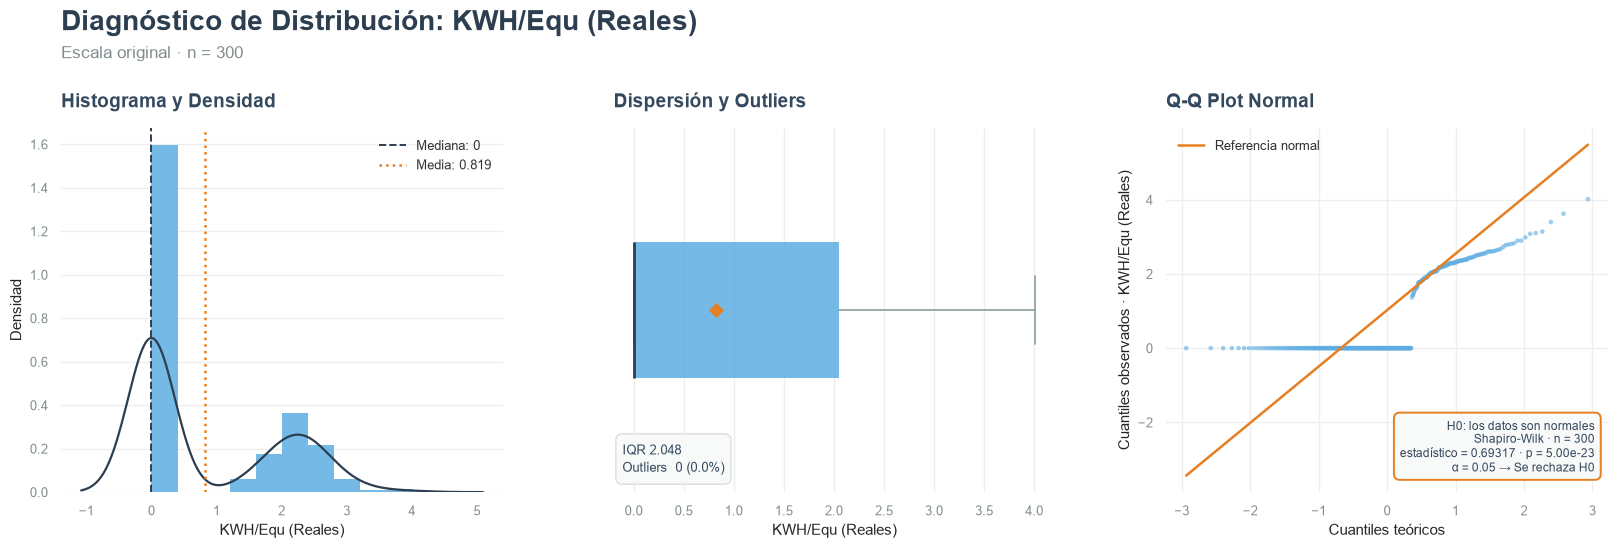

KWH/Equ (Presupuesto): 0 valores validos en train, se omite (se registra desde una fecha posterior al corte)


d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 8 distinct values across 40 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


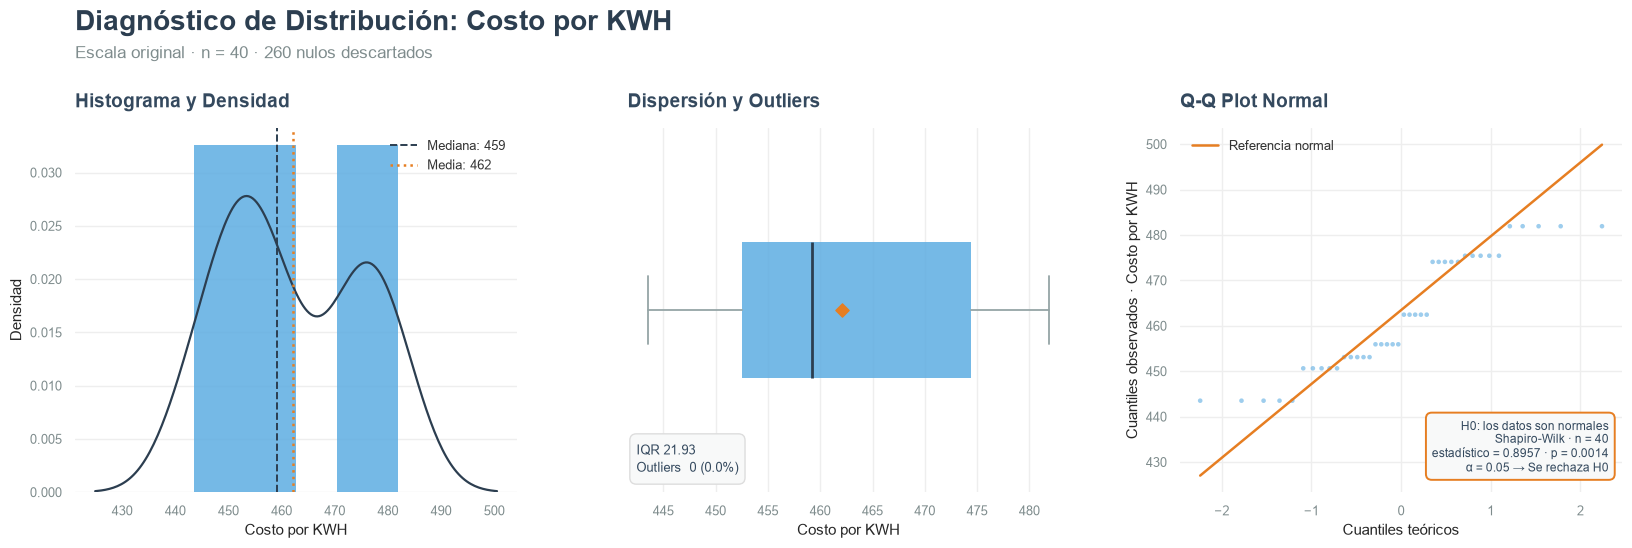

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 41 distinct values across 271 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


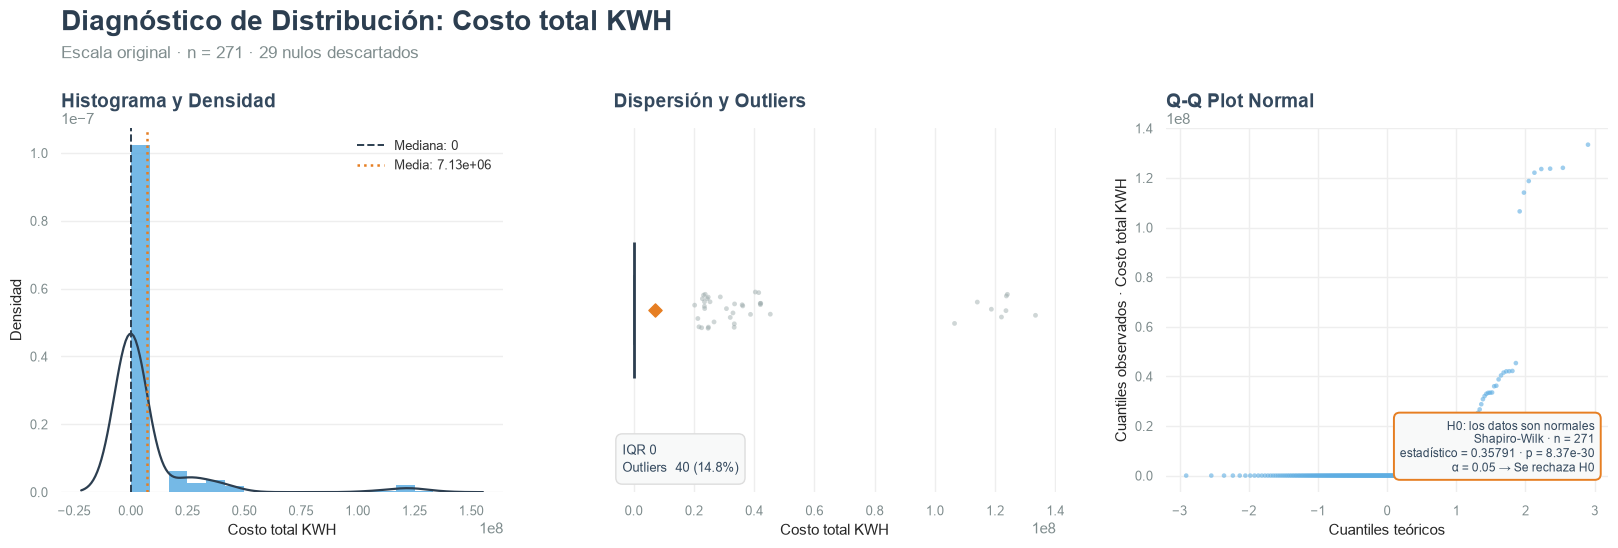

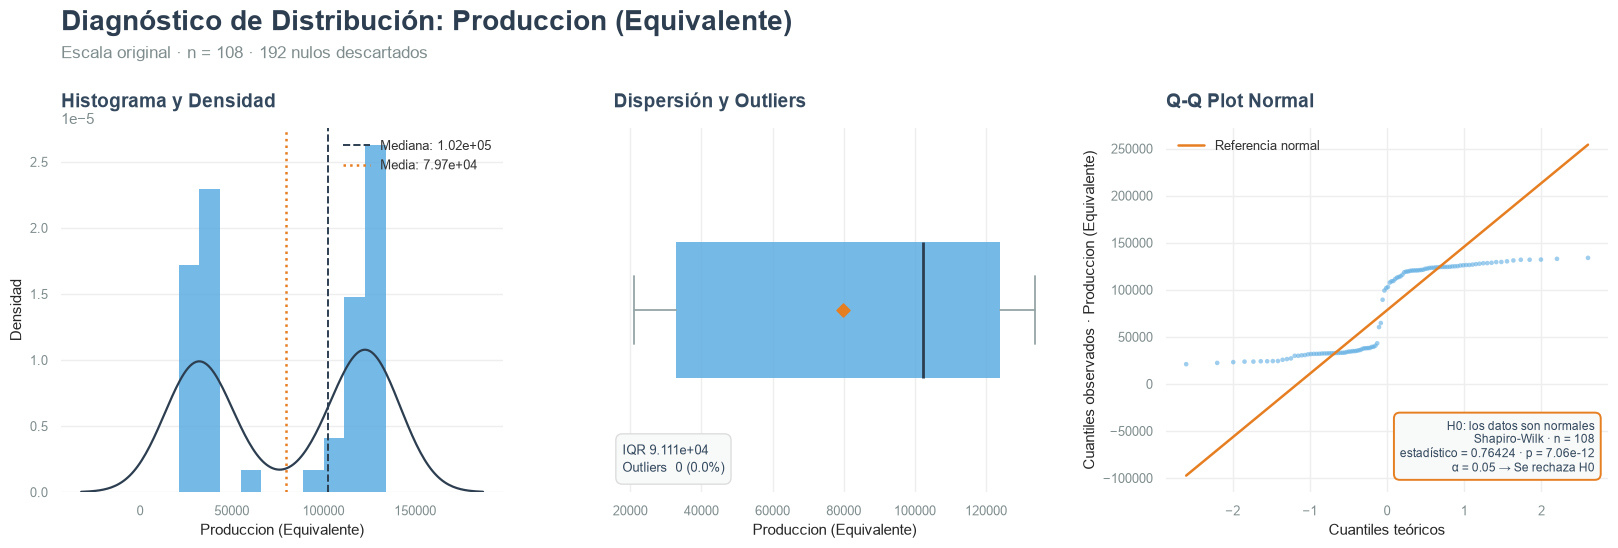

In [150]:
# El split es temporal, asi que una columna que empieza a registrarse tarde puede
# quedar vacia en train: KWH/Equ (Presupuesto) arranca en 2025-10, ya dentro de la
# ventana de test. normality_report exige un minimo de 8 valores, asi que se avisa
# y se sigue en vez de cortar el notebook.
MIN_VALIDOS = 8

for col in df_train.columns:
    if df_train[col].dtype == "int64" or df_train[col].dtype == "float64":
        validos = df_train[col].dropna().size
        if validos < MIN_VALIDOS:
            print(
                f"{col}: {validos} valores validos en train, se omite "
                f"(se registra desde una fecha posterior al corte)"
            )
            continue
        normality_report(df_train, col)

`Produccion (Equivalente)` muestra dos picos porque mezcla dos escalas: el total de planta
(filas `Ensamble`) y el valor de cada linea. Conviene leerla separada por proceso, para no
sacar conclusiones de una distribucion que en realidad son dos.

<Axes: title={'left': 'Distribución de Proceso'}, xlabel='Proceso', ylabel='Conteo'>

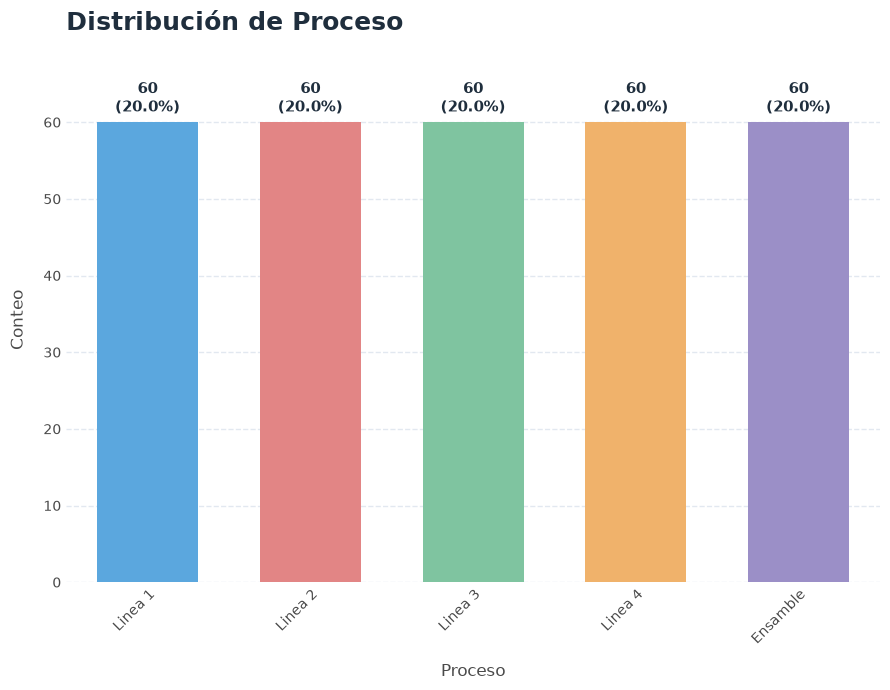

In [151]:
fancy_bars(df_train, "Proceso", labels="both", rot=45)

## Ahondando en los atipicos

In [152]:
cols = ["Costo total KWH", "Costo por KWH", "KWH/Equ (Reales)", "KWH por proceso"]

# Los ceros y nulos son estructurales (proceso sin registro), no mediciones:
# incluirlos deformaria el IQR. Todo se calcula sobre valores > 0.
resumen = []
for col in cols:
    s = df_ensamble[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    resumen.append(
        {
            "columna": col,
            "n": len(s),
            "atipicos": len(atipicos),
            "mediana": s.median(),
            "maximo": s.max(),
            "max/mediana": s.max() / s.median(),
        }
    )

pd.DataFrame(resumen).round(1)

,columna,n,atipicos,mediana,maximo,max/mediana
0,Costo total KWH,120,24,33390473.9,155090957.5,4.6
1,Costo por KWH,120,0,518.2,568.5,1.1
2,KWH/Equ (Reales),209,12,2.3,5.8,2.6
3,KWH por proceso,410,79,73852.7,388552.0,5.3


In [153]:
# Algunos valores atipicos concretos (los 5 mas altos de cada columna)
for col in cols:
    s = df_ensamble[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    print(f"{col} -> {len(atipicos)} atipicos")
    print(atipicos.nlargest(5).to_string())

Costo total KWH -> 24 atipicos
329    1.550910e+08
409    1.482288e+08
364    1.453902e+08
319    1.403276e+08
289    1.334069e+08
Costo por KWH -> 0 atipicos
Series([], )
KWH/Equ (Reales) -> 12 atipicos
385    5.818852
389    5.374443
99     4.013277
394    3.806766
388    3.759890
KWH por proceso -> 79 atipicos
64    388552.0
49    378529.0
74    367130.0
69    365666.0
54    359084.0


Costo total KWH        mediana=  33,390,473.9  max= 155,090,957.5  ordenes=0.67
Costo por KWH          mediana=         518.2  max=         568.5  ordenes=0.04
KWH/Equ (Reales)       mediana=           2.3  max=           5.8  ordenes=0.41
KWH por proceso        mediana=      73,852.7  max=     388,552.0  ordenes=0.72


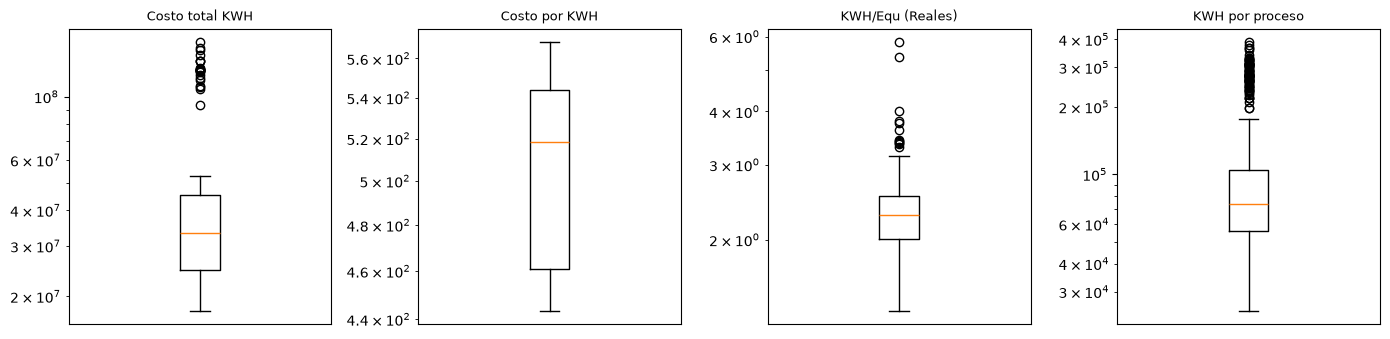

In [154]:
# Ordenes de magnitud entre el maximo y la mediana
for col in cols:
    s = df_ensamble.loc[df_ensamble[col] > 0, col].dropna()
    print(
        f"{col:<22} mediana={s.median():>14,.1f}  max={s.max():>14,.1f}  "
        f"ordenes={np.log10(s.max() / s.median()):.2f}"
    )

# Escala log: si la caja se ve aplastada contra el eje, la cola abarca ordenes de magnitud
fig, axes = plt.subplots(1, len(cols), figsize=(14, 3.5))
for ax, col in zip(axes, cols, strict=False):
    ax.boxplot(df_ensamble.loc[df_ensamble[col] > 0, col].dropna())
    ax.set_yscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [155]:
# Metricas explicitas del resumen de abajo
filas = []
for col in cols:
    s = df_ensamble[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    # Cuantos de los atipicos son filas de total de planta: la columna mezcla la escala
    # de la planta (Ensamble) con la de cada linea
    de_planta = df_ensamble.loc[atipicos.index, "Proceso"] == "Ensamble"
    filas.append(
        {
            "columna": col,
            "n": len(s),
            "atipicos": len(atipicos),
            "atipicos_en_Ensamble": int(de_planta.sum()),
            "mediana": s.median(),
            "maximo": s.max(),
            "max_sobre_mediana": s.max() / s.median(),
            "ordenes": np.log10(s.max() / s.median()),
            # Ceros y nulos contados sobre df_ensamble completo
            "ceros": int((df_ensamble[col] == 0).sum()),
            "nulos": int(df_ensamble[col].isna().sum()),
        }
    )

metricas_atipicos = pd.DataFrame(filas).round(2)
print(f"df_ensamble: {len(df_ensamble)} filas | df_train (temporal): {len(df_train)} filas")
metricas_atipicos

df_ensamble: 410 filas | df_train (temporal): 300 filas


,columna,n,atipicos,atipicos_en_Ensamble,mediana,maximo,max_sobre_mediana,ordenes,ceros,nulos
0,Costo total KWH,120,24,24,33390473.94,1.550910e+08,4.64,0.67,261,29
1,Costo por KWH,120,0,0,518.21,5.684600e+02,1.10,0.04,0,290
2,KWH/Equ (Reales),209,12,7,2.28,5.820000e+00,2.55,0.41,201,0
3,KWH por proceso,410,79,79,73852.69,3.885520e+05,5.26,0.72,0,0


### Resumen de atipicos

**1. Atipicos por IQR** (solo valores > 0, sobre las 410 filas):

| columna | mediana | maximo | max/mediana | atipicos | de `Ensamble` |
|---|---|---|---|---|---|
| `Costo total KWH` | 33,390,473.9 | 155,090,957.5 | 4.64x | 24 | 24 |
| `Costo por KWH` | 518.2 | 568.5 | 1.10x | 0 | 0 |
| `KWH/Equ (Reales)` | 2.28 | 5.82 | 2.55x | 12 | 7 |
| `KWH por proceso` | 73,852.7 | 388,552.0 | 5.26x | 79 | 79 |

**2. Ninguna columna crece por ordenes de magnitud.** La mayor razon es 5.26x (0.72
ordenes) y `KWH/Equ (Reales)` se queda en 2.55x (0.41). No hay un registro aislado como
el de OREC.

**3. Los atipicos de `KWH por proceso` y `Costo total KWH` son las filas de planta.** Los
79 y los 24 son filas `Ensamble`: la columna mezcla el total de planta con el valor de cada
linea y el IQR marca la escala mayor. No son mediciones anomalas.

**4. `Costo por KWH` no tiene atipicos** y casi no varia (1.10x). Es una tarifa, no una
medicion del proceso.

**5. Ceros y nulos son estructurales** y se excluyeron del calculo: `Costo total KWH` tiene
261 ceros y 29 nulos, `KWH/Equ (Reales)` 201 ceros y `Costo por KWH` 290 nulos.

In [156]:
# En OREC habia un registro que crecia ordenes de magnitud y se retiraba. Aqui la
# pregunta es si hace falta: se arma la misma copia sin el maximo de KWH/Equ (Reales)
# para medir cuanto cambia el diagnostico. df_ensamble no se modifica y la copia no
# se usa mas abajo.
df_sin_maximo = df_ensamble.drop(df_ensamble["KWH/Equ (Reales)"].idxmax())

Costo total KWH        mediana=  33,372,532.5  max= 155,090,957.5  ordenes=0.67
Costo por KWH          mediana=         513.1  max=         568.5  ordenes=0.04
KWH/Equ (Reales)       mediana=           2.3  max=           5.4  ordenes=0.37
KWH por proceso        mediana=      73,869.0  max=     388,552.0  ordenes=0.72


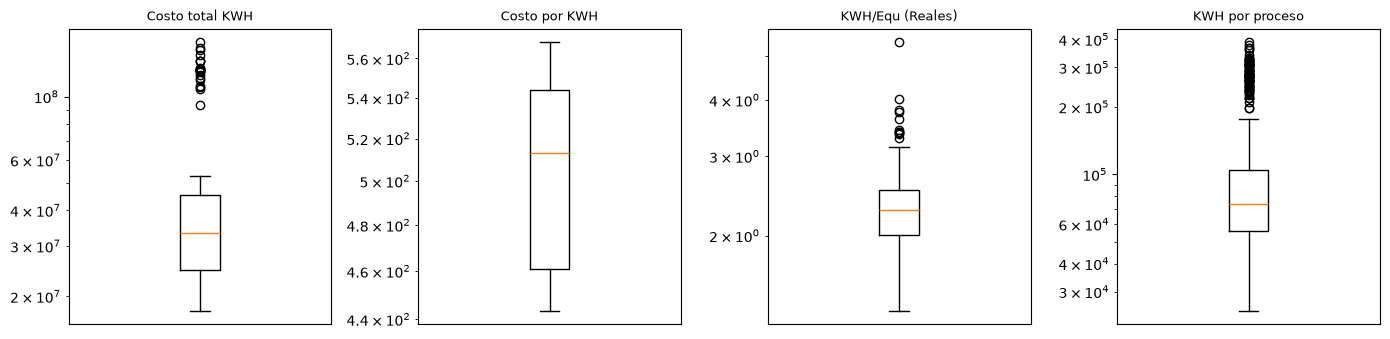

In [157]:
# Mismo analisis que arriba, ahora sobre el dataset sin el valor maximo
for col in cols:
    s = df_sin_maximo.loc[df_sin_maximo[col] > 0, col].dropna()
    print(
        f"{col:<22} mediana={s.median():>14,.1f}  max={s.max():>14,.1f}  "
        f"ordenes={np.log10(s.max() / s.median()):.2f}"
    )

fig, axes = plt.subplots(1, len(cols), figsize=(14, 3.5))
for ax, col in zip(axes, cols, strict=False):
    ax.boxplot(df_sin_maximo.loc[df_sin_maximo[col] > 0, col].dropna())
    ax.set_yscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [158]:
# Las dos mitades de la comparacion se calculan aqui: df_ensamble no se modifica.
def ordenes(d: pd.DataFrame, col: str) -> float:
    """Ordenes de magnitud entre el maximo y la mediana de `col`, sobre valores > 0."""
    s = d.loc[d[col] > 0, col].dropna()
    return np.log10(s.max() / s.median())


comparacion = pd.DataFrame(
    [
        {
            "columna": col,
            "ordenes_antes": round(ordenes(df_ensamble, col), 2),
            "ordenes_despues": round(ordenes(df_sin_maximo, col), 2),
            # criterio: < 1 orden. Si ya se cumplia antes, no habia nada que corregir
            "ya_cumplia_antes": ordenes(df_ensamble, col) < 1,
        }
        for col in cols
    ]
)
comparacion

,columna,ordenes_antes,ordenes_despues,ya_cumplia_antes
0,Costo total KWH,0.67,0.67,True
1,Costo por KWH,0.04,0.04,True
2,KWH/Equ (Reales),0.41,0.37,True
3,KWH por proceso,0.72,0.72,True


In [159]:
# Metricas explicitas del resumen de abajo.
# El 'antes' es df_ensamble completo y el 'despues' la copia sin el valor maximo.
antes = df_ensamble
despues = df_sin_maximo


def resumen_iqr(d: pd.DataFrame) -> pd.DataFrame:
    """Tabla IQR por columna: atipicos, maximo, razon max/mediana y ordenes."""
    filas = []
    for col in cols:
        s = d[col].dropna()
        s = s[s > 0]
        q1, q3 = s.quantile([0.25, 0.75])
        atipicos = s[s > q3 + 1.5 * (q3 - q1)]
        filas.append(
            {
                "columna": col,
                "atipicos": len(atipicos),
                "maximo": s.max(),
                "ratio": s.max() / s.median(),
                "ordenes": np.log10(s.max() / s.median()),
            }
        )
    return pd.DataFrame(filas).set_index("columna")


a, b = resumen_iqr(antes), resumen_iqr(despues)
metricas_verificacion = (
    a.join(b, lsuffix="_antes", rsuffix="_despues")
    .assign(ya_cumplia_antes=lambda t: t["ordenes_antes"] < 1)
    .reset_index()
    .round(2)
)

# El registro del maximo, junto al total de planta de ese mismo mes
i_max = df_ensamble["KWH/Equ (Reales)"].idxmax()
mismo_mes = df_ensamble["Fecha"].dt.to_period("M") == df_ensamble.loc[i_max, "Fecha"].to_period("M")
de_interes = df_ensamble["Proceso"].isin([df_ensamble.loc[i_max, "Proceso"], "Ensamble"])
registro_maximo = df_ensamble.loc[
    mismo_mes & de_interes,
    ["Fecha", "Proceso", "KWH por proceso", "Produccion (Equivalente)", "KWH/Equ (Reales)"],
].round(2)

print(f"filas: {len(antes)} -> {len(despues)} (la copia quita {len(antes) - len(despues)})")
display(registro_maximo)
metricas_verificacion

filas: 410 -> 409 (la copia quita 1)


D:\Temp\ipykernel_4624\1926848230.py:42: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Fecha,Proceso,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales)
385,2026-03-01,Linea 1,67098.32,11531.20,5.82
389,2026-03-31,Ensamble,197348.00,36719.71,5.37


,columna,atipicos_antes,maximo_antes,ratio_antes,ordenes_antes,atipicos_despues,maximo_despues,ratio_despues,ordenes_despues,ya_cumplia_antes
0,Costo total KWH,24,1.550910e+08,4.64,0.67,24,1.550910e+08,4.65,0.67,True
1,Costo por KWH,0,5.684600e+02,1.10,0.04,0,5.684600e+02,1.11,0.04,True
2,KWH/Equ (Reales),12,5.820000e+00,2.55,0.41,11,5.370000e+00,2.36,0.37,True
3,KWH por proceso,79,3.885520e+05,5.26,0.72,79,3.885520e+05,5.26,0.72,True


### Verificacion: no hay registro extremo que quitar

- **No habia nada que corregir.** Las cuatro columnas ya estaban por debajo de 1 orden de
  magnitud antes de quitar nada (`ya_cumplia_antes` es verdadero en todas).
- **Quitar el maximo casi no cambia el diagnostico.** `KWH/Equ (Reales)` pasa de 0.41 a
  0.37 ordenes (de 2.55x a 2.36x) y de 12 a 11 atipicos; las otras tres columnas quedan
  en los mismos ordenes (0.67, 0.04 y 0.72).
- **El maximo es un mes real, no un error.** Es `Linea 1` en 2026-03: 67,098.32 kWh para
  11,531.20 equivalentes (5.82). Ese mismo mes el total de planta marca 5.37: produjo poco
  toda la planta, no solo esa linea.
- **Por eso no se elimina ninguna fila.** La copia de 409 filas solo sirve para esta
  comparacion; el resto del notebook usa las 410.

## Series de tiempo de las variables numericas

La base solo tiene `Año` y `Mes`: la columna `Fecha` reparte los registros entre los dias
del mes de forma artificial, asi que la granularidad real es **mensual**. Cada punto es el
promedio de los 5 procesos de ese mes. La serie llega hasta **2026-07**, que esta completo.

Estas secciones usan **todo el historico**, no solo la ventana de train: son
descriptivas, no alimentan ningun modelo, y el cambio que analizan ocurre justo en
FY2025-FY2026. La banda gris de cada grafico marca la ventana de test (desde `FY2025`),
para que se vea que parte de la serie quedo fuera del entrenamiento.

In [160]:
num_cols = [
    "Indice",
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

# Granularidad real = mensual; promedio entre los 5 procesos de cada mes.
# Fecha reparte el dia dentro del mes de forma artificial, asi que se agrupa por el
# inicio de mes. No hace falta recortar la cola: 2026-07 trae sus 5 filas.
mes_completo = df_ensamble["Fecha"].dt.to_period("M").dt.to_timestamp()
serie = df_ensamble.groupby(mes_completo)[num_cols].mean()

serie.shape

(82, 8)

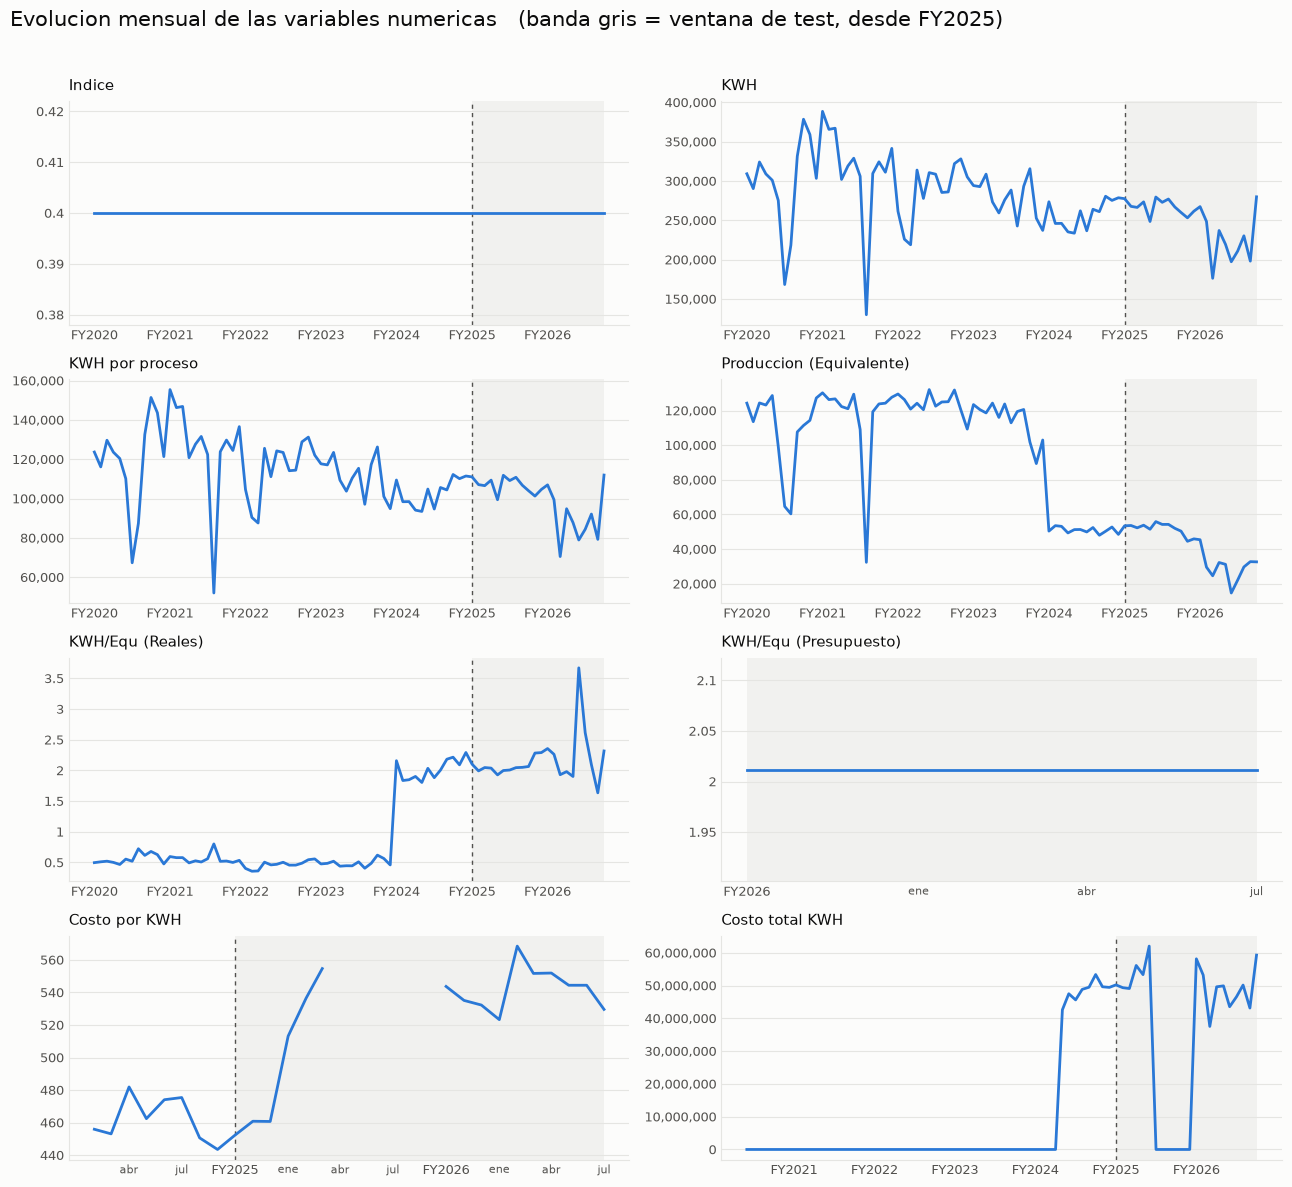

In [161]:
# Paleta validada (skill dataviz): linea, superficie, tinta y grilla
LINEA, SUPERFICIE = "#2a78d6", "#fcfcfb"
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e5e5e2"

# Por encima de este valor el eje se formatea con separador de miles y sin decimales;
# por debajo, con 3 cifras significativas (si no, 1.5, 2 y 2.5 se rotulan todos '2')
UMBRAL_MILES = 1000
# Un panel con menos historia que esto queda con una o dos marcas de anio fiscal: se le
# anaden los trimestres (ene, abr, jul) como marcas menores
PANEL_CORTO = pd.Timedelta(days=3 * 365)
NOMBRES_MES = list(meses_abr)  # "ene" ... "dic", en orden calendario

# Las series cubren todo el historico, pero el split es temporal: esta funcion sombrea
# la ventana de test para que se vea que parte quedo fuera del entrenamiento.
# CORTE viene de la celda del split, asi la banda sigue al corte y no se repite el dato.
CORTE_TS = pd.Timestamp(CORTE)
# El mismo rotulo en el titulo de todas las figuras con eje de fechas
NOTA_TEST = f"(banda gris = ventana de test, desde FY{FY_TEST})"


def marcar_test(
    ax: plt.Axes, desde: pd.Timestamp, hasta: pd.Timestamp, etiqueta: bool = False
) -> None:
    """Sombrea la ventana de test, recortada al rango que ya ocupa la serie."""
    # El rango se pasa explicito: ax.get_xlim() devuelve numeros de fecha de matplotlib
    # y mezclarlos con un Timestamp en axvspan falla. Recortar a [desde, hasta] evita
    # que la banda estire el eje de un panel cuyos datos empiezan despues del corte
    # (KWH/Equ (Presupuesto) arranca en 2025-10, ya dentro de test).
    if hasta < CORTE_TS:
        return  # el panel termina antes del corte: no hay ventana de test que marcar
    ax.axvspan(max(CORTE_TS, desde), hasta, color=GRILLA, alpha=0.45, zorder=0, linewidth=0)
    if desde <= CORTE_TS:
        ax.axvline(CORTE_TS, color=TINTA_SUAVE, linewidth=1, linestyle=(0, (3, 3)), zorder=2)
    if etiqueta:
        ax.annotate(
            "ventana de test",
            xy=(CORTE_TS, 1),
            xycoords=("data", "axes fraction"),
            xytext=(5, -12),
            textcoords="offset points",
            color=TINTA_SUAVE,
            fontsize=8,
        )


def eje_fiscal(ax: plt.Axes, desde: pd.Timestamp, hasta: pd.Timestamp, corto: bool = False) -> None:
    """Rotula el eje de fechas por anio fiscal: una marca en cada octubre."""
    # Las marcas se fijan dentro de [desde, hasta]: no aparece un anio fiscal en un margen
    # sin datos. El rotulo va al inicio del anio, como en un eje de anios calendario.
    inicios = pd.date_range(desde, hasta, freq="YS-OCT")
    ax.set_xticks(inicios, [rotulo_fiscal(a, corto) for a in anio_fiscal(inicios)])
    if hasta - desde < PANEL_CORTO:
        trimestres = pd.date_range(desde, hasta, freq="QS-OCT").difference(inicios)
        ax.set_xticks(trimestres, [NOMBRES_MES[t.month - 1] for t in trimestres], minor=True)
        ax.tick_params(axis="x", which="minor", colors=TINTA_SUAVE, labelsize=8, length=0)


fig, axes = plt.subplots(4, 2, figsize=(13, 12), facecolor=SUPERFICIE)
fig.suptitle(
    f"Evolucion mensual de las variables numericas   {NOTA_TEST}",
    fontsize=15,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)

for ax, col in zip(axes.ravel(), num_cols, strict=False):
    ax.plot(serie.index, serie[col], color=LINEA, linewidth=2, zorder=3)
    visible = serie[col].replace(0, np.nan).dropna()
    marcar_test(ax, visible.index[0], visible.index[-1])
    ax.set_title(col, fontsize=10.5, color=TINTA, loc="left", pad=8)
    ax.set_facecolor(SUPERFICIE)
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
    ax.yaxis.set_major_formatter(
        lambda v, _: f"{v:,.0f}" if abs(v) >= UMBRAL_MILES else f"{v:,.3g}"
    )
    trazado = serie[col].dropna()
    eje_fiscal(ax, trazado.index[0], trazado.index[-1])

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [162]:
# Metricas explicitas del resumen de abajo
mes = df_ensamble["Fecha"].dt.to_period("M").dt.to_timestamp()
es_planta = df_ensamble["Proceso"] == "Ensamble"

# 1) Cobertura: desde cuando hay dato y en cuantos meses
cobertura = pd.DataFrame(
    [
        {
            "variable": c,
            "desde": mes[df_ensamble[c] > 0].min(),
            "meses_con_dato": mes[df_ensamble[c] > 0].nunique(),
            "meses_totales": mes.nunique(),
        }
        for c in num_cols
    ]
)

# 2) Calendario: tras corregir el diciembre mal rotulado no quedan huecos ni meses dobles
meses = sorted(mes.unique())
esperados = pd.date_range(min(meses), max(meses), freq="MS")
filas_por_mes = mes.value_counts()
print(
    f"meses {len(meses)} de {len(esperados)} esperados -> "
    f"sin huecos: {len(meses) == len(esperados)}"
)
print(
    f"de {min(meses):%Y-%m} a {max(meses):%Y-%m} | "
    f"filas por mes: minimo {filas_por_mes.min()}, maximo {filas_por_mes.max()}"
)

# 3) Desde cuando reportan produccion las lineas: ahi cambia lo que promedia cada mes
prod_lineas = mes[~es_planta & (df_ensamble["Produccion (Equivalente)"] > 0)]
print(f"produccion por linea desde {prod_lineas.min():%Y-%m} ({prod_lineas.nunique()} meses)")

# 4) Las dos agregaciones lado a lado: promedio por proceso vs total de planta (Ensamble)
por_proceso = df_ensamble.groupby(mes)[
    ["KWH", "Produccion (Equivalente)", "KWH/Equ (Reales)"]
].mean()
solo_planta = df_ensamble[es_planta]
planta_ts = solo_planta.groupby(mes[es_planta])[
    ["KWH por proceso", "Produccion (Equivalente)", "KWH"]
].mean()
planta_ts["KWH/Equ"] = planta_ts["KWH por proceso"] / planta_ts["Produccion (Equivalente)"]


def cambio(valores: pd.Series, a: int = 2020, b: int = 2025) -> tuple[float, float, float]:
    """Media de `valores` en los anios fiscales `a` y `b`, y el cambio porcentual."""
    fiscal = anio_fiscal(valores.index)
    x, y = valores[fiscal == a].mean(), valores[fiscal == b].mean()
    return x, y, 100 * (y - x) / x


filas = []
for etiqueta, valores in [
    ("promedio por proceso | KWH", por_proceso["KWH"]),
    ("promedio por proceso | Produccion", por_proceso["Produccion (Equivalente)"]),
    ("promedio por proceso | KWH/Equ", por_proceso["KWH/Equ (Reales)"]),
    ("planta Ensamble | KWH por proceso", planta_ts["KWH por proceso"]),
    ("planta Ensamble | Equivalentes", planta_ts["Produccion (Equivalente)"]),
    ("planta Ensamble | KWH/Equ", planta_ts["KWH/Equ"]),
]:
    m_a, m_b, pct = cambio(valores)
    filas.append({"medida": etiqueta, "media_FY2020": m_a, "media_FY2025": m_b, "cambio_pct": pct})

metricas_series = pd.DataFrame(filas).round(1)
display(cobertura)
metricas_series

meses 82 de 82 esperados -> sin huecos: True
de 2019-10 a 2026-07 | filas por mes: minimo 5, maximo 5
produccion por linea desde 2023-10 (34 meses)


,variable,desde,meses_con_dato,meses_totales
0,Indice,2019-10-01,82,82
1,KWH,2019-10-01,82,82
2,KWH por proceso,2019-10-01,82,82
3,Produccion (Equivalente),2019-10-01,82,82
4,KWH/Equ (Reales),2019-10-01,82,82
5,KWH/Equ (Presupuesto),2025-10-01,10,82
6,Costo por KWH,2024-02-01,24,82
7,Costo total KWH,2024-02-01,24,82


,medida,media_FY2020,media_FY2025,cambio_pct
0,promedio por proceso | KWH,297363.2,267085.8,-10.2
1,promedio por proceso | Produccion,108242.2,51827.7,-52.1
2,promedio por proceso | KWH/Equ,0.6,2.1,270.8
3,planta Ensamble | KWH por proceso,297363.2,267085.8,-10.2
4,planta Ensamble | Equivalentes,108242.2,129569.3,19.7
5,planta Ensamble | KWH/Equ,2.8,2.1,-26.0


### Resumen de las series de tiempo

**1. Cada metrica empieza en una fecha distinta.**

| variable | desde | meses con dato |
|---|---|---|
| `Indice`, `KWH`, `KWH por proceso`, `Produccion (Equivalente)`, `KWH/Equ (Reales)` | 2019-10 | 82 / 82 |
| `Costo por KWH`, `Costo total KWH` | **2024-02** | 24 / 82 |
| `KWH/Equ (Presupuesto)` | **2025-10** | 10 / 82 |

La produccion cubre los 82 meses gracias a la fila de planta; las lineas solo la reportan
desde **2023-10** (34 meses).

**2. El promedio por proceso distorsiona; la fila de planta no** (promedios por año fiscal):

| medida | FY2020 | FY2025 | cambio |
|---|---|---|---|
| promedio por proceso, `Produccion` | 108,242.2 | 51,827.7 | -52.1 % |
| promedio por proceso, `KWH/Equ` | 0.6 | 2.1 | +270.8 % |
| planta, energia | 297,363.2 | 267,085.8 | **-10.2 %** |
| planta, equivalentes | 108,242.2 | 129,569.3 | **+19.7 %** |
| planta, `KWH/Equ` | 2.8 | 2.1 | **-26.0 %** |

La caida del promedio es un efecto de agregacion: antes de 2023-10 solo `Ensamble` reporta
produccion y despues se promedia con cuatro lineas de menor escala. La fila de planta dice
lo contrario: entre FY2020 y FY2025 se produjo mas con menos energia.

**3. Cobertura.** 82 meses, de 2019-10 a 2026-07, sin huecos y con 5 filas cada uno. El
bloque que venia rotulado `2020 Dic` se corrigio a 2019-12 antes de repartir los dias.

## Crecimiento de la energia por bateria producida

La fila `Ensamble` de cada mes es el **total de planta**, no un proceso mas: las cuatro
lineas son su desglose. A nivel de planta se cumple exactamente:

`KWH/Equ (Reales) = KWH por proceso / Produccion (Equivalente)`

Las tres magnitudes viven en escalas muy distintas (cientos de miles de kWh, decenas de
miles de equivalentes y una razon de pocas unidades), asi que se indexan a base 100 para
compararlas en un solo eje.

In [163]:
# Solo la fila Ensamble = total de planta (las 4 lineas son su desglose).
# Se indexa por inicio de mes: Fecha reparte el dia de forma artificial.
planta = df_ensamble[df_ensamble["Proceso"] == "Ensamble"].copy()
planta["Mes_inicio"] = planta["Fecha"].dt.to_period("M").dt.to_timestamp()
planta = planta.set_index("Mes_inicio").sort_index()

# Media movil de 12 meses: quita la estacionalidad para poder leer el crecimiento.
# La razon se calcula sobre las series ya suavizadas (nunca el promedio de razones),
# asi el indice combinado cierra exacto.
energia = planta["KWH por proceso"].rolling(12).mean()
equiv = planta["Produccion (Equivalente)"].rolling(12).mean()
razon = energia / equiv

# Indice base 100 en la primera ventana completa, no en un mes suelto
idx = pd.DataFrame(
    {
        "Energia (KWH)": 100 * energia / energia.dropna().iloc[0],
        "Equivalentes": 100 * equiv / equiv.dropna().iloc[0],
        "KWH/Equ": 100 * razon / razon.dropna().iloc[0],
    }
).dropna()

# La curva combinada: KWH/Equ indexado == 100 * Energia_idx / Equivalentes_idx
idx["KWH/Equ (calculada)"] = 100 * idx["Energia (KWH)"] / idx["Equivalentes"]

assert np.allclose(idx["KWH/Equ"], idx["KWH/Equ (calculada)"]), "la identidad no cierra"
print(
    f"{len(planta)} meses de planta | indice desde {idx.index[0]:%Y-%m} hasta {idx.index[-1]:%Y-%m}"
)
idx.tail(3).round(2)

82 meses de planta | indice desde 2020-09 hasta 2026-07


,Energia (KWH),Equivalentes,KWH/Equ,KWH/Equ (calculada)
Mes_inicio,,,,
2026-05-01,79.28,81.32,97.49,97.49
2026-06-01,77.36,77.62,99.66,99.66
2026-07-01,77.91,74.21,104.99,104.99


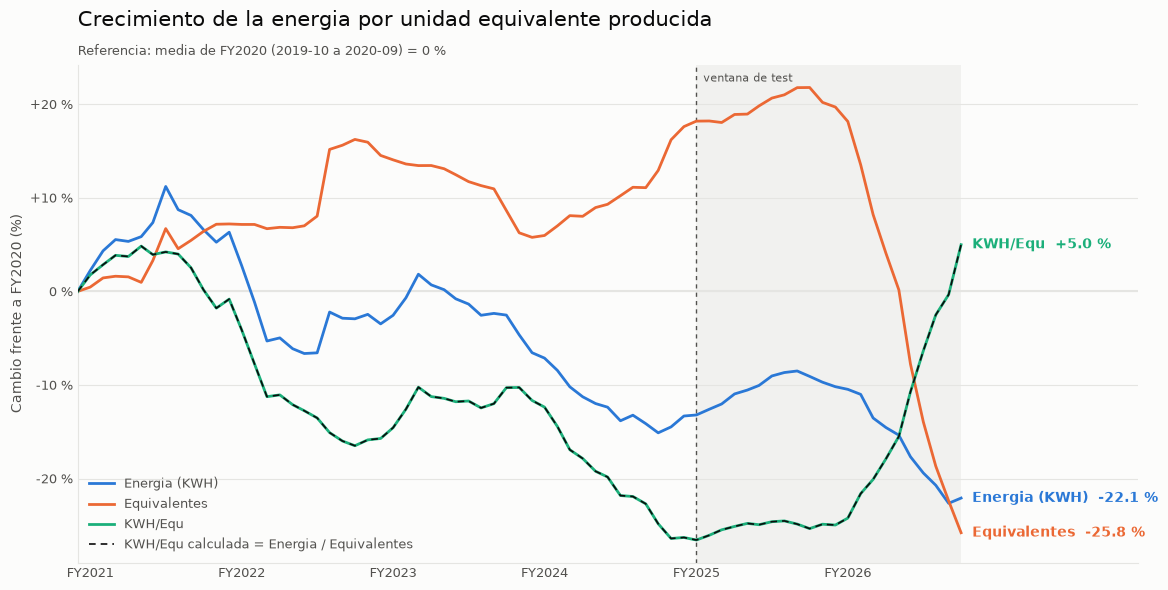

In [164]:
# Paleta validada (skill dataviz, slots 1-3, --pairs all)
C_ENERGIA, C_EQUIV, C_RAZON = "#2a78d6", "#eb6834", "#1baf7a"
SUPERFICIE, TINTA, TINTA_SUAVE, GRILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e5e2"


def rotulo_cambio(valor: float, _posicion: float = 0) -> str:
    """Cambio porcentual con signo; el cero, que es la referencia, va sin signo."""
    return "0 %" if round(valor) == 0 else f"{valor:+.0f} %"


# El indice esta en base 100: se dibuja como cambio frente a la referencia (indice - 100)
cambio_planta = idx - 100

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SUPERFICIE)
ax.set_facecolor(SUPERFICIE)

ax.axhline(0, color=GRILLA, linewidth=1.5, zorder=1)
series = [
    ("Energia (KWH)", C_ENERGIA),
    ("Equivalentes", C_EQUIV),
    ("KWH/Equ", C_RAZON),
]
for nombre, color in series:
    ax.plot(idx.index, cambio_planta[nombre], color=color, linewidth=2, label=nombre, zorder=3)

# Curva combinada calculada: debe caer exactamente sobre KWH/Equ medido
ax.plot(
    idx.index,
    cambio_planta["KWH/Equ (calculada)"],
    color=TINTA,
    linewidth=1.2,
    linestyle=(0, (4, 3)),
    zorder=4,
    label="KWH/Equ calculada = Energia / Equivalentes",
)

# Etiquetas directas (obligatorias: el verde queda por debajo de 3:1 de contraste)
for nombre, color in series:
    y_final = cambio_planta[nombre].iloc[-1]
    ax.annotate(
        f"{nombre}  {y_final:+.1f} %",
        xy=(idx.index[-1], y_final),
        xytext=(8, 0),
        textcoords="offset points",
        color=color,
        fontsize=10,
        fontweight="bold",
        va="center",
    )

# La banda queda dentro de los datos; las etiquetas directas viven en el margen
# de 14 meses que anade set_xlim, asi que no se solapan con ella.
marcar_test(ax, idx.index[0], idx.index[-1], etiqueta=True)
eje_fiscal(ax, idx.index[0], idx.index[-1])

# La primera ventana de 12 meses cierra en septiembre: la base es un anio fiscal entero
assert idx.index[0].month == MES_INICIO_FISCAL - 1, "la base no es un anio fiscal"
base_fiscal = anio_fiscal(idx.index[:1])[0]
# La referencia, explicita: la media de los 12 meses que cierran en el primer punto
REFERENCIA_PLANTA = (
    f"Referencia: media de {rotulo_fiscal(base_fiscal)} "
    f"({planta.index[0]:%Y-%m} a {idx.index[0]:%Y-%m}) = 0 %"
)

ax.set_title(
    "Crecimiento de la energia por unidad equivalente producida",
    fontsize=15,
    color=TINTA,
    loc="left",
    pad=28,
)
ax.text(0, 1.02, REFERENCIA_PLANTA, transform=ax.transAxes, fontsize=9.5, color=TINTA_SUAVE)
ax.set_ylabel(f"Cambio frente a {rotulo_fiscal(base_fiscal)} (%)", fontsize=10, color=TINTA_SUAVE)
ax.yaxis.set_major_formatter(rotulo_cambio)
ax.grid(axis="y", color=GRILLA, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRILLA)
ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
ax.set_xlim(idx.index[0], idx.index[-1] + pd.DateOffset(months=14))
ax.legend(loc="lower left", frameon=False, fontsize=9, labelcolor=TINTA_SUAVE)

plt.tight_layout()
plt.show()

In [165]:
# Metricas explicitas del resumen de abajo
final = idx.iloc[-1]
en_corte = idx.loc[idx.index < CORTE_TS].iloc[-1]  # ultimo mes de train
niveles = {"Energia (KWH)": energia, "Equivalentes": equiv, "KWH/Equ": razon}

metricas_energia = pd.DataFrame(
    [
        {
            "serie": nombre,
            "nivel_base": s.dropna().iloc[0],
            "nivel_final": s.dropna().iloc[-1],
            "indice_fin_train": en_corte[nombre],
            "cambio_fin_train_pct": en_corte[nombre] - 100,
            "indice_final": final[nombre],
            "cambio_pct": final[nombre] - 100,
        }
        for nombre, s in niveles.items()
    ]
).round(2)

# La identidad de la curva combinada, verificada y no asumida
identidad_ok = np.allclose(idx["KWH/Equ"], 100 * idx["Energia (KWH)"] / idx["Equivalentes"])
print(
    f"base={idx.index[0]:%Y-%m}  fin de train={en_corte.name:%Y-%m}  "
    f"final={idx.index[-1]:%Y-%m}  identidad_exacta={identidad_ok}"
)

# Ensamble frente a la suma de sus 4 lineas, mes a mes
por_mes = df_ensamble.assign(Mes_inicio=df_ensamble["Fecha"].dt.to_period("M").dt.to_timestamp())
for var in ["KWH por proceso", "Produccion (Equivalente)"]:
    tabla = por_mes.pivot_table(index="Mes_inicio", columns="Proceso", values=var)
    suma = tabla.drop(columns="Ensamble").sum(axis=1, min_count=1)
    comparable = suma.notna()
    desvio = ((suma - tabla["Ensamble"]).abs() / tabla["Ensamble"])[comparable].max()
    print(f"{var}: suma de lineas vs Ensamble en {comparable.sum()} meses, desvio max {desvio:.1e}")

metricas_energia

base=2020-09  fin de train=2024-09  final=2026-07  identidad_exacta=True
KWH por proceso: suma de lineas vs Ensamble en 82 meses, desvio max 3.1e-07
Produccion (Equivalente): suma de lineas vs Ensamble en 34 meses, desvio max 3.5e-16


,serie,nivel_base,nivel_final,indice_fin_train,cambio_fin_train_pct,indice_final,cambio_pct
0,Energia (KWH),297363.17,231689.67,86.68,-13.32,77.91,-22.09
1,Equivalentes,108242.25,80326.44,117.61,17.61,74.21,-25.79
2,KWH/Equ,2.75,2.88,73.70,-26.30,104.99,4.99


### Resumen: la mejora de la planta se pierde dentro de la ventana de test

Serie de planta (`Ensamble`), media movil de 12 meses, indice base 100 en 2020-09:

| serie | nivel base (2020-09) | nivel final (2026-07) | indice al cierre de train (2024-09) | indice final |
|---|---|---|---|---|
| Energia | 297,363 kWh/mes | 231,690 kWh/mes | 86.68 | **77.91** |
| Equivalentes | 108,242 | 80,326 | 117.61 | **74.21** |
| `KWH/Equ` | 2.75 | 2.88 | 73.70 | **104.99** |

**Hasta 2024-09 la planta mejoraba.** Producia un 17.61 % mas que en la base con un 13.32 %
menos de energia, y la energia por equivalente habia bajado a 73.70.

**Dentro de la ventana de test lo pierde todo.** La produccion cae de 117.61 a 74.21
mientras la energia solo baja de 86.68 a 77.91, y `KWH/Equ` sube de 73.70 a 104.99. El
saldo final es -22.09 % de energia, -25.79 % de produccion y **+4.99 %** de energia por
equivalente.

**Todo el deterioro esta en la banda gris.** Un modelo entrenado hasta 2024-09 solo vio la
etapa de mejora.

**La curva combinada cierra exacta** (el `assert` lo verifica), y `Ensamble` coincide con
la suma de sus cuatro lineas: en energia los 82 meses (desvio maximo 3.1e-07) y en
produccion los 34 meses en que las lineas reportan (3.5e-16).

## Series de tiempo por proceso

Se grafican las mismas 3 variables que en OREC, un cuadro por proceso:
`KWH por proceso`, `Produccion (Equivalente)` y `KWH/Equ (Reales)`. `Ensamble` es el total
de planta y va primero; las cuatro lineas son su desglose.

In [166]:
VARS_PROC = ["KWH por proceso", "Produccion (Equivalente)", "KWH/Equ (Reales)"]

# Fecha reparte el dia dentro del mes de forma artificial: se trabaja por inicio de mes
base_proc = df_ensamble.copy()
base_proc["Mes_inicio"] = base_proc["Fecha"].dt.to_period("M").dt.to_timestamp()

# Ensamble es el total de planta: va primero, luego las 4 lineas
PROCESOS = ["Ensamble", *sorted(set(base_proc["Proceso"]) - {"Ensamble"})]

# Un DataFrame Mes x Proceso por cada variable
series_proc = {
    v: base_proc.pivot_table(index="Mes_inicio", columns="Proceso", values=v, aggfunc="mean")[
        PROCESOS
    ]
    for v in VARS_PROC
}
print(f"{len(PROCESOS)} procesos | {len(series_proc[VARS_PROC[0]])} meses")
series_proc["KWH por proceso"].tail(3).round(1)

5 procesos | 82 meses


Proceso,Ensamble,Linea 1,Linea 2,Linea 3,Linea 4
Mes_inicio,,,,,
2026-05-01,230304.0,78303.4,43757.8,46060.8,62182.1
2026-06-01,198139.0,67367.3,37646.5,39627.8,53497.5
2026-07-01,279900.0,95166.0,53181.1,55980.0,75573.0


In [167]:
series_proc.keys()

dict_keys(['KWH por proceso', 'Produccion (Equivalente)', 'KWH/Equ (Reales)'])

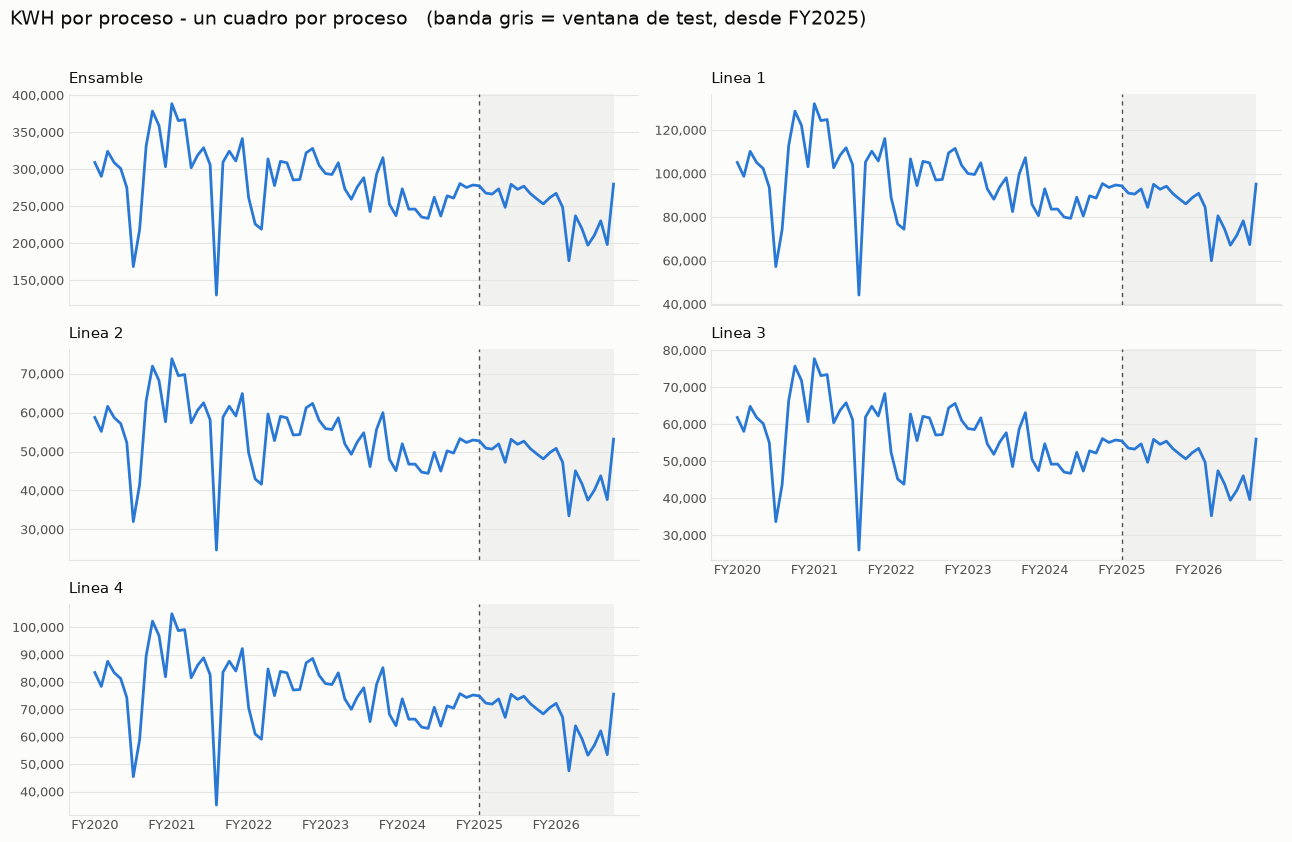

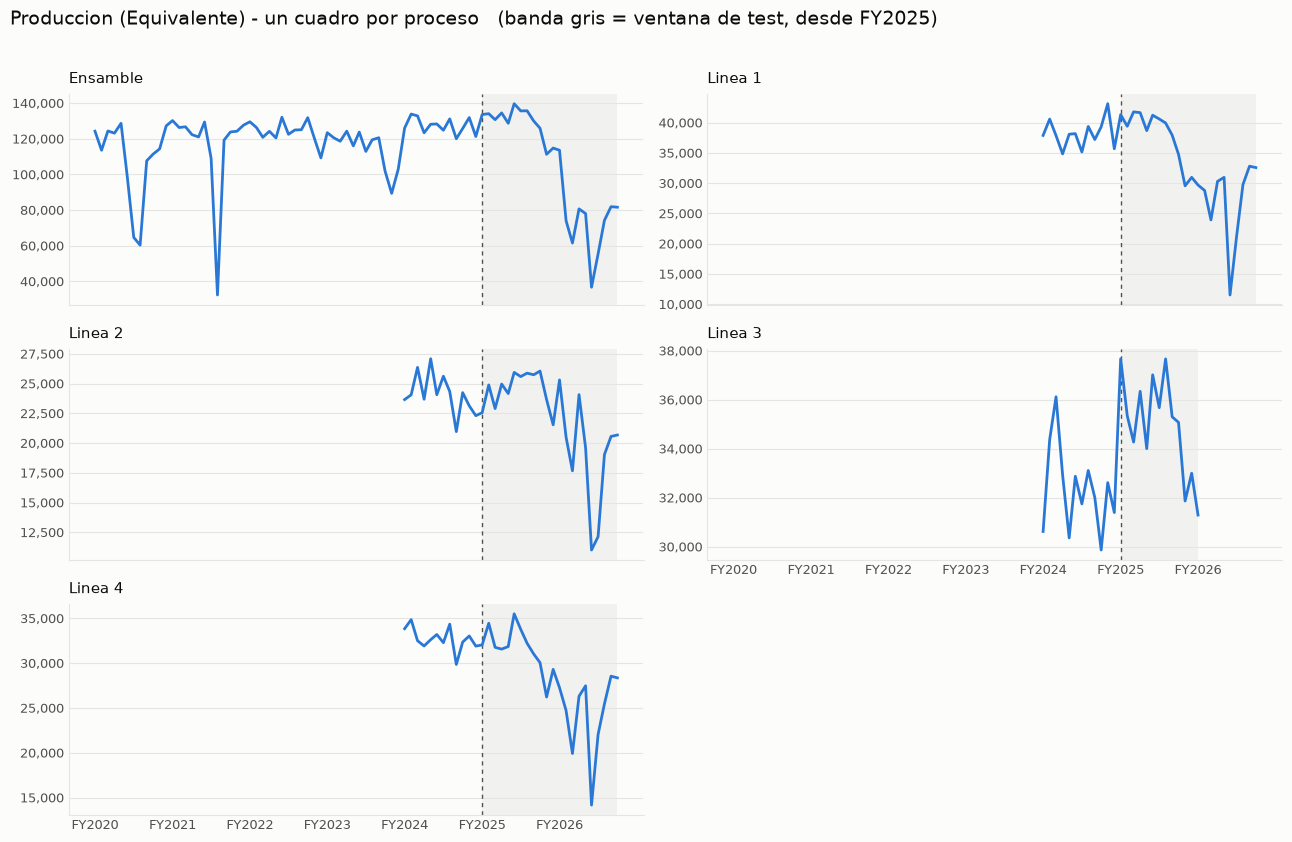

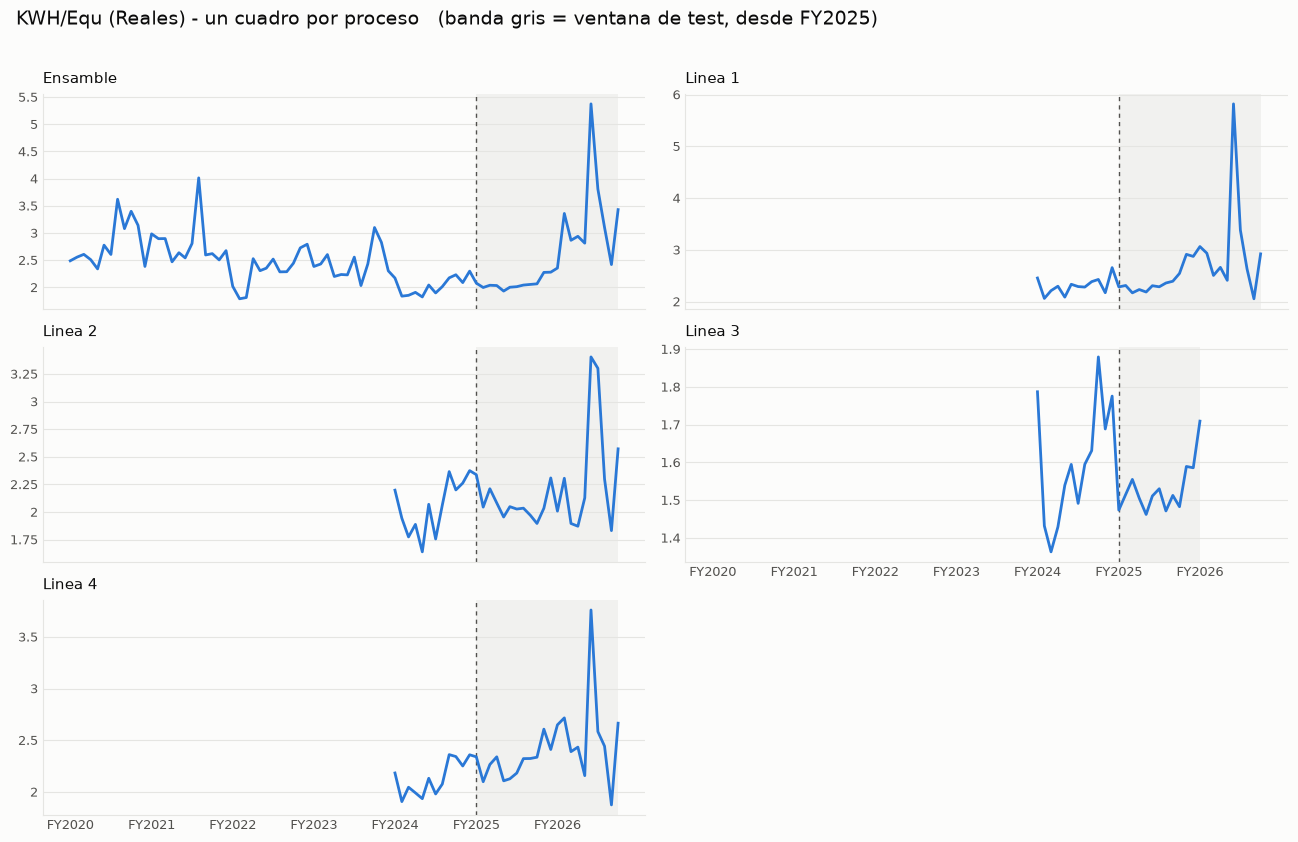

In [168]:
# Paleta validada (skill dataviz)
LINEA, SUPERFICIE = "#2a78d6", "#fcfcfb"
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e5e5e2"


def rejilla_procesos(titulo: str) -> tuple[plt.Figure, np.ndarray]:
    """Rejilla 3x2 con un cuadro por proceso (5 procesos, la 6a casilla se oculta)."""
    fig, axes = plt.subplots(3, 2, figsize=(13, 8.5), facecolor=SUPERFICIE, sharex=True)
    fig.suptitle(
        f"{titulo}   {NOTA_TEST}",
        fontsize=14,
        color=TINTA,
        x=0.01,
        ha="left",
        y=0.985,
    )
    for ax in axes.ravel():
        ax.set_facecolor(SUPERFICIE)
        ax.grid(axis="y", color=GRILLA, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color(GRILLA)
        ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
        ax.yaxis.set_major_formatter(
            lambda v, _: f"{v:,.0f}" if abs(v) >= UMBRAL_MILES else f"{v:,.3g}"
        )
    axes.ravel()[-1].set_visible(False)
    # La casilla oculta era la que llevaba las fechas de la columna derecha: se le
    # devuelven al ultimo cuadro visible de esa columna
    axes[-2, -1].tick_params(labelbottom=True)
    return fig, axes


# Una figura por variable; dentro, un cuadro por proceso
for var in VARS_PROC:
    tabla = series_proc[var]
    fig, axes = rejilla_procesos(f"{var} - un cuadro por proceso")
    for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
        s = tabla[proc].replace(0, np.nan)  # el cero aqui es 'sin produccion registrada'
        ax.plot(s.index, s, color=LINEA, linewidth=2, zorder=3)
        ax.set_title(proc, fontsize=10.5, color=TINTA, loc="left", pad=8)
    # sharex=True: todos los cuadros comparten el eje, se sombrea una vez por eje
    for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
        s = tabla[proc].replace(0, np.nan).dropna()
        if not s.empty:
            marcar_test(ax, s.index[0], s.index[-1])
    eje_fiscal(axes[0, 0], tabla.index[0], tabla.index[-1])  # eje compartido
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

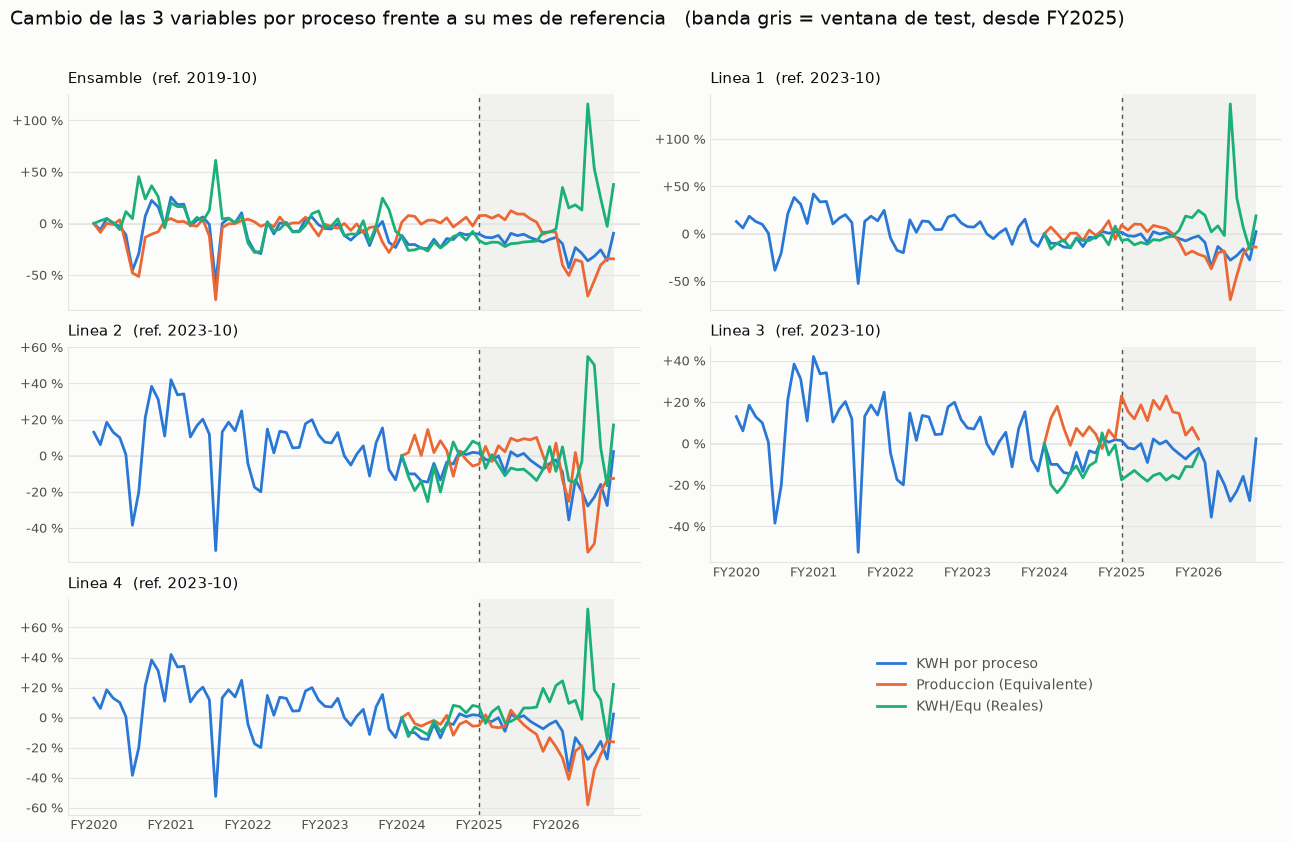

In [169]:
# Cuarta figura: un cuadro por proceso con las 3 variables como cambio porcentual,
# unica forma de verlas juntas (escalas de ~10^5, ~10^4 y ~2)
C_ENERGIA, C_EQUIV, C_RAZON = "#2a78d6", "#eb6834", "#1baf7a"

fig, axes = rejilla_procesos("Cambio de las 3 variables por proceso frente a su mes de referencia")
for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    por_variable = {var: series_proc[var][proc].replace(0, np.nan).dropna() for var in VARS_PROC}
    # Una sola referencia por cuadro: el primer mes en que existen las tres variables
    mes_ref = pd.concat(por_variable, axis=1).dropna().index[0]
    for (var, s), color in zip(por_variable.items(), [C_ENERGIA, C_EQUIV, C_RAZON], strict=True):
        cambio = 100 * (s / s[mes_ref] - 1)
        ax.plot(s.index, cambio, color=color, linewidth=2, label=var, zorder=3)
    ax.axhline(0, color=GRILLA, linewidth=1.2, zorder=1)
    ax.yaxis.set_major_formatter(rotulo_cambio)
    ax.set_title(f"{proc}  (ref. {mes_ref:%Y-%m})", fontsize=10.5, color=TINTA, loc="left", pad=8)

for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    vistos = [series_proc[v][proc].replace(0, np.nan).dropna() for v in VARS_PROC]
    vistos = [s for s in vistos if not s.empty]
    if vistos:
        marcar_test(ax, min(s.index[0] for s in vistos), max(s.index[-1] for s in vistos))
historia_proc = series_proc[VARS_PROC[0]].index
eje_fiscal(axes[0, 0], historia_proc[0], historia_proc[-1])  # eje compartido

# La leyenda va en la casilla vacia de la rejilla, donde no tapa ninguna serie
manijas, rotulos = axes.ravel()[0].get_legend_handles_labels()
fig.legend(
    manijas,
    rotulos,
    loc="center",
    bbox_to_anchor=(0.76, 0.19),
    frameon=False,
    fontsize=10,
    labelcolor=TINTA_SUAVE,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [170]:
# Metricas explicitas del resumen de abajo
filas = []
for proc in PROCESOS:
    es_proc = df_ensamble["Proceso"] == proc
    fila = {
        "proceso": proc,
        # Indice: la fraccion de la energia de planta que se le asigna a cada proceso
        "indice_min": df_ensamble.loc[es_proc, "Indice"].min(),
        "indice_max": df_ensamble.loc[es_proc, "Indice"].max(),
    }
    for var in VARS_PROC:
        s = series_proc[var][proc].replace(0, np.nan).dropna()
        fila[f"{var} | meses"] = len(s)
        fila[f"{var} | desde"] = s.index.min().strftime("%Y-%m") if len(s) else "-"
        fila[f"{var} | hasta"] = s.index.max().strftime("%Y-%m") if len(s) else "-"
    filas.append(fila)

metricas_series_proc = pd.DataFrame(filas)

# La energia por proceso no se mide: es la energia de planta por ese Indice
reparto = df_ensamble["Indice"] * df_ensamble["KWH"]
error_reparto = (
    (reparto - df_ensamble["KWH por proceso"]).abs() / df_ensamble["KWH por proceso"]
).max()
indice_lineas = metricas_series_proc.loc[
    metricas_series_proc["proceso"] != "Ensamble", "indice_max"
]
print(f"KWH por proceso = Indice x KWH -> error relativo maximo {error_reparto:.1e}")
print(f"los Indice de las lineas suman {indice_lineas.sum():.2f}")

# Que variables cambian de un proceso a otro dentro del mismo mes
mes_proc = df_ensamble["Fecha"].dt.to_period("M")
varia = df_ensamble.groupby(mes_proc)[num_cols].nunique().gt(1).sum()
print("meses en que la variable difiere entre procesos:")
print(varia.to_string())

metricas_series_proc

KWH por proceso = Indice x KWH -> error relativo maximo 6.4e-16
los Indice de las lineas suman 1.00
meses en que la variable difiere entre procesos:
Indice                      82
KWH                          0
KWH por proceso             82
Produccion (Equivalente)    34
KWH/Equ (Reales)            82
KWH/Equ (Presupuesto)       10
Costo por KWH                0
Costo total KWH             24


,proceso,indice_min,indice_max,KWH por proceso | meses,KWH por proceso | desde,KWH por proceso | hasta,Produccion (Equivalente) | meses,Produccion (Equivalente) | desde,Produccion (Equivalente) | hasta,KWH/Equ (Reales) | meses,KWH/Equ (Reales) | desde,KWH/Equ (Reales) | hasta
0,Ensamble,1.00,1.00,82,2019-10,2026-07,82,2019-10,2026-07,82,2019-10,2026-07
1,Linea 1,0.34,0.34,82,2019-10,2026-07,34,2023-10,2026-07,34,2023-10,2026-07
2,Linea 2,0.19,0.19,82,2019-10,2026-07,34,2023-10,2026-07,34,2023-10,2026-07
3,Linea 3,0.20,0.20,82,2019-10,2026-07,25,2023-10,2025-10,25,2023-10,2025-10
4,Linea 4,0.27,0.27,82,2019-10,2026-07,34,2023-10,2026-07,34,2023-10,2026-07


### Resumen: series por proceso

- **La energia por linea no se mide, se reparte.** `KWH por proceso` es exactamente
  `Indice x KWH` (error relativo maximo 6.4e-16) y el `Indice` de cada linea no cambia en
  toda la historia: 0.34, 0.19, 0.20 y 0.27, que suman 1.00. Por eso los cuadros de energia
  de las cuatro lineas tienen la misma forma que el de planta.
- **La produccion por linea si es un dato propio**, pero solo desde 2023-10: 34 meses
  frente a los 82 de `Ensamble`.
- **`Linea 3` deja de producir.** Tiene 25 meses con produccion y el ultimo es 2025-10; las
  otras tres llegan a 2026-07.
- **Aqui cambian de un proceso a otro mas variables que en OREC**: ademas de las tres
  graficadas, `Indice` (los 82 meses), `Costo total KWH` (24) y `KWH/Equ (Presupuesto)`
  (10). Solo `KWH` y `Costo por KWH` son cifras de planta repetidas en las 5 filas.

## Crecimiento de la energia por proceso

Misma descomposicion que a nivel de planta, ahora un cuadro por proceso. La ventana de
suavizado se adapta a la cobertura: **12 meses para `Ensamble`** y **3 meses para las
lineas**, que solo reportan produccion desde 2023-10.

In [171]:
# Ensamble reutiliza el indice ya calculado en la seccion de planta (`idx`), para que no
# existan dos cifras distintas de lo mismo en el notebook. Las lineas se calculan aparte
# con ventana de 3 meses, desde el primer mes con produccion registrada.
VENTANA_PLANTA, VENTANA_LINEA = 12, 3

crecimiento = {
    "Ensamble": idx[["Energia (KWH)", "Equivalentes", "KWH/Equ"]].rename(
        columns={"Energia (KWH)": "Energia"}
    )
}

for proc in [x for x in PROCESOS if x != "Ensamble"]:
    e = series_proc["KWH por proceso"][proc]
    # Produccion 0 = linea detenida. Se deja como faltante: si entra a la media movil,
    # la ventana llega a cero y la razon energia/produccion divide por el.
    q = series_proc["Produccion (Equivalente)"][proc].replace(0, np.nan)
    inicio = q.dropna().index.min()  # desde que se mide produccion en esta linea
    e = e.loc[inicio:].rolling(VENTANA_LINEA).mean()
    q = q.loc[inicio:].rolling(VENTANA_LINEA).mean()
    comun = e.dropna().index.intersection(q.dropna().index)
    e, q = e.loc[comun], q.loc[comun]
    r = e / q
    crecimiento[proc] = pd.DataFrame(
        {
            "Energia": 100 * e / e.iloc[0],
            "Equivalentes": 100 * q / q.iloc[0],
            "KWH/Equ": 100 * r / r.iloc[0],
        }
    )

filas = []
for proc, tabla in crecimiento.items():
    produccion = series_proc["Produccion (Equivalente)"][proc]
    detenida = produccion == 0  # meses con registro de produccion igual a cero
    filas.append(
        {
            "proceso": proc,
            "ventana_meses": VENTANA_PLANTA if proc == "Ensamble" else VENTANA_LINEA,
            "puntos": len(tabla),
            "desde": tabla.index.min().strftime("%Y-%m"),
            "hasta": tabla.index.max().strftime("%Y-%m"),
            "energia_idx": tabla["Energia"].iloc[-1],
            "equivalentes_idx": tabla["Equivalentes"].iloc[-1],
            "kwh_equ_idx": tabla["KWH/Equ"].iloc[-1],
            # Energia que se le asigna en meses en que no produjo nada
            "meses_sin_produccion": int(detenida.sum()),
            "kwh_asignados_sin_produccion": series_proc["KWH por proceso"][proc][detenida].sum(),
        }
    )
metricas_crecimiento_proc = pd.DataFrame(filas).round(1)

# La identidad combinada tiene que cerrar en cada proceso
assert all(
    np.allclose(t["KWH/Equ"], 100 * t["Energia"] / t["Equivalentes"]) for t in crecimiento.values()
), "la identidad no cierra en algun proceso"
metricas_crecimiento_proc

,proceso,ventana_meses,puntos,desde,hasta,energia_idx,equivalentes_idx,kwh_equ_idx,meses_sin_produccion,kwh_asignados_sin_produccion
0,Ensamble,12,71,2020-09,2026-07,77.9,74.2,105.0,0,0.0
1,Linea 1,3,32,2023-12,2026-07,92.5,81.8,113.1,0,0.0
2,Linea 2,3,32,2023-12,2026-07,92.5,81.4,113.7,0,0.0
3,Linea 3,3,23,2023-12,2025-10,102.1,95.1,107.4,9,399614.8
4,Linea 4,3,32,2023-12,2026-07,92.5,81.4,113.6,0,0.0


In [172]:
crecimiento.keys()

dict_keys(['Ensamble', 'Linea 1', 'Linea 2', 'Linea 3', 'Linea 4'])

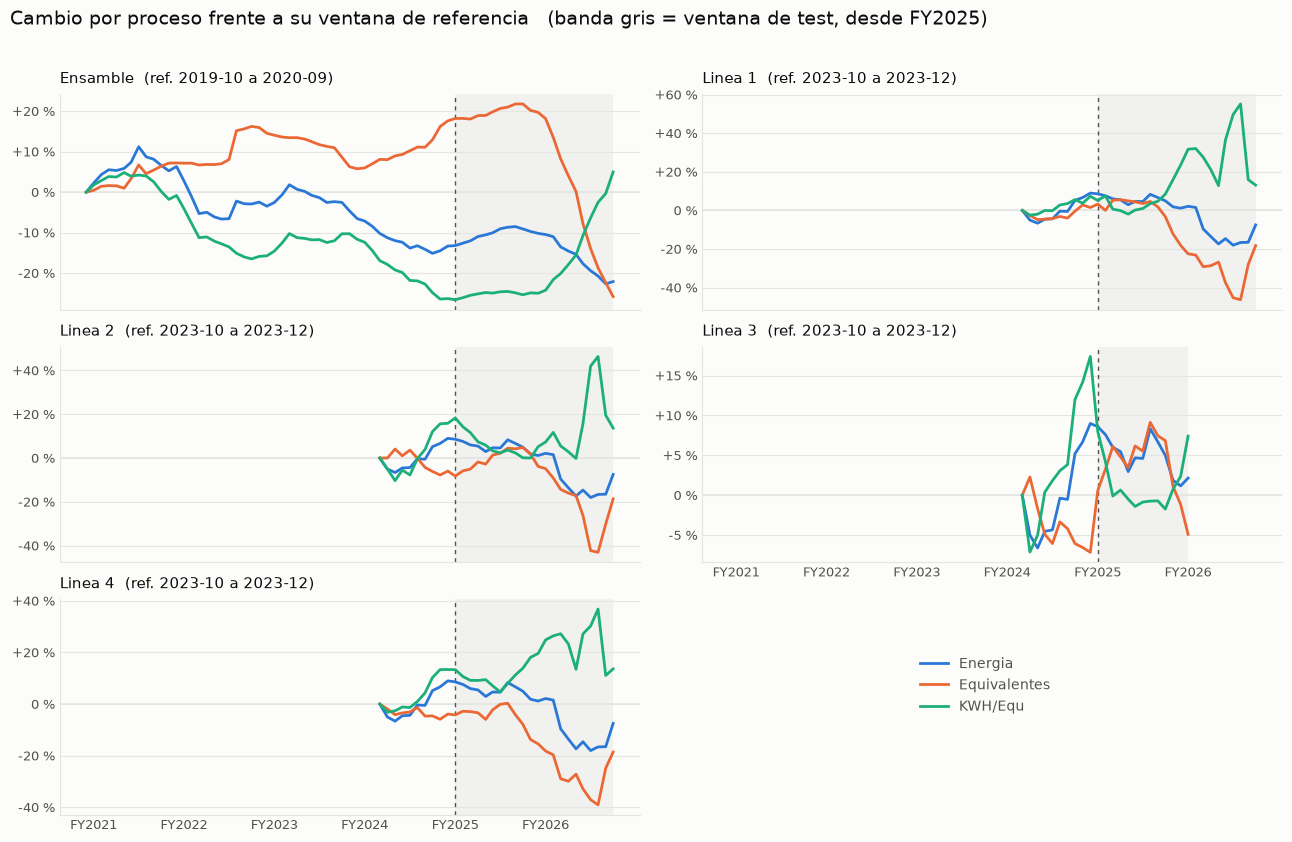

In [173]:
fig, axes = rejilla_procesos("Cambio por proceso frente a su ventana de referencia")
for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    tabla = crecimiento[proc]
    for col, color in zip(
        ["Energia", "Equivalentes", "KWH/Equ"], [C_ENERGIA, C_EQUIV, C_RAZON], strict=False
    ):
        ax.plot(tabla.index, tabla[col] - 100, color=color, linewidth=2, label=col, zorder=3)
    ax.axhline(0, color=GRILLA, linewidth=1.2, zorder=1)
    ax.yaxis.set_major_formatter(rotulo_cambio)
    # cada panel termina en una fecha distinta (Linea 3 deja de producir en 2025)
    marcar_test(ax, tabla.index[0], tabla.index[-1])
    ventana = VENTANA_PLANTA if proc == "Ensamble" else VENTANA_LINEA
    # La referencia es la primera ventana movil del cuadro: los meses que cierran en
    # su primer punto
    desde_ref = tabla.index[0] - pd.DateOffset(months=ventana - 1)
    ax.set_title(
        f"{proc}  (ref. {desde_ref:%Y-%m} a {tabla.index[0]:%Y-%m})",
        fontsize=10.5,
        color=TINTA,
        loc="left",
        pad=8,
    )
# El eje es compartido: se rotula una vez, con el rango de todos los cuadros
eje_fiscal(
    axes[0, 0],
    min(t.index[0] for t in crecimiento.values()),
    max(t.index[-1] for t in crecimiento.values()),
)

# La leyenda va en la casilla vacia de la rejilla, donde no tapa ninguna serie
manijas, rotulos = axes.ravel()[0].get_legend_handles_labels()
fig.legend(
    manijas,
    rotulos,
    loc="center",
    bbox_to_anchor=(0.76, 0.19),
    frameon=False,
    fontsize=10,
    labelcolor=TINTA_SUAVE,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Resumen: crecimiento por proceso

| proceso | energia | equivalentes | `KWH/Equ` |
|---|---|---|---|
| `Ensamble` (planta, 12m) | 77.9 | 74.2 | **105.0** |
| `Linea 1` | 92.5 | 81.8 | 113.1 |
| `Linea 2` | 92.5 | 81.4 | 113.7 |
| `Linea 3` (hasta 2025-10) | 102.1 | 95.1 | 107.4 |
| `Linea 4` | 92.5 | 81.4 | 113.6 |

- **El indice de energia es el mismo en las lineas 1, 2 y 4 (92.5)** porque su energia es
  una fraccion fija de la de planta. Lo unico que las distingue es la produccion.
- **Las tres perdieron produccion** (indices de 81.4 a 81.8), y por eso su energia por
  equivalente sube a entre 113.1 y 113.7.
- **`Linea 3` se detiene**: 9 meses con produccion cero, en los que se le siguieron
  asignando 399,614.8 kWh. Con un reparto fijo no se puede saber si esa energia la consumio
  de verdad `Linea 3` o las otras lineas, asi que el `KWH/Equ` por linea deja de ser fiable
  despues de 2025-10, su ultimo mes con produccion (puede que sea un error de imputacion humano).
- Las ventanas no son comparables entre si: `Ensamble` cubre 2020-09 a 2026-07 con ventana
  de 12 meses y las lineas desde 2023-12 con ventana de 3.



En general la planta y el desgloce por linea muestran como se bajo la producción y el consumo, sin embargo la producción baja mas rapido que el consumo de ahí que `KWH/Equ` aumente, esto es un posible problema en el cual se debe ahondar mas para buscar sus causas.

## Estacionalidad, tendencia y autocorrelacion

Se analizan las tres series mensuales de planta (fila `Ensamble`): energia, equivalentes y
`KWH/Equ`. La energia por linea es la de planta por un `Indice` fijo, asi que no aporta una
serie distinta, y la produccion por linea solo tiene 34 meses: menos de 3 observaciones por
mes del anio, muy poco para una prueba de estacionalidad.

Cada prueba se calcula en dos ventanas: **toda la historia** y **solo train** (hasta
2024-09). La segunda es la que puede usar un modelo; la primera muestra cuanto cambia el
diagnostico al incluir FY2025-FY2026.

In [174]:
ALFA = 0.05  # nivel de significancia de todas las pruebas de la seccion
PERIODO = 12  # meses de un ciclo estacional
Z_CRITICO = stats.norm.ppf(1 - ALFA / 2)  # 1.96: ancho de la banda de ruido blanco

# Las tres series de planta, sobre el indice mensual que ya tiene `planta`
series_ts = {
    "Energia (KWH)": planta["KWH por proceso"],
    "Equivalentes": planta["Produccion (Equivalente)"],
    "KWH/Equ": planta["KWH por proceso"] / planta["Produccion (Equivalente)"],
}


def ventanas(s: pd.Series) -> dict[str, pd.Series]:
    """La serie completa y su tramo de train (antes del corte del split)."""
    return {"historia": s, "train": s[s.index < CORTE_TS]}


def sin_tendencia(s: pd.Series) -> pd.Series:
    """Razon entre la serie y su media movil centrada de 12 meses, en base 100."""
    # Una media de 12 meses cae entre dos meses; promediar dos consecutivas (2x12) la
    # centra en un mes. Se pierden 6 meses en cada extremo.
    tendencia = s.rolling(PERIODO, center=True).mean().rolling(2).mean().shift(-1)
    return (100 * s / tendencia).dropna()


def kruskal_por_grupo(valores: pd.Series, grupos: pd.Index) -> dict[str, float]:
    """Kruskal-Wallis de `valores` entre `grupos`, con su tamano de efecto eta2."""
    muestras = [g.to_numpy() for _, g in valores.groupby(grupos)]
    h, p = stats.kruskal(*muestras)
    n, k = len(valores), len(muestras)
    # eta2 = (H - k + 1) / (n - k): parte de la variabilidad de rangos que explican los
    # grupos. Bajo H0 ronda cero y puede salir negativa, por eso se acota en 0.
    return {"grupos": k, "n": n, "H": h, "p_valor": p, "eta2": max(0.0, (h - k + 1) / (n - k))}


resumen_ventanas = pd.DataFrame(
    [
        {
            "ventana": ventana,
            "meses": len(tramo),
            "desde": f"{tramo.index[0]:%Y-%m}",
            "hasta": f"{tramo.index[-1]:%Y-%m}",
            "observaciones por mes del anio (min)": tramo.groupby(tramo.index.month).size().min(),
            "sin tendencia: meses": len(sin_tendencia(tramo)),
        }
        for ventana, tramo in ventanas(series_ts["Energia (KWH)"]).items()
    ]
)
resumen_ventanas

,ventana,meses,desde,hasta,observaciones por mes del anio (min),sin tendencia: meses
0,historia,82,2019-10,2026-07,6,70
1,train,60,2019-10,2024-09,5,48


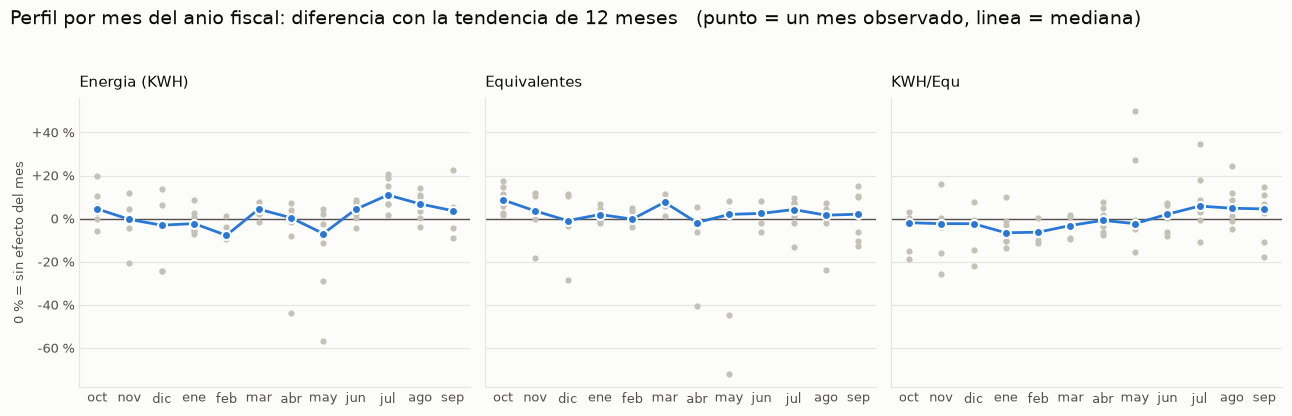

In [175]:
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
# Los mismos meses en el orden del anio fiscal: de octubre a septiembre
MESES_FISCAL = MESES[MES_INICIO_FISCAL - 1 :] + MESES[: MES_INICIO_FISCAL - 1]
OBSERVACION = "#c3c2b7"  # gris de contexto: lo que no es el dato principal


def estilo_eje(ax: plt.Axes) -> None:
    """Superficie, grilla horizontal y ejes recesivos, como el resto del notebook."""
    ax.set_facecolor(SUPERFICIE)
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)


def rotulo_eje(valor: float, _posicion: float) -> str:
    """Miles con separador y sin decimales; valores chicos con 3 cifras significativas."""
    return f"{valor:,.0f}" if abs(valor) >= UMBRAL_MILES else f"{valor:,.3g}"


def perfil_por_grupo(
    ax: plt.Axes, valores: pd.Series, grupos: pd.Index, rotulos: list[str]
) -> None:
    """Dibuja cada observacion de un grupo y une las medianas de los grupos."""
    medianas = valores.groupby(grupos).median()
    posicion = {grupo: i for i, grupo in enumerate(medianas.index)}
    ax.scatter(
        [posicion[g] for g in grupos], valores, s=20, color=OBSERVACION, linewidths=0, zorder=2
    )
    ax.plot(
        range(len(medianas)),
        medianas.to_numpy(),
        color=LINEA,
        linewidth=2,
        marker="o",
        markersize=6.5,
        markeredgecolor=SUPERFICIE,
        markeredgewidth=1.5,
        zorder=3,
    )
    ax.set_xticks(range(len(medianas)), rotulos)
    estilo_eje(ax)


# Estacionalidad: se compara cada mes del anio contra los demas, ya sin la tendencia
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), facecolor=SUPERFICIE, sharey=True)
fig.suptitle(
    "Perfil por mes del anio fiscal: diferencia con la tendencia de 12 meses"
    "   (punto = un mes observado, linea = mediana)",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.98,
)
for ax, (nombre, s) in zip(axes, series_ts.items(), strict=True):
    relativo = sin_tendencia(s)
    # Posicion del mes dentro del anio fiscal: octubre = 0, septiembre = 11
    mes_fiscal = (relativo.index.month - MES_INICIO_FISCAL) % PERIODO
    # sin_tendencia viene en base 100: se dibuja la diferencia con la tendencia
    perfil_por_grupo(ax, relativo - 100, mes_fiscal, MESES_FISCAL)
    ax.axhline(0, color=TINTA_SUAVE, linewidth=1, zorder=1)
    ax.yaxis.set_major_formatter(rotulo_cambio)
    ax.set_title(nombre, fontsize=10.5, color=TINTA, loc="left", pad=8)
axes[0].set_ylabel("0 % = sin efecto del mes", fontsize=9, color=TINTA_SUAVE)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [176]:
# Metricas explicitas del resumen de abajo
filas = []
for nombre, s in series_ts.items():
    for ventana, tramo in ventanas(s).items():
        for version, valores in [("bruta", tramo), ("sin tendencia", sin_tendencia(tramo))]:
            prueba = kruskal_por_grupo(valores, valores.index.month)
            filas.append({"serie": nombre, "ventana": ventana, "version": version, **prueba})

metricas_estacionalidad = pd.DataFrame(filas)
# Son 12 pruebas: Holm corrige el p-valor por haber mirado tantas veces
metricas_estacionalidad["p_holm"] = multipletests(
    metricas_estacionalidad["p_valor"], method="holm"
)[1]
metricas_estacionalidad["significativa"] = metricas_estacionalidad["p_holm"] < ALFA

# El mes mas alto y el mas bajo del perfil (mediana de cada mes, toda la historia)
filas = []
for nombre, s in series_ts.items():
    perfil = sin_tendencia(s).groupby(lambda fecha: fecha.month).median()
    filas.append(
        {
            "serie": nombre,
            "mes_pico": MESES[perfil.idxmax() - 1],
            "pico": perfil.max(),
            "mes_valle": MESES[perfil.idxmin() - 1],
            "valle": perfil.min(),
        }
    )
perfil_mensual = pd.DataFrame(filas).round(1)

print(
    f"pruebas: {len(metricas_estacionalidad)} | significativas tras Holm: "
    f"{int(metricas_estacionalidad['significativa'].sum())} | "
    f"p_valor minimo sin corregir: {metricas_estacionalidad['p_valor'].min():.4f}"
)
display(perfil_mensual)
metricas_estacionalidad.round(4)

pruebas: 12 | significativas tras Holm: 0 | p_valor minimo sin corregir: 0.0305


,serie,mes_pico,pico,mes_valle,valle
0,Energia (KWH),jul,111.0,feb,92.2
1,Equivalentes,oct,108.7,abr,98.2
2,KWH/Equ,jul,105.8,ene,93.4


,serie,ventana,version,grupos,n,H,p_valor,eta2,p_holm,significativa
0,Energia (KWH),historia,bruta,12,82,12.2560,0.3447,0.0179,1.0000,False
1,Energia (KWH),historia,sin tendencia,12,70,21.2905,0.0305,0.1774,0.3658,False
2,Energia (KWH),train,bruta,12,60,12.9148,0.2989,0.0399,1.0000,False
3,Energia (KWH),train,sin tendencia,12,48,18.8444,0.0639,0.2179,0.7034,False
4,Equivalentes,historia,bruta,12,82,6.7141,0.8217,0.0000,1.0000,False
5,Equivalentes,historia,sin tendencia,12,70,13.3302,0.2723,0.0402,1.0000,False
6,Equivalentes,train,bruta,12,60,10.4833,0.4875,0.0000,1.0000,False
7,Equivalentes,train,sin tendencia,12,48,14.8342,0.1902,0.1065,1.0000,False
8,KWH/Equ,historia,bruta,12,82,4.8462,0.9384,0.0000,1.0000,False
9,KWH/Equ,historia,sin tendencia,12,70,12.3554,0.3375,0.0234,1.0000,False


### Resumen: estacionalidad

- **Ninguna de las 12 pruebas es significativa tras corregir por comparaciones multiples**
  (Holm). El p-valor mas bajo sin corregir es 0.0305 (energia sin tendencia, toda la
  historia); corregido sube a 0.3658, y en train ya es 0.0639.

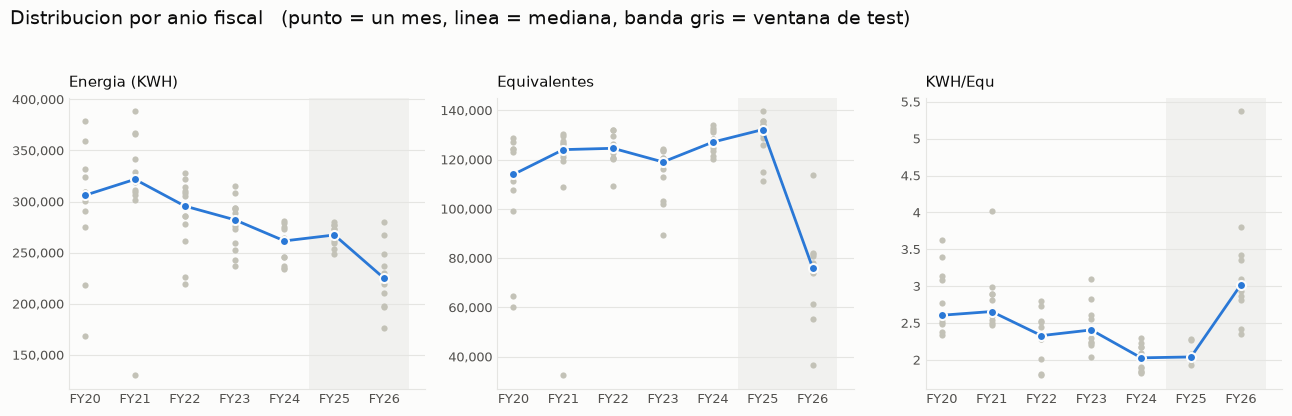

In [177]:
MIN_MESES_ANIO = 6  # un anio fiscal entra a la comparacion si tiene al menos 6 meses


def anios_comparables(s: pd.Series) -> pd.Series:
    """Deja solo los anios fiscales con suficientes meses para compararlos entre si."""
    meses_del_anio = s.groupby(anio_fiscal(s.index)).transform("size")
    return s[meses_del_anio >= MIN_MESES_ANIO]


# Cambio sistematico: se compara cada anio fiscal contra los demas
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), facecolor=SUPERFICIE)
fig.suptitle(
    "Distribucion por anio fiscal"
    "   (punto = un mes, linea = mediana, banda gris = ventana de test)",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.98,
)
for ax, (nombre, s) in zip(axes, series_ts.items(), strict=True):
    tramo = anios_comparables(s)
    fiscal = anio_fiscal(tramo.index)
    anios = sorted(set(fiscal))
    # Tres cuadros por fila: el rotulo completo (FY2025) queda pegado al vecino
    perfil_por_grupo(ax, tramo, fiscal, [rotulo_fiscal(a, corto=True) for a in anios])
    # La ventana de test, sobre un eje de categorias: los anios fiscales desde el corte
    en_test = [i for i, a in enumerate(anios) if a >= FY_TEST]
    ax.axvspan(en_test[0] - 0.5, en_test[-1] + 0.5, color=GRILLA, alpha=0.45, zorder=0, linewidth=0)
    ax.yaxis.set_major_formatter(rotulo_eje)
    ax.set_title(nombre, fontsize=10.5, color=TINTA, loc="left", pad=8)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [178]:
# Metricas explicitas del resumen de abajo
filas = []
for nombre, s in series_ts.items():
    for ventana, tramo in ventanas(s).items():
        comparables = anios_comparables(tramo)
        prueba = kruskal_por_grupo(comparables, anio_fiscal(comparables.index))
        # Mann-Kendall: correlacion de rangos (tau de Kendall) entre la serie y el tiempo.
        # Detecta una tendencia monotona; Kruskal-Wallis detecta cualquier diferencia.
        tau, p_tau = stats.kendalltau(np.arange(len(tramo)), tramo.to_numpy())
        direccion = "sin tendencia monotona"
        if p_tau < ALFA:
            direccion = "sube" if tau > 0 else "baja"
        filas.append(
            {
                "serie": nombre,
                "ventana": ventana,
                **prueba,
                "tau_mann_kendall": tau,
                "p_mann_kendall": p_tau,
                "direccion": direccion,
            }
        )

metricas_tendencia = pd.DataFrame(filas).rename(columns={"grupos": "anios"})
metricas_tendencia["p_holm"] = multipletests(metricas_tendencia["p_valor"], method="holm")[1]
metricas_tendencia["difiere_entre_anios"] = metricas_tendencia["p_holm"] < ALFA

# Donde esta el cambio: la mediana de cada anio fiscal
medianas_anuales = pd.DataFrame(
    {nombre: s.groupby(anio_fiscal(s.index)).median() for nombre, s in series_ts.items()}
).round(2)
medianas_anuales["meses"] = planta.groupby(anio_fiscal(planta.index)).size()

display(medianas_anuales)
metricas_tendencia.round(4)

,Energia (KWH),Equivalentes,KWH/Equ,meses
fiscal year,,,,
2020,306195.0,113962.50,2.61,12
2021,321770.0,124040.50,2.66,12
2022,295658.0,124581.00,2.33,12
2023,282240.5,119035.00,2.41,12
2024,261547.5,127093.02,2.03,12
2025,267345.0,132171.45,2.04,12
2026,224908.0,76166.33,3.02,10


,serie,ventana,anios,n,H,p_valor,eta2,tau_mann_kendall,p_mann_kendall,direccion,p_holm,difiere_entre_anios
0,Energia (KWH),historia,7,82,34.2454,0.0000,0.3766,-0.4273,0.0000,baja,0.0000,True
1,Energia (KWH),train,5,60,19.6585,0.0006,0.2847,-0.3299,0.0002,baja,0.0012,True
2,Equivalentes,historia,7,82,42.2699,0.0000,0.4836,-0.0051,0.9457,sin tendencia monotona,0.0000,True
3,Equivalentes,train,5,60,17.3617,0.0016,0.2429,0.1175,0.1846,sin tendencia monotona,0.0016,True
4,KWH/Equ,historia,7,82,53.3557,0.0000,0.6314,-0.1978,0.0085,baja,0.0000,True
5,KWH/Equ,train,5,60,32.8760,0.0000,0.5250,-0.4203,0.0000,baja,0.0000,True


### Resumen: tendencia y cambio entre años fiscales

- **Las tres series cambian entre años fiscales en toda la historia** (Kruskal-Wallis con p
  de Holm menor que 0.0001, tamano de efecto de 0.3766 a 0.6314). No son series de nivel fijo.
- **La energia baja de forma sostenida**: tau de -0.4273 en toda la historia y -0.3299 en
  train, con la mediana anual pasando de 306,195.0 (FY2020) a 224,908.0 (FY2026).
- **La produccion no tiene tendencia, tiene un quiebre.** Mann-Kendall no ve nada en toda
  la historia (tau -0.0051, p 0.9457) y Kruskal-Wallis si (p menor que 0.0001): la mediana
  se mantiene entre 113,962.50 y 132,171.45 hasta FY2025 y cae a 76,166.33 en FY2026. En
  train difiere entre años fiscales (p 0.0016), pero sin tendencia monotona (tau 0.1175,
  p 0.1846).
- **`KWH/Equ` mejora en train y despues se revierte**: tau de -0.4203 en train y solo
  -0.1978 con toda la historia, porque la mediana baja de 2.61 (FY2020) a 2.03 (FY2024) y
  salta a 3.02 en FY2026.

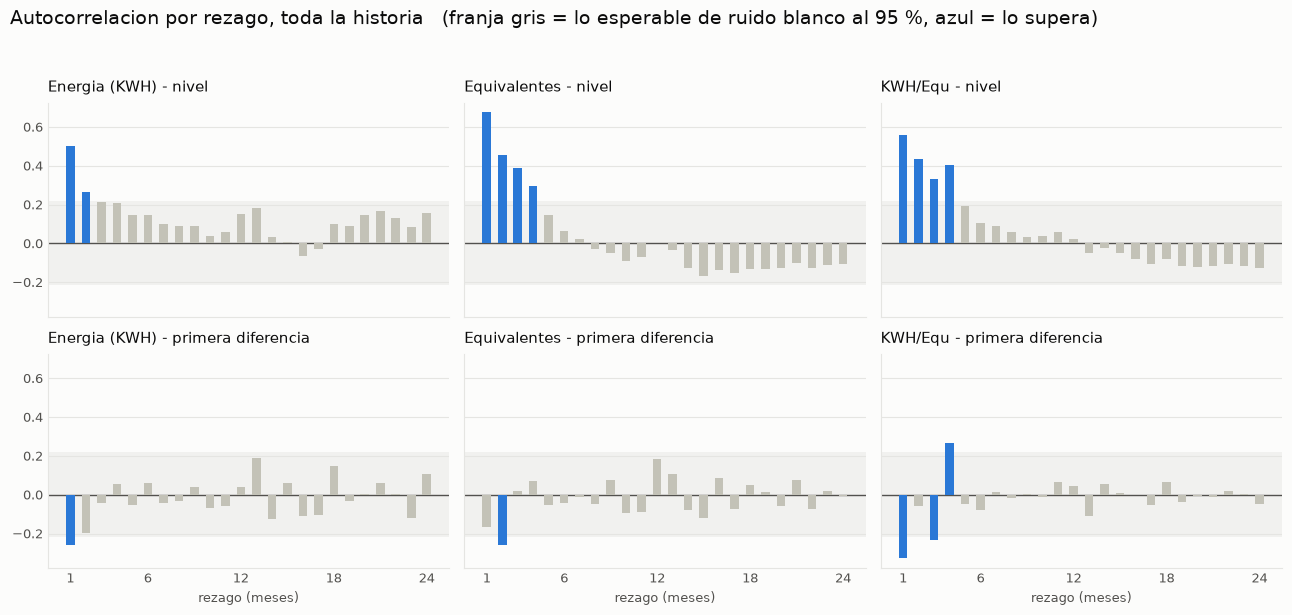

In [179]:
REZAGOS = 24  # dos ciclos anuales
TRANSFORMACIONES = {
    "nivel": lambda s: s,
    "primera diferencia": lambda s: s.diff().dropna(),
}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), facecolor=SUPERFICIE, sharex=True, sharey=True)
fig.suptitle(
    "Autocorrelacion por rezago, toda la historia"
    "   (franja gris = lo esperable de ruido blanco al 95 %, azul = lo supera)",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)
for fila_ejes, (transformacion, aplicar) in zip(axes, TRANSFORMACIONES.items(), strict=True):
    for ax, (nombre, s) in zip(fila_ejes, series_ts.items(), strict=True):
        valores = aplicar(s)
        r = acf(valores, nlags=REZAGOS, fft=False)[1:]  # sin el rezago 0, que siempre es 1
        banda = Z_CRITICO / np.sqrt(len(valores))
        ax.axhspan(-banda, banda, color=GRILLA, alpha=0.45, zorder=0, linewidth=0)
        ax.bar(
            range(1, REZAGOS + 1),
            r,
            width=0.55,
            color=[LINEA if abs(v) > banda else OBSERVACION for v in r],
            zorder=3,
        )
        ax.axhline(0, color=TINTA_SUAVE, linewidth=1, zorder=2)
        ax.set_title(f"{nombre} - {transformacion}", fontsize=10.5, color=TINTA, loc="left", pad=8)
        ax.set_xticks([1, 6, 12, 18, 24])
        estilo_eje(ax)
for ax in axes[-1]:
    ax.set_xlabel("rezago (meses)", fontsize=9, color=TINTA_SUAVE)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [180]:
# Metricas explicitas del resumen de abajo
filas = []
for nombre, s in series_ts.items():
    for ventana, tramo in ventanas(s).items():
        for transformacion, aplicar in TRANSFORMACIONES.items():
            valores = aplicar(tramo)
            r = acf(valores, nlags=REZAGOS, fft=False)
            banda = Z_CRITICO / np.sqrt(len(valores))
            fuera = [k for k in range(1, REZAGOS + 1) if abs(r[k]) > banda]
            # Ljung-Box: H0 = no hay autocorrelacion en los primeros 12 rezagos
            ljung_box = acorr_ljungbox(valores, lags=[PERIODO])
            filas.append(
                {
                    "serie": nombre,
                    "ventana": ventana,
                    "transformacion": transformacion,
                    "n": len(valores),
                    "banda": banda,
                    "r1": r[1],
                    "r12": r[PERIODO],
                    "rezagos_fuera_de_banda": ", ".join(map(str, fuera)) or "ninguno",
                    "ljung_box_p": ljung_box["lb_pvalue"].iloc[0],
                    "ruido_blanco": ljung_box["lb_pvalue"].iloc[0] >= ALFA,
                }
            )

metricas_autocorrelacion = pd.DataFrame(filas)
metricas_autocorrelacion.round(3)

,serie,ventana,transformacion,n,banda,r1,r12,rezagos_fuera_de_banda,ljung_box_p,ruido_blanco
0,Energia (KWH),historia,nivel,82,0.216,0.504,0.151,"1, 2",0.000,False
1,Energia (KWH),historia,primera diferencia,81,0.218,-0.257,0.042,1,0.518,True
2,Energia (KWH),train,nivel,60,0.253,0.418,0.097,1,0.309,True
3,Energia (KWH),train,primera diferencia,59,0.255,-0.237,0.037,ninguno,0.727,True
4,Equivalentes,historia,nivel,82,0.216,0.675,0.001,"1, 2, 3, 4",0.000,False
5,Equivalentes,historia,primera diferencia,81,0.218,-0.165,0.183,2,0.262,True
6,Equivalentes,train,nivel,60,0.253,0.417,0.258,"1, 12",0.035,False
7,Equivalentes,train,primera diferencia,59,0.255,-0.196,0.242,ninguno,0.346,True
8,KWH/Equ,historia,nivel,82,0.216,0.561,0.020,"1, 2, 3, 4",0.000,False
9,KWH/Equ,historia,primera diferencia,81,0.218,-0.328,0.046,"1, 3, 4",0.041,False


### Resumen: autocorrelacion

- **Memoria corta en las tres series.** El rezago 1 vale 0.504 (energia), 0.675
  (equivalentes) y 0.561 (`KWH/Equ`) y la correlacion se apaga en 2 a 4 meses: cada mes se
  parece al anterior, no al de medio año atras.
- **Una diferencia basta.** Despues de diferenciar una vez, Ljung-Box no rechaza el ruido
  blanco en 5 de los 6 casos; la excepcion es `KWH/Equ` con toda la historia (p 0.041). El
  rezago 1 de la diferencia sale negativo (de -0.165 a -0.341), indicio de que diferenciar
  ya es mas de lo necesario.

Es decir que en la mayoria de metricas no hay una autocorrelación demostrable estadisticamente, y cuando la hay basta con tomar la diferencia del periodo con el anterior y se elimina esa autocorrelación.

In [181]:
# Metricas explicitas del resumen de abajo
# ADF y KPSS tienen hipotesis nulas opuestas, por eso se leen juntas:
#   ADF  -> H0: la serie tiene raiz unitaria (no es estacionaria)
#   KPSS -> H0: la serie es estacionaria alrededor de un nivel constante
def diagnostico(p_adf: float, p_kpss: float) -> str:
    """Lectura conjunta de ADF y KPSS al nivel ALFA."""
    sin_raiz_unitaria = p_adf < ALFA
    nivel_constante = p_kpss >= ALFA
    if sin_raiz_unitaria and nivel_constante:
        return "estacionaria"
    if sin_raiz_unitaria:
        return "sin raiz unitaria, pero el nivel cambia"
    if nivel_constante:
        return "no concluyente"
    return "no estacionaria"


filas = []
for nombre, s in series_ts.items():
    for ventana, tramo in ventanas(s).items():
        for transformacion, aplicar in TRANSFORMACIONES.items():
            valores = aplicar(tramo)
            prueba_adf = adfuller(valores, autolag="AIC", result_object=True)
            # KPSS solo tabula p-valores entre 0.01 y 0.10 y avisa cuando el estadistico
            # cae fuera: el aviso se silencia y el limite se documenta en el resumen.
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", InterpolationWarning)
                prueba_kpss = kpss(valores, regression="c", nlags="auto", result_object=True)
            filas.append(
                {
                    "serie": nombre,
                    "ventana": ventana,
                    "transformacion": transformacion,
                    "adf": prueba_adf.statistic,
                    "adf_p": prueba_adf.pvalue,
                    "kpss": prueba_kpss.statistic,
                    "kpss_p": prueba_kpss.pvalue,
                    "diagnostico": diagnostico(prueba_adf.pvalue, prueba_kpss.pvalue),
                }
            )

metricas_estacionariedad = pd.DataFrame(filas)
metricas_estacionariedad.round(3)

,serie,ventana,transformacion,adf,adf_p,kpss,kpss_p,diagnostico
0,Energia (KWH),historia,nivel,-5.125,0.000,0.894,0.010,"sin raiz unitaria, pero el nivel cambia"
1,Energia (KWH),historia,primera diferencia,-5.898,0.000,0.193,0.100,estacionaria
2,Energia (KWH),train,nivel,-4.846,0.000,0.469,0.049,"sin raiz unitaria, pero el nivel cambia"
3,Energia (KWH),train,primera diferencia,-6.691,0.000,0.242,0.100,estacionaria
4,Equivalentes,historia,nivel,-2.398,0.142,0.233,0.100,no concluyente
5,Equivalentes,historia,primera diferencia,-9.029,0.000,0.151,0.100,estacionaria
6,Equivalentes,train,nivel,-4.846,0.000,0.241,0.100,estacionaria
7,Equivalentes,train,primera diferencia,-7.522,0.000,0.163,0.100,estacionaria
8,KWH/Equ,historia,nivel,-2.149,0.225,0.240,0.100,no concluyente
9,KWH/Equ,historia,primera diferencia,-8.868,0.000,0.153,0.100,estacionaria


### Resumen: estacionariedad

- **En train ninguna serie es un paseo aleatorio.** ADF descarta la raiz unitaria en las
  tres (p de 0.002 o menos).
- **Pero solo la produccion tiene nivel estable** (estacionaria en train). En energia y
  `KWH/Equ` KPSS rechaza el nivel constante (p 0.049 y 0.014): no vagan sin rumbo, pero su
  nivel se desplaza, que es la tendencia ya vista.
- **Con FY2025-FY2026 el diagnostico pasa a "no concluyente"** para la produccion y `KWH/Equ`
  (ADF p 0.142 y 0.225): el quiebre del final le quita potencia a las pruebas.
- **La primera diferencia es estacionaria en los 6 casos.**
- KPSS solo tabula p-valores entre 0.01 y 0.10: un 0.100 significa "0.10 o mas" y un 0.010,
  "0.01 o menos".

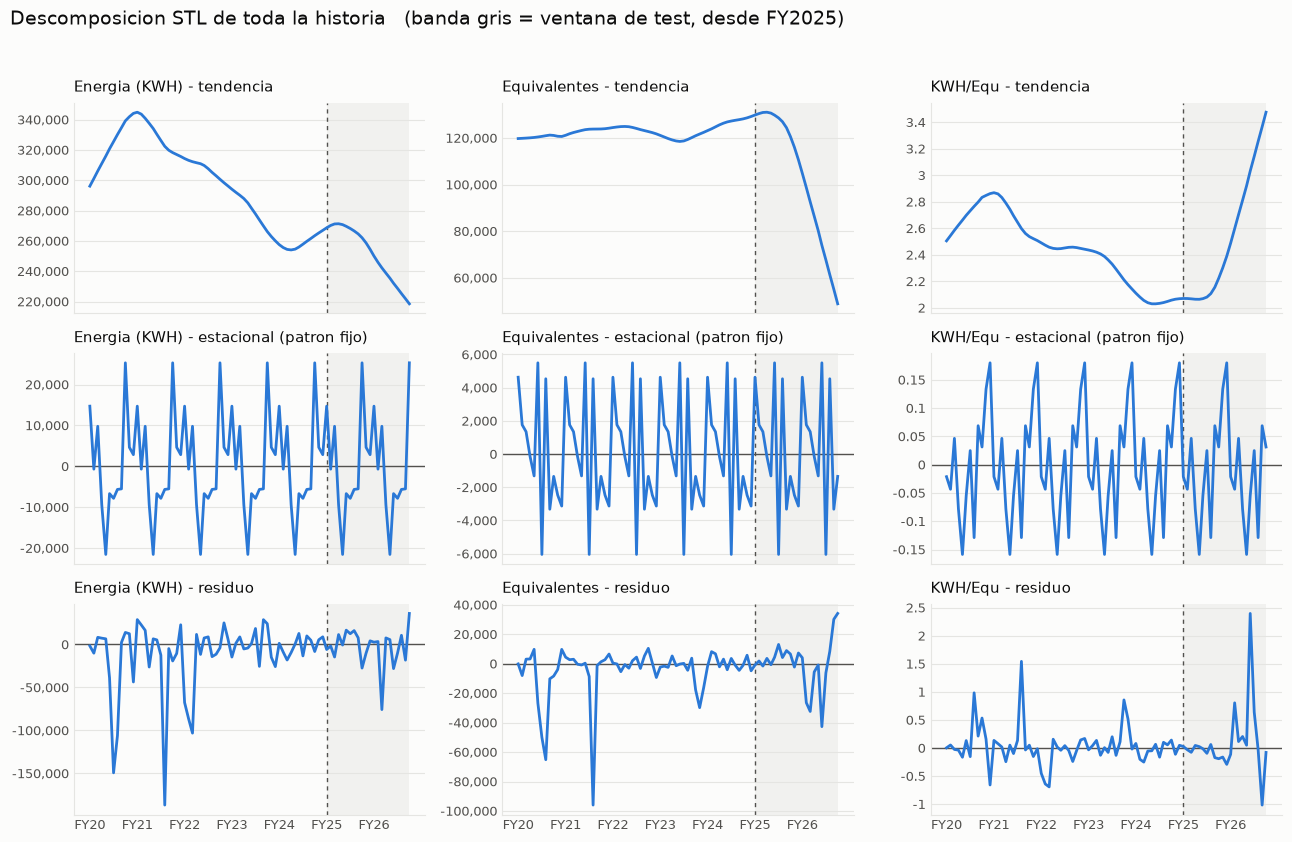

In [182]:
# Descomposicion STL: tendencia + estacional + residuo.
# Con 7 ciclos no se puede estimar un patron estacional que evolucione. El suavizador por
# defecto deja que el efecto de cada mes cambie de anio en anio, y asi absorbe como
# "estacionalidad" los desplomes de abril-mayo de 2020 y mayo de 2021. Por eso se impone un
# patron fijo (grado 0 y una ventana mucho mas larga que la serie: la media de cada mes
# del anio), y el ajuste robusto manda esos meses al residuo, que es donde corresponden.
def descomponer(s: pd.Series) -> DecomposeResult:
    """STL robusta con patron estacional fijo."""
    ventana_fija = 10 * len(s) + 1  # tiene que ser impar
    return STL(s, period=PERIODO, seasonal=ventana_fija, seasonal_deg=0, robust=True).fit()


ajustes_stl = {
    (nombre, ventana): descomponer(tramo)
    for nombre, s in series_ts.items()
    for ventana, tramo in ventanas(s).items()
}

fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), facecolor=SUPERFICIE, sharex=True)
fig.suptitle(
    f"Descomposicion STL de toda la historia   {NOTA_TEST}",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)
for columna, nombre in enumerate(series_ts):
    ajuste = ajustes_stl[nombre, "historia"]
    componentes = {
        "tendencia": ajuste.trend,
        "estacional (patron fijo)": ajuste.seasonal,
        "residuo": ajuste.resid,
    }
    for fila_eje, (componente, valores) in enumerate(componentes.items()):
        ax = axes[fila_eje, columna]
        ax.plot(valores.index, valores, color=LINEA, linewidth=2, zorder=3)
        if componente != "tendencia":
            ax.axhline(0, color=TINTA_SUAVE, linewidth=1, zorder=2)
        marcar_test(ax, valores.index[0], valores.index[-1])
        estilo_eje(ax)
        ax.yaxis.set_major_formatter(rotulo_eje)
        ax.set_title(f"{nombre} - {componente}", fontsize=10.5, color=TINTA, loc="left", pad=8)
historia = series_ts["Energia (KWH)"].index
# Eje compartido; con tres cuadros por fila el rotulo completo (FY2025) se encima
eje_fiscal(axes[0, 0], historia[0], historia[-1], corto=True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [183]:
# Metricas explicitas del resumen de abajo
# Umbral de fuerza estacional a partir del cual se suele diferenciar por estacion
# (Wang, Smith y Hyndman, 2006; es el que usa el paquete feasts)
UMBRAL_ESTACIONAL = 0.64
UMBRAL_ATIPICO = 3  # desviaciones robustas a partir de las que un residuo es atipico
ESCALA_MAD = 1.4826  # vuelve la desviacion absoluta mediana comparable con una desviacion estandar


def fuerza(componente: pd.Series, residuo: pd.Series) -> float:
    """Fuerza de un componente STL: 1 - Var(residuo) / Var(componente + residuo)."""
    return max(0.0, 1 - residuo.var() / (componente + residuo).var())


def rango_intercuartil(x: pd.Series) -> float:
    """Distancia entre los cuartiles 1 y 3: una dispersion que ignora las colas."""
    return x.quantile(0.75) - x.quantile(0.25)


def fuerza_robusta(componente: pd.Series, residuo: pd.Series) -> float:
    """La misma fuerza, con el rango intercuartil en lugar de la varianza."""
    razon = rango_intercuartil(residuo) / rango_intercuartil(componente + residuo)
    return max(0.0, 1 - razon**2)


filas = []
atipicos_historia = {}
for (nombre, ventana), ajuste in ajustes_stl.items():
    serie_ts = series_ts[nombre]
    # El patron fijo, como porcentaje de la mediana de la serie
    patron = 100 * ajuste.seasonal.groupby(lambda fecha: fecha.month).mean() / serie_ts.median()
    desvio = (ajuste.resid - ajuste.resid.median()).abs()
    atipico = desvio > UMBRAL_ATIPICO * ESCALA_MAD * desvio.median()
    if ventana == "historia":
        atipicos_historia[nombre] = ", ".join(
            f"{fecha:%Y-%m}" for fecha in ajuste.resid.index[atipico]
        )
    filas.append(
        {
            "serie": nombre,
            "ventana": ventana,
            "fuerza_tendencia": fuerza(ajuste.trend, ajuste.resid),
            "fuerza_tendencia_robusta": fuerza_robusta(ajuste.trend, ajuste.resid),
            "fuerza_estacional": fuerza(ajuste.seasonal, ajuste.resid),
            "fuerza_estacional_robusta": fuerza_robusta(ajuste.seasonal, ajuste.resid),
            "mes_pico": MESES[patron.idxmax() - 1],
            "pico_pct": patron.max(),
            "mes_valle": MESES[patron.idxmin() - 1],
            "valle_pct": patron.min(),
            "residuos_atipicos": int(atipico.sum()),
        }
    )

metricas_stl = pd.DataFrame(filas)
metricas_stl["estacionalidad_marcada"] = metricas_stl["fuerza_estacional"] >= UMBRAL_ESTACIONAL

# Los meses que el ajuste robusto deja en el residuo (toda la historia)
for nombre, meses_atipicos in atipicos_historia.items():
    print(f"{nombre}: {meses_atipicos}")
metricas_stl.round(2)

Energia (KWH): 2020-04, 2020-05, 2021-05, 2021-10, 2021-11, 2021-12, 2025-12
Equivalentes: 2020-03, 2020-04, 2020-05, 2021-05, 2023-08, 2025-11, 2025-12, 2026-03, 2026-06, 2026-07
KWH/Equ: 2020-05, 2020-07, 2020-09, 2021-05, 2021-11, 2021-12, 2023-07, 2023-08, 2025-11, 2026-03, 2026-04, 2026-06


,serie,ventana,fuerza_tendencia,fuerza_tendencia_robusta,fuerza_estacional,fuerza_estacional_robusta,mes_pico,pico_pct,mes_valle,valle_pct,residuos_atipicos,estacionalidad_marcada
0,Energia (KWH),historia,0.32,0.82,0.11,0.41,jul,9.15,feb,-7.79,7,False
1,Energia (KWH),train,0.20,0.80,0.17,0.42,jul,9.64,feb,-7.80,6,False
2,Equivalentes,historia,0.44,0.66,0.00,0.30,mar,4.46,abr,-4.90,10,False
3,Equivalentes,train,0.08,0.36,0.02,0.51,oct,4.94,sep,-11.08,8,False
4,KWH/Equ,historia,0.45,0.84,0.00,0.39,sep,7.43,feb,-6.55,12,False
5,KWH/Equ,train,0.48,0.81,0.14,0.56,sep,11.46,feb,-8.26,4,False


### Resumen: descomposicion STL

Se ve una fuerte tendencia a la baja en el consumo y prod, junto a una subida en el gasto energetico por equivalente, lo cual respalda los primeros hallazgos del cuaderno, ademas se observa como la descompocición estacional da por resultado un movimiento ruidoso que parece car saltos o tener picos en la mitad del año.

Esto ultimo se ve respaldado por los picos hallados en la tabla resumen de esta sección.

In [184]:
# Todo el diagnostico en una tabla: una fila por serie y ventana
claves = ["serie", "ventana"]
kw_mes = metricas_estacionalidad.query("version == 'sin tendencia'")
en_nivel = "transformacion == 'nivel'"
en_diferencia = "transformacion == 'primera diferencia'"

diagnostico_ts = (
    kw_mes[[*claves, "p_holm", "significativa"]]
    .rename(columns={"p_holm": "kw_mes_p_holm", "significativa": "estacionalidad"})
    .merge(
        metricas_tendencia[[*claves, "difiere_entre_anios", "direccion"]].rename(
            columns={"direccion": "tendencia_monotona"}
        ),
        on=claves,
    )
    .merge(metricas_autocorrelacion.query(en_nivel)[[*claves, "r1", "r12"]], on=claves)
    .merge(
        metricas_autocorrelacion.query(en_diferencia)[[*claves, "ruido_blanco"]].rename(
            columns={"ruido_blanco": "diferencia_es_ruido_blanco"}
        ),
        on=claves,
    )
    .merge(
        metricas_estacionariedad.query(en_nivel)[[*claves, "diagnostico"]].rename(
            columns={"diagnostico": "estacionariedad_en_nivel"}
        ),
        on=claves,
    )
    .merge(metricas_stl[[*claves, "fuerza_estacional", "fuerza_estacional_robusta"]], on=claves)
)
diagnostico_ts.round(3)

,serie,ventana,kw_mes_p_holm,estacionalidad,difiere_entre_anios,tendencia_monotona,r1,r12,diferencia_es_ruido_blanco,estacionariedad_en_nivel,fuerza_estacional,fuerza_estacional_robusta
0,Energia (KWH),historia,0.366,False,True,baja,0.504,0.151,True,"sin raiz unitaria, pero el nivel cambia",0.108,0.408
1,Energia (KWH),train,0.703,False,True,baja,0.418,0.097,True,"sin raiz unitaria, pero el nivel cambia",0.165,0.416
2,Equivalentes,historia,1.000,False,True,sin tendencia monotona,0.675,0.001,True,no concluyente,0.000,0.303
3,Equivalentes,train,1.000,False,True,sin tendencia monotona,0.417,0.258,True,estacionaria,0.021,0.509
4,KWH/Equ,historia,1.000,False,True,baja,0.561,0.020,False,no concluyente,0.000,0.392
5,KWH/Equ,train,1.000,False,True,baja,0.571,0.131,True,"sin raiz unitaria, pero el nivel cambia",0.140,0.558


### Resumen general: que dicen las series

- **No hay estacionalidad demostrable.** Kruskal-Wallis por mes no es significativo en
  ninguna serie ni ventana (p de Holm de 0.366 a 1.000), el rezago 12 no pasa de 0.258 y la
  fuerza estacional clasica no supera 0.165.
- **Si hay cambio sistematico entre años fiscales.** Con toda la historia difieren las tres: la
  energia y `KWH/Equ` bajan, y la produccion no tiene tendencia monotona sino un quiebre.
- **La memoria es de un mes.** El rezago 1 va de 0.417 a 0.675 y la primera diferencia es
  ruido blanco en 5 de los 6 casos.
- **Para modelar**, los datos no piden un termino estacional; si piden el mes anterior y
  algo que siga el nivel (una tendencia o una diferencia).

Se ve que el cambio año a año es una regla en el negocio, sin embargo este cambio se intensifico en este ultimo año. Se debe ahondar mas en porque ocurre eso.

# Comparar presupuesto vs. real

plantear sistema de recomendación con produccion fija, para determinar el consumo optimo que permita alcanzar un presupuesto o comparar con demas años fiscales.

In [185]:
# Presupuesto de planta: el de la fila Ensamble, que es el total (cada linea trae el suyo).
# Solo se registra desde 2025-10 y es un unico valor para todo el anio fiscal.
presupuesto = planta["KWH/Equ (Presupuesto)"]
presupuesto = presupuesto[presupuesto > 0]
fiscal_presupuesto = anio_fiscal(presupuesto.index)

# Si la base cambia y deja de ser un valor fijo dentro de un solo anio fiscal, la recta del
# grafico ya no lo representa: mejor fallar que dibujarla mal
assert presupuesto.nunique() == 1, "el presupuesto de planta ya no es un unico valor"
assert fiscal_presupuesto.nunique() == 1, "el presupuesto cubre mas de un anio fiscal"

FY_PRESUPUESTO = int(fiscal_presupuesto[0])
valor_presupuesto = presupuesto.iloc[0]

# El presupuesto viene en kWh por equivalente y el grafico esta en indice base 100: se
# divide por la misma base con la que se indexo KWH/Equ
base_razon = razon.dropna().iloc[0]
presupuesto_idx = 100 * presupuesto / base_razon
nivel_presupuesto = presupuesto_idx.iloc[0]

print(
    f"presupuesto {rotulo_fiscal(FY_PRESUPUESTO)}: {valor_presupuesto:.4f} KWH/Equ en "
    f"{len(presupuesto)} meses ({presupuesto.index[0]:%Y-%m} a {presupuesto.index[-1]:%Y-%m})"
)
print(f"base de KWH/Equ: {base_razon:.4f} -> indice del presupuesto: {nivel_presupuesto:.2f}")

presupuesto FY2026: 2.0118 KWH/Equ en 10 meses (2025-10 a 2026-07)
base de KWH/Equ: 2.7472 -> indice del presupuesto: 73.23


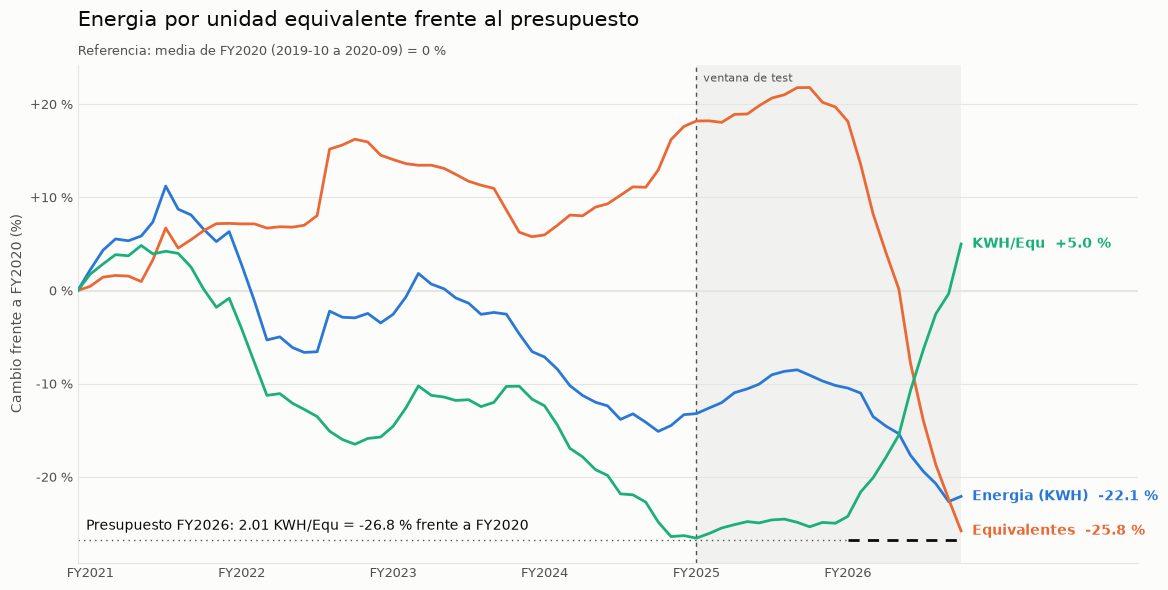

In [186]:
# La misma figura de planta (cambio frente a la referencia, media movil de 12 meses),
# ahora con el presupuesto de KWH/Equ. Las tres series llevan etiqueta directa, asi que
# no hace falta leyenda.
cambio_presupuesto = nivel_presupuesto - 100  # el presupuesto, en la misma escala

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SUPERFICIE)
estilo_eje(ax)

ax.axhline(0, color=GRILLA, linewidth=1.5, zorder=1)
for nombre, color in [
    ("Energia (KWH)", C_ENERGIA),
    ("Equivalentes", C_EQUIV),
    ("KWH/Equ", C_RAZON),
]:
    ax.plot(idx.index, cambio_planta[nombre], color=color, linewidth=2, zorder=3)
    y_final = cambio_planta[nombre].iloc[-1]
    ax.annotate(
        f"{nombre}  {y_final:+.1f} %",
        xy=(idx.index[-1], y_final),
        xytext=(8, 0),
        textcoords="offset points",
        color=color,
        fontsize=10,
        fontweight="bold",
        va="center",
    )

# Presupuesto: trazo marcado solo en los meses en que existe, y una guia fina al mismo nivel
# hacia atras, para leer toda la historia contra el. La guia termina donde empieza el
# trazo marcado, asi no se enciman.
ax.plot(
    [idx.index[0], presupuesto_idx.index[0]],
    [cambio_presupuesto, cambio_presupuesto],
    color=TINTA_SUAVE,
    linewidth=1,
    linestyle=(0, (1, 3)),
    zorder=2,
)
ax.plot(
    presupuesto_idx.index,
    presupuesto_idx - 100,
    color=TINTA,
    linewidth=2,
    linestyle=(0, (4, 3)),
    zorder=4,
)
# La etiqueta va a la izquierda: a la derecha quedaria a un punto de la de Equivalentes
ax.annotate(
    f"Presupuesto {rotulo_fiscal(FY_PRESUPUESTO)}: {valor_presupuesto:.2f} KWH/Equ"
    f" = {cambio_presupuesto:+.1f} % frente a {rotulo_fiscal(base_fiscal)}",
    xy=(idx.index[0], cambio_presupuesto),
    xytext=(6, 5),
    textcoords="offset points",
    color=TINTA,
    fontsize=10,
    va="bottom",
)

marcar_test(ax, idx.index[0], idx.index[-1], etiqueta=True)
eje_fiscal(ax, idx.index[0], idx.index[-1])

ax.set_title(
    "Energia por unidad equivalente frente al presupuesto",
    fontsize=15,
    color=TINTA,
    loc="left",
    pad=28,
)
ax.text(0, 1.02, REFERENCIA_PLANTA, transform=ax.transAxes, fontsize=9.5, color=TINTA_SUAVE)
ax.set_ylabel(f"Cambio frente a {rotulo_fiscal(base_fiscal)} (%)", fontsize=10, color=TINTA_SUAVE)
ax.yaxis.set_major_formatter(rotulo_cambio)
ax.set_xlim(idx.index[0], idx.index[-1] + pd.DateOffset(months=14))

plt.tight_layout()
plt.show()

In [187]:
presupuesto.nunique()

1

In [188]:
# Metricas explicitas del resumen de abajo
# 1) Mes a mes dentro del anio fiscal presupuestado
en_presupuesto = planta.loc[presupuesto.index]
mensual = pd.DataFrame(
    {
        "real": en_presupuesto["KWH por proceso"] / en_presupuesto["Produccion (Equivalente)"],
        "presupuesto": presupuesto,
        "kwh_real": en_presupuesto["KWH por proceso"],
        # Energia que permitia el presupuesto con la produccion que de verdad hubo
        "kwh_presupuesto": presupuesto * en_presupuesto["Produccion (Equivalente)"],
    }
)
mensual["desvio_pct"] = 100 * (mensual["real"] / mensual["presupuesto"] - 1)
mensual["exceso_kwh"] = mensual["kwh_real"] - mensual["kwh_presupuesto"]
mensual.index = mensual.index.strftime("%Y-%m")

sobre = mensual["real"] > mensual["presupuesto"]
exceso = mensual["exceso_kwh"].sum()
print(
    f"meses de {rotulo_fiscal(FY_PRESUPUESTO)} por encima del presupuesto: "
    f"{int(sobre.sum())} de {len(mensual)}"
)
print(
    f"mes mas cercano: {mensual['real'].idxmin()} ({mensual['real'].min():.2f}) | "
    f"mes mas lejano: {mensual['real'].idxmax()} ({mensual['real'].max():.2f})"
)
print(
    f"kWh consumidos: {mensual['kwh_real'].sum():,.0f} | "
    f"kWh que permitia el presupuesto: {mensual['kwh_presupuesto'].sum():,.0f} | "
    f"exceso: {exceso:,.0f} ({100 * exceso / mensual['kwh_real'].sum():.1f} % del consumo)"
)

# Toda la historia, mes a mes, contra el presupuesto de hoy
kwh_equ_mes = planta["KWH por proceso"] / planta["Produccion (Equivalente)"]
print(
    f"meses de toda la historia por debajo del presupuesto: "
    f"{int((kwh_equ_mes < valor_presupuesto).sum())} de {len(kwh_equ_mes)}"
)

# 2) Los niveles del grafico frente al presupuesto. La media de 12 meses es la serie
# dibujada; el acumulado del anio fiscal es la comparacion directa con el presupuesto.
razon_12m = razon.dropna()
acumulado = mensual["kwh_real"].sum() / en_presupuesto["Produccion (Equivalente)"].sum()
referencias = [
    (f"presupuesto {rotulo_fiscal(FY_PRESUPUESTO)}", "-", valor_presupuesto),
    ("mejor media de 12 meses", f"{razon_12m.idxmin():%Y-%m}", razon_12m.min()),
    ("media de 12 meses al cierre de train", f"{en_corte.name:%Y-%m}", razon_12m[en_corte.name]),
    ("media de 12 meses, ultimo dato", f"{razon_12m.index[-1]:%Y-%m}", razon_12m.iloc[-1]),
    (f"{rotulo_fiscal(FY_PRESUPUESTO)} acumulado", mensual.index[-1], acumulado),
]
metricas_presupuesto = pd.DataFrame(
    [
        {
            "medida": medida,
            "hasta": hasta,
            "kwh_equ": valor,
            "indice": 100 * valor / base_razon,
            "vs_presupuesto_pct": 100 * (valor / valor_presupuesto - 1),
        }
        for medida, hasta, valor in referencias
    ]
).round({"kwh_equ": 2, "indice": 2, "vs_presupuesto_pct": 1})

decimales = {"real": 2, "presupuesto": 2, "desvio_pct": 1}
display(mensual.round({columna: decimales.get(columna, 0) for columna in mensual.columns}))
metricas_presupuesto

meses de FY2026 por encima del presupuesto: 10 de 10
mes mas cercano: 2025-10 (2.35) | mes mas lejano: 2026-03 (5.37)
kWh consumidos: 2,265,491 | kWh que permitia el presupuesto: 1,484,321 | exceso: 781,170 (34.5 % del consumo)
meses de toda la historia por debajo del presupuesto: 10 de 82


,real,presupuesto,kwh_real,kwh_presupuesto,desvio_pct,exceso_kwh
Mes_inicio,,,,,,
2025-10,2.35,2.01,267417.0,228464.0,17.1,38953.0
2025-11,3.36,2.01,248572.0,148892.0,66.9,99680.0
2025-12,2.87,2.01,176309.0,123797.0,42.4,52512.0
2026-01,2.94,2.01,237057.0,162320.0,46.0,74737.0
2026-02,2.81,2.01,219512.0,157023.0,39.8,62489.0
2026-03,5.37,2.01,197348.0,73874.0,167.1,123474.0
2026-04,3.81,2.01,210933.0,111476.0,89.2,99457.0
2026-05,3.10,2.01,230304.0,149445.0,54.1,80859.0
2026-06,2.42,2.01,198139.0,164814.0,20.2,33325.0


,medida,hasta,kwh_equ,indice,vs_presupuesto_pct
0,presupuesto FY2026,-,2.01,73.23,0.0
1,mejor media de 12 meses,2024-10,2.02,73.43,0.3
2,media de 12 meses al cierre de train,2024-09,2.02,73.70,0.6
3,"media de 12 meses, ultimo dato",2026-07,2.88,104.99,43.4
4,FY2026 acumulado,2026-07,3.07,111.77,52.6


### Resumen: presupuesto frente a lo real

- **El presupuesto de planta es un solo valor**: 2.01 `KWH/Equ` para los 10 meses de FY2026
  (2025-10 a 2026-07), indice 73.23 sobre la base FY2020. (por mes se permite tener un presupuesto de 2.01 `KWH/Equ`)
- **Pide el mejor nivel que la planta ha tenido, y un poco mas.** La mejor media de 12 meses
  (2024-10) fue 2.02, indice 73.43: quedo a 0.3 % del presupuesto, y al cierre de train
  (2024-09) a 0.6 %. Mes a mes, solo 10 de los 82 de la historia estuvieron por debajo.
- **Hoy la planta esta lejos.** La media de 12 meses marca 2.88 (indice 104.99, +43.4 %) y
  el acumulado de FY2026 3.07 (+52.6 %). Los 10 meses del año fiscal superan el presupuesto;
  el mas cercano es 2025-10 (2.35) y el mas lejano 2026-03 (5.37).
- **En energia son 781,170 kWh de mas.** Con la produccion que hubo, el presupuesto permitia
  1,484,321 kWh y se consumieron 2,265,491: el exceso es el 34.5 % del consumo. Esa es la
  brecha que tendria que cerrar un consumo optimo a produccion fija.

## Relacion entre variables

<Axes: >

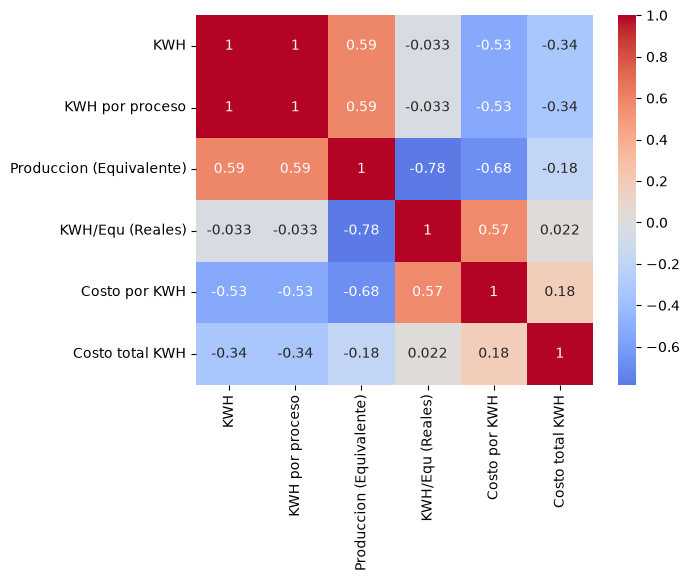

In [189]:
sns.heatmap(
    planta.drop(
        columns=["Año", "Mes", "Proceso", "Indice", "Fecha", "fiscal year", "KWH/Equ (Presupuesto)"]
    )
    .corr(method="pearson")
    .round(3),
    annot=True,
    cmap="coolwarm",
    center=0,
)

## Construir el sistema de recomendacion

### Solo para la plantam

In [190]:
df_train_planta = df_train[df_train["Proceso"] == "Ensamble"].copy()

In [191]:
df_train_planta.drop(columns=["KWH/Equ (Presupuesto)", "Costo por KWH"], inplace=True)

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 9 distinct values across 55 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


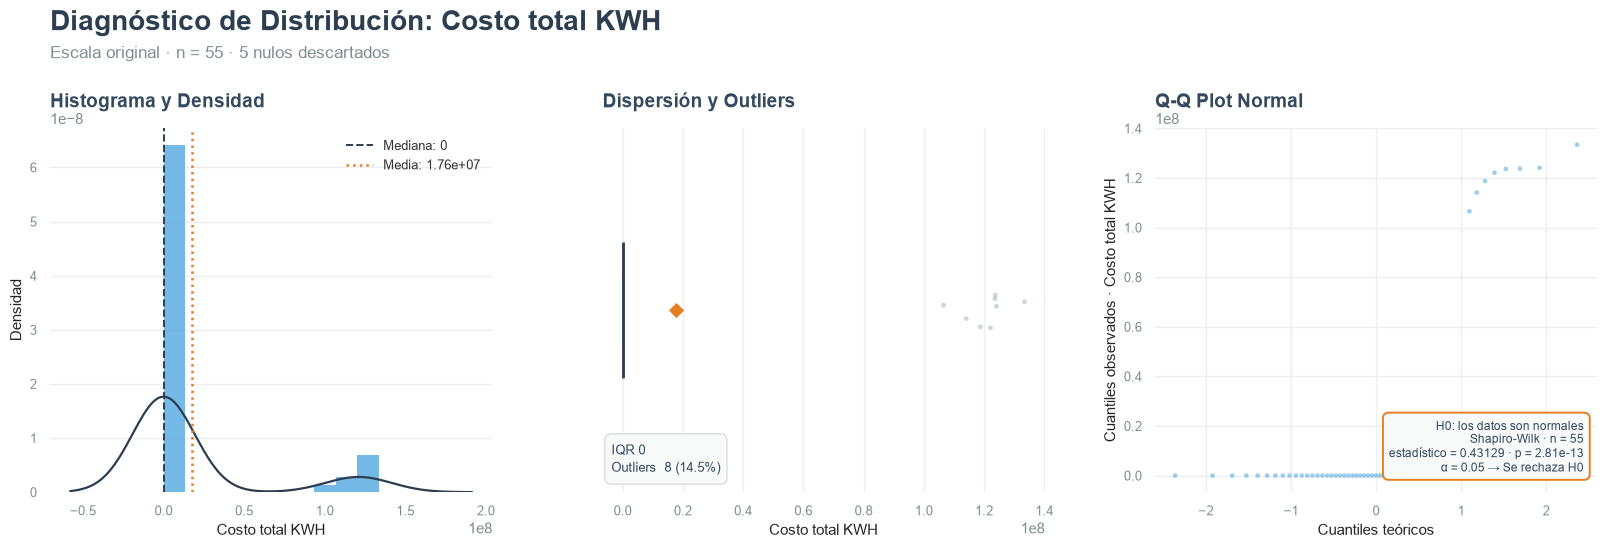

In [192]:
resumen_costo_total = normality_report(df_train_planta, "Costo total KWH")

In [193]:
df_train_planta[df_train_planta.isnull().any(axis=1)]

,Proceso,Indice,KWH,KWH por proceso,KWH/Equ (Reales),Costo total KWH,Fecha,Produccion (Equivalente)
4,Ensamble,1.0,309181,309181.0,2.487978,NaN,2019-10-31,124270.0
9,Ensamble,1.0,290330,290330.0,2.556037,NaN,2019-11-30,113586.0
14,Ensamble,1.0,324206,324206.0,2.606220,NaN,2019-12-31,124397.0
19,Ensamble,1.0,309006,309006.0,2.508715,NaN,2020-01-31,123173.0
24,Ensamble,1.0,300954,300954.0,2.338724,NaN,2020-02-29,128683.0


In [194]:
df_train_planta["Costo total KWH"] = df_train_planta["Costo total KWH"].fillna(
    df_train_planta["Costo total KWH"].mode()[0]
)

df_train_planta.drop(columns=["Indice"], inplace=True)

In [195]:
vif_resume = vif_table(df_train_planta, target_variable="KWH")

In [196]:
vif_resume

,Variable,VIF,descartada,alto
0,Produccion (Equivalente),27.487724,None,True
1,KWH/Equ (Reales),21.357239,None,True
2,KWH por proceso,16.523721,None,True
3,Costo total KWH,1.201679,None,False


In [197]:
df_train_planta.drop(columns=["KWH/Equ (Reales)"], inplace=True)

In [198]:
vif_table(df_train_planta, target_variable="KWH")

,Variable,VIF,descartada,alto
0,KWH por proceso,1.559627,None,False
1,Produccion (Equivalente),1.545352,None,False
2,Costo total KWH,1.191227,None,False


ya que `KWH por proceso` y `Costo total KWH` constituyen una potencial fuga de información se opta por su eliminación.

In [199]:
df_train_planta.drop(columns=["KWH por proceso", "Costo total KWH"], inplace=True)

In [200]:
df_train_planta.shape

(60, 4)

#### Auditoria del split

El modelo que sigue explica `KWH` con la produccion. Antes de ajustarlo se revisa el split
que ya existe, porque se armo con otro objetivo. De la ventana de test solo se leen las
fechas y el numero de filas: ningun valor.

In [201]:
# El guardian de la seccion: nada posterior al corte entra a un ajuste ni a un fold
def solo_train(datos: pd.DataFrame) -> pd.DataFrame:
    """Devuelve `datos` tras comprobar que todas sus fechas son anteriores al corte."""
    fechas = datos["Fecha"] if "Fecha" in datos.columns else datos.index
    assert pd.DatetimeIndex(fechas).max() < CORTE_TS, "hay filas de la ventana de test"
    return datos


def error_relativo(calculado: pd.Series, registrado: pd.Series) -> float:
    """Mayor diferencia relativa entre una columna y la formula que la reconstruye."""
    comparable = calculado.notna() & registrado.notna() & (registrado != 0)
    return float(((calculado - registrado).abs() / registrado.abs())[comparable].max())


TOLERANCIA_IDENTIDAD = 1e-6  # por debajo de esto la formula reproduce la columna
solo_train(df_train)
mes_train = df_train["Fecha"].dt.to_period("M")
mes_test = X_test["Fecha"].dt.to_period("M")  # de test solo se usan las fechas
es_planta_train = df_train["Proceso"] == "Ensamble"
con_produccion = df_train["Produccion (Equivalente)"] > 0

# Las tres columnas que reconstruyen el objetivo, comprobadas como identidades en train
fuga = {
    "KWH por proceso = Indice x KWH": error_relativo(
        df_train["Indice"] * df_train["KWH"], df_train["KWH por proceso"]
    ),
    "KWH/Equ (Reales) = KWH por proceso / Produccion": error_relativo(
        (df_train["KWH por proceso"] / df_train["Produccion (Equivalente)"])[con_produccion],
        df_train.loc[con_produccion, "KWH/Equ (Reales)"],
    ),
    "Costo total KWH = KWH por proceso x Costo por KWH": error_relativo(
        df_train["KWH por proceso"] * df_train["Costo por KWH"], df_train["Costo total KWH"]
    ),
}

filas_por_mes_train = df_train.groupby(mes_train).size()
meses_train, meses_test = mes_train.nunique(), mes_test.nunique()
meses_repartidos = len(set(mes_train) & set(mes_test))
cobertura_train = {
    "planta": mes_train[es_planta_train & con_produccion].nunique(),
    "lineas": mes_train[~es_planta_train & con_produccion].nunique(),
    "presupuesto": mes_train[df_train["KWH/Equ (Presupuesto)"] > 0].nunique(),
}


def veredicto(correcto: bool) -> str:
    """Texto de una comprobacion que solo puede salir bien o mal."""
    return "ok" if correcto else "REVISAR"


auditoria_split = pd.DataFrame(
    [
        (
            "orden temporal, sin solape",
            f"ultimo mes de train {mes_train.max()}, primero de test {mes_test.min()}",
            veredicto(mes_train.max() < mes_test.min()),
        ),
        (
            "corte en inicio de anio fiscal",
            f"{CORTE_TS:%Y-%m-%d}, inicio de {rotulo_fiscal(FY_TEST)}",
            veredicto(inicio_fiscal(FY_TEST) == CORTE_TS),
        ),
        (
            "tamano de cada ventana",
            f"train {meses_train} meses, test {meses_test} meses "
            f"({100 * meses_test / (meses_train + meses_test):.1f} % en test)",
            "ok",
        ),
        (
            "meses repartidos entre train y test",
            str(meses_repartidos),
            veredicto(not meses_repartidos),
        ),
        (
            "objetivo del split existente",
            str(y_train.name),
            "hallazgo: aqui el objetivo es KWH y la produccion es una variable",
        ),
        *[
            (
                f"fuga: {formula}",
                f"error relativo maximo {error:.1e}",
                "hallazgo: reconstruye KWH, se descarta"
                if error < TOLERANCIA_IDENTIDAD
                else "no es una identidad exacta",
            )
            for formula, error in fuga.items()
        ],
        (
            "filas por mes en train",
            f"minimo {filas_por_mes_train.min()}, maximo {filas_por_mes_train.max()}",
            "hallazgo: el modelo necesita una fila por mes",
        ),
        (
            "meses de train con dato",
            ", ".join(f"{nombre} {meses}" for nombre, meses in cobertura_train.items()),
            "hallazgo: las lineas solo reportan produccion al final de train",
        ),
    ],
    columns=["comprobacion", "resultado", "lectura"],
)
with pd.option_context("display.max_colwidth", None):
    display(auditoria_split)

,comprobacion,resultado,lectura
0,"orden temporal, sin solape","ultimo mes de train 2024-09, primero de test 2024-10",ok
1,corte en inicio de anio fiscal,"2024-10-01, inicio de FY2025",ok
2,tamano de cada ventana,"train 60 meses, test 22 meses (26.8 % en test)",ok
3,meses repartidos entre train y test,0,ok
4,objetivo del split existente,Produccion (Equivalente),hallazgo: aqui el objetivo es KWH y la produccion es una variable
5,fuga: KWH por proceso = Indice x KWH,error relativo maximo 6.4e-16,"hallazgo: reconstruye KWH, se descarta"
6,fuga: KWH/Equ (Reales) = KWH por proceso / Produccion,error relativo maximo 2.4e-16,"hallazgo: reconstruye KWH, se descarta"
7,fuga: Costo total KWH = KWH por proceso x Costo por KWH,error relativo maximo 3.1e-16,"hallazgo: reconstruye KWH, se descarta"
8,filas por mes en train,"minimo 5, maximo 5",hallazgo: el modelo necesita una fila por mes
9,meses de train con dato,"planta 60, lineas 12, presupuesto 0",hallazgo: las lineas solo reportan produccion al final de train


#### Resumen: auditoria del split

- **El corte sirve para este modelo.** Train llega a 2024-09 y test empieza en 2024-10, el
  inicio de FY2025: 60 meses de train y 22 de test (26.8 %), con 0 meses repartidos.
- **Tres columnas reconstruyen `KWH`** y no pueden ser variables: `KWH por proceso`,
  `KWH/Equ (Reales)` y `Costo total KWH` (error relativo maximo de 6.4e-16 o menos).
- **Hay 5 filas por mes y el modelo necesita una.** La planta tiene produccion en los 60
  meses de train; las lineas solo en 12 y el presupuesto en 0.

#### Pruebas previas y tabla de modelado

Las mismas pruebas previas de arriba, ahora sobre las dos variables que quedan en el modelo
de planta: `KWH` (objetivo) y `Produccion (Equivalente)`.

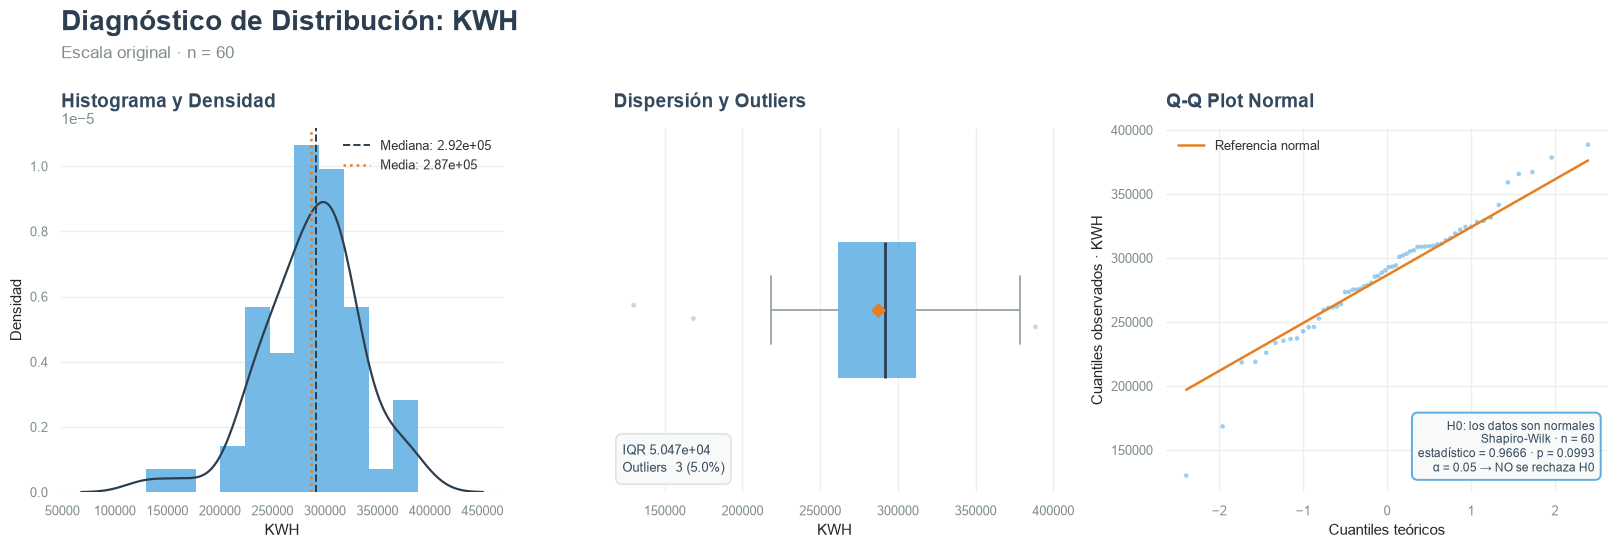

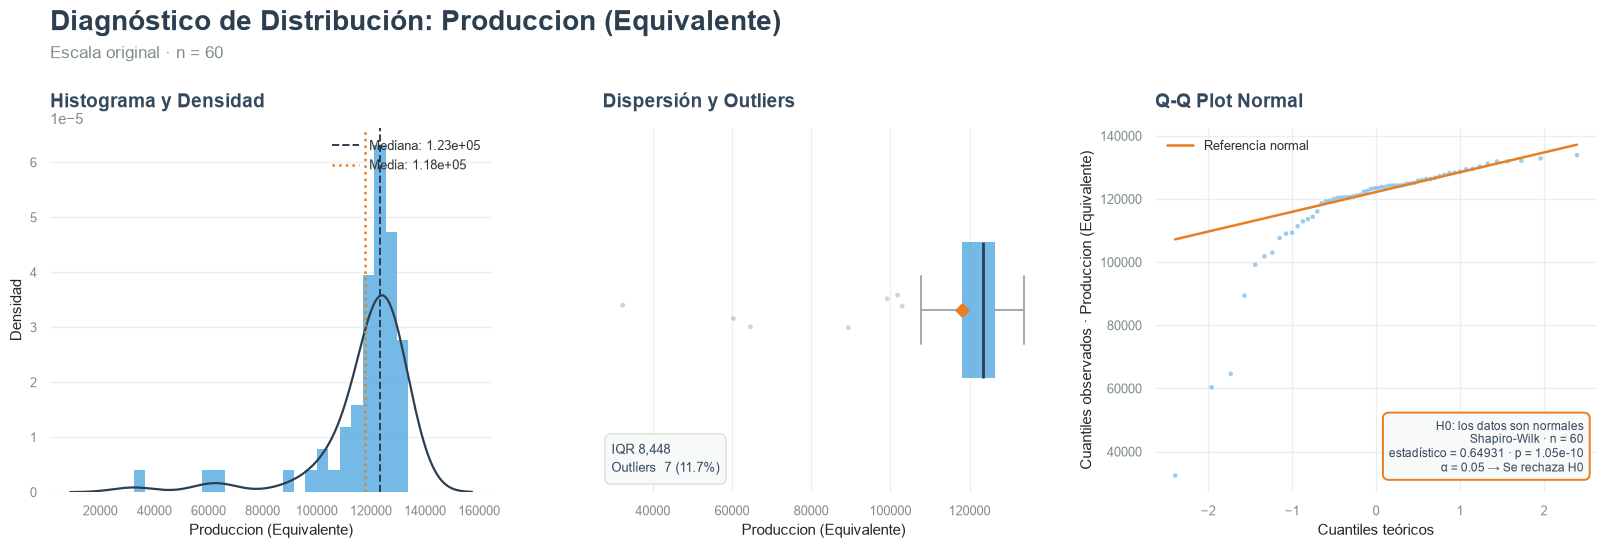

,n,mean,median,std,skew,kurtosis,test,statistic,p_value,is_normal,nulos
KWH,60,287246.783333,291588.5,46858.745302,-0.594104,1.585611,Shapiro-Wilk,0.966602,0.09933,True,0
Produccion (Equivalente),60,118011.719607,123410.59315,17761.197247,-3.061628,10.843386,Shapiro-Wilk,0.649311,0.0,False,0


In [202]:
solo_train(df_train_planta)
VARIABLES_PLANTA = ["KWH", "Produccion (Equivalente)"]
CAMPOS_NORMALIDAD = [
    "n",
    "mean",
    "median",
    "std",
    "skew",
    "kurtosis",
    "test",
    "statistic",
    "p_value",
    "is_normal",
]
previas_planta = pd.DataFrame(
    {columna: normality_report(df_train_planta, columna) for columna in VARIABLES_PLANTA}
).T[CAMPOS_NORMALIDAD]
previas_planta["nulos"] = df_train_planta[VARIABLES_PLANTA].isna().sum()
previas_planta

In [203]:
# Una fila por mes, con el inicio de mes como indice (Fecha reparte el dia de forma artificial)
planta_modelo = (
    solo_train(df_train_planta)
    .assign(mes=df_train_planta["Fecha"].dt.to_period("M").dt.to_timestamp())
    .set_index("mes")
    .sort_index()[VARIABLES_PLANTA]
    .rename(columns={"Produccion (Equivalente)": "Equ"})
)
calendario_modelo = pd.date_range(planta_modelo.index[0], planta_modelo.index[-1], freq="MS")
assert planta_modelo.index.equals(calendario_modelo), "faltan meses o hay meses repetidos"
assert (planta_modelo > 0).all().all(), "hay meses sin energia o sin produccion"

X_planta, y_planta = planta_modelo[["Equ"]], planta_modelo["KWH"]
print(
    f"{len(planta_modelo)} meses consecutivos, de {planta_modelo.index[0]:%Y-%m} a "
    f"{planta_modelo.index[-1]:%Y-%m} "
    f"({rotulo_fiscal(anio_fiscal(planta_modelo.index).min())} a "
    f"{rotulo_fiscal(anio_fiscal(planta_modelo.index).max())})"
)
planta_modelo.describe().round(0)

60 meses consecutivos, de 2019-10 a 2024-09 (FY2020 a FY2024)


,KWH,Equ
count,60.0,60.0
mean,287247.0,118012.0
std,46859.0,17761.0
min,129982.0,32388.0
25%,261386.0,117982.0
50%,291588.0,123411.0
75%,311861.0,126430.0
max,388552.0,133884.0


#### Candidatos y validacion cruzada

Cada candidato es un `Pipeline`: primero construye las variables y despues ajusta la
regresion. Lo que las variables aprenden de los datos (la produccion maxima, el mes de
origen) se aprende dentro de cada fold, solo con sus meses de ajuste.

- **Tendencia**: meses transcurridos desde el primer mes del tramo de ajuste.
- **Baja carga**: 1 si la utilizacion (produccion sobre el maximo del tramo de ajuste) baja
  del 70 %.
- **Estacion**: seno y coseno del mes del año.

La utilizacion no entra como variable propia: con un maximo fijo es la produccion en otra
escala, colineal perfecta con ella. Entra a traves de la bandera de baja carga.

**Regla de seleccion, fijada antes de mirar los resultados:** se queda `base + marginal`
salvo que otro candidato tenga menor WAPE agrupado en `kWh` y ademas la mejore en al menos
3 de los 4 folds.

In [204]:
UMBRAL_BAJA_CARGA = 0.70  # utilizacion por debajo de la cual un mes cuenta como de baja carga
BASE = "base + marginal"


class Caracteristicas(BaseEstimator, TransformerMixin):
    """Variables del modelo: produccion y, si se piden, tendencia, baja carga y estacion.

    Todo lo que aprende (la produccion maxima y el mes de origen) sale del tramo con que se
    ajusta, asi que dentro de la validacion cruzada nunca ve el tramo que se va a predecir.
    """

    def __init__(
        self,
        total: bool = False,
        tendencia: bool = False,
        baja_carga: bool = False,
        estacional: bool = False,
    ) -> None:
        self.total = total
        self.tendencia = tendencia
        self.baja_carga = baja_carga
        self.estacional = estacional

    def fit(self, datos: pd.DataFrame, _objetivo: pd.Series | None = None) -> Self:
        """Aprende la produccion maxima y el primer mes del tramo de ajuste."""
        self.equ_max_ = float(datos.sum(axis=1).max())
        self.origen_ = datos.index.min()
        return self

    def transform(self, datos: pd.DataFrame) -> pd.DataFrame:
        """Produccion (por linea o total) mas las columnas pedidas, con el mismo indice."""
        produccion = datos.sum(axis=1)
        salida = produccion.to_frame("Equ") if self.total else datos.copy()
        meses = datos.index
        if self.tendencia:
            # Meses desde el origen: sale del calendario, no de los datos
            salida["tendencia"] = (meses.year - self.origen_.year) * PERIODO + (
                meses.month - self.origen_.month
            )
        if self.baja_carga:
            # Utilizacion: produccion sobre el maximo visto en el tramo de ajuste
            salida["baja_carga"] = (produccion / self.equ_max_ < UMBRAL_BAJA_CARGA).astype(float)
        if self.estacional:
            angulo = 2 * np.pi * (meses.month - 1) / PERIODO
            salida["estacion_sen"] = np.sin(angulo)
            salida["estacion_cos"] = np.cos(angulo)
        return salida


def candidato(regresion: LinearRegression | Ridge, **opciones: bool) -> Pipeline:
    """Un candidato: las variables pedidas y, despues, la regresion."""
    return make_pipeline(Caracteristicas(**opciones), regresion)


CANDIDATOS_PLANTA = {
    # Lo que supone un presupuesto de kWh/Equ: sin carga fija, todo proporcional
    "proporcional": candidato(LinearRegression(fit_intercept=False)),
    BASE: candidato(LinearRegression()),
    "+ tendencia": candidato(LinearRegression(), tendencia=True),
    "+ baja carga": candidato(LinearRegression(), baja_carga=True),
    "+ estacional": candidato(LinearRegression(), estacional=True),
}


def metricas(real: pd.Series, estimado: pd.Series) -> dict[str, float]:
    """RMSE, MAE, R2, WAPE y MedAPE de `estimado` frente a `real`."""
    error = (real - estimado).abs()
    return {
        "RMSE": root_mean_squared_error(real, estimado),
        "MAE": mean_absolute_error(real, estimado),
        "R2": r2_score(real, estimado),
        # WAPE pondera cada mes por su tamano: un mes chico no domina el porcentaje
        "WAPE_pct": 100 * error.sum() / real.abs().sum(),
        # MedAPE es una mediana: no la arrastran los pocos meses de baja carga
        "MedAPE_pct": 100 * (error / real.abs()).median(),
    }


def validar(
    modelo: Pipeline, datos: pd.DataFrame, objetivo: pd.Series, cortes: TimeSeriesSplit
) -> pd.DataFrame:
    """Predice cada tramo de validacion con un modelo ajustado solo en los meses anteriores."""
    solo_train(datos)
    partes = []
    for fold, (i_ajuste, i_validacion) in enumerate(cortes.split(datos), start=1):
        ajustado = clone(modelo).fit(datos.iloc[i_ajuste], objetivo.iloc[i_ajuste])
        validacion = datos.iloc[i_validacion]
        partes.append(
            pd.DataFrame(
                {
                    "fold": fold,
                    "meses_ajuste": len(i_ajuste),
                    "real": objetivo.iloc[i_validacion],
                    "estimado": ajustado.predict(validacion),
                    "equ": validacion.sum(axis=1),
                }
            )
        )
    return pd.concat(partes)


def informe_cv(fuera: pd.DataFrame) -> pd.DataFrame:
    """Las cinco metricas sobre kWh y sobre kWh/Equ reconstruido (kWh estimado / Equ)."""
    return pd.DataFrame(
        {
            "kWh": metricas(fuera["real"], fuera["estimado"]),
            "kWh/Equ": metricas(fuera["real"] / fuera["equ"], fuera["estimado"] / fuera["equ"]),
        }
    ).T

In [205]:
# Cada fold predice un anio fiscal completo con todos los anteriores
CV_PLANTA = TimeSeriesSplit(n_splits=4, test_size=PERIODO)
MIN_FOLDS_MEJORA = 3  # folds en que un candidato debe mejorar a la base para desplazarla

fuera_planta = {
    nombre: validar(modelo, X_planta, y_planta, CV_PLANTA)
    for nombre, modelo in CANDIDATOS_PLANTA.items()
}

# Las ventanas son las mismas para todos los candidatos: se muestran una vez
tramos = list(fuera_planta[BASE].groupby("fold"))
assert all(anio_fiscal(tramo.index).nunique() == 1 for _, tramo in tramos), "fold partido"
ventanas_cv = pd.DataFrame(
    [
        {
            "fold": fold,
            "meses_de_ajuste": int(tramo["meses_ajuste"].iloc[0]),
            "valida": rotulo_fiscal(anio_fiscal(tramo.index)[0]),
            "desde": f"{tramo.index[0]:%Y-%m}",
            "hasta": f"{tramo.index[-1]:%Y-%m}",
            "meses": len(tramo),
        }
        for fold, tramo in tramos
    ]
)

# Metricas agrupadas (los 48 meses fuera de muestra juntos) y por fold
cv_planta = pd.concat(
    {nombre: informe_cv(fuera) for nombre, fuera in fuera_planta.items()},
    names=["candidato", "objetivo"],
)
cv_planta_fold = pd.concat(
    {
        (nombre, fold): informe_cv(tramo)
        for nombre, fuera in fuera_planta.items()
        for fold, tramo in fuera.groupby("fold")
    },
    names=["candidato", "fold", "objetivo"],
)

# La regla de seleccion, aplicada tal como se fijo
orden_candidatos = list(CANDIDATOS_PLANTA)
wape_fold = (
    cv_planta_fold.xs("kWh", level="objetivo")["WAPE_pct"].unstack("fold").reindex(orden_candidatos)
)
wape_total = cv_planta.xs("kWh", level="objetivo")["WAPE_pct"].reindex(orden_candidatos)
seleccion = pd.DataFrame(
    {
        "WAPE_kWh_agrupado": wape_total,
        "folds_en_que_mejora_a_la_base": wape_fold.lt(wape_fold.loc[BASE], axis=1).sum(axis=1),
    }
)
seleccion["desplaza_a_la_base"] = (seleccion["WAPE_kWh_agrupado"] < wape_total[BASE]) & (
    seleccion["folds_en_que_mejora_a_la_base"] >= MIN_FOLDS_MEJORA
)
retadores = seleccion[seleccion["desplaza_a_la_base"]]
ELEGIDO = BASE if retadores.empty else retadores["WAPE_kWh_agrupado"].idxmin()

print(f"candidato elegido: {ELEGIDO}")
display(ventanas_cv, seleccion.round(2), wape_fold.round(2))
with pd.option_context("display.max_rows", None):
    display(cv_planta_fold.round(3))
cv_planta.round(3)

candidato elegido: base + marginal


,fold,meses_de_ajuste,valida,desde,hasta,meses
0,1,12,FY2021,2020-10,2021-09,12
1,2,24,FY2022,2021-10,2022-09,12
2,3,36,FY2023,2022-10,2023-09,12
3,4,48,FY2024,2023-10,2024-09,12


,WAPE_kWh_agrupado,folds_en_que_mejora_a_la_base,desplaza_a_la_base
candidato,,,
proporcional,14.44,0,False
base + marginal,13.01,0,False
+ tendencia,14.44,2,False
+ baja carga,14.04,2,False
+ estacional,14.20,2,False


fold,1,2,3,4
candidato,,,,
proporcional,6.63,17.61,10.53,24.72
base + marginal,5.71,16.09,9.72,22.05
+ tendencia,19.10,17.57,8.02,12.18
+ baja carga,9.01,15.22,12.04,21.07
+ estacional,10.35,15.63,9.50,22.40


RMSE        MAE      R2  WAPE_pct  \
candidato       fold objetivo                                           
proporcional    1    kWh       23594.225  20958.967   0.855     6.629   
                     kWh/Equ       0.408      0.248  -0.051     8.859   
                2    kWh       61668.498  50540.861  -2.237    17.607   
                     kWh/Equ       0.493      0.404  -1.601    17.385   
                3    kWh       34644.383  29264.713  -1.028    10.531   
                     kWh/Equ       0.306      0.258  -0.172    10.559   
                4    kWh       67164.800  63710.557 -14.971    24.716   
                     kWh/Equ       0.522      0.497  -9.879    24.533   
base + marginal 1    kWh       23023.454  18066.350   0.862     5.714   
                     kWh/Equ       0.270      0.188   0.541     6.710   
                2    kWh       57823.959  46192.901  -1.846    16.092   
                     kWh/Equ       0.463      0.369  -1.295    15.897   
                3    kWh       32892.953  27022.892  -0.828     9.725   
                     kWh/Equ       0.286      0.234  -0.025     9.578   
                4    kWh       60017.604  56835.466 -11.753    22.049   
                     kWh/Equ       0.468      0.444  -7.728    21.913   
+ tendencia     1    kWh       67954.231  60377.420  -0.199    19.096   
                     kWh/Equ       0.881      0.643  -3.890    22.946   
                2    kWh       61777.870  50424.632  -2.249    17.567   
                     kWh/Equ       0.494      0.402  -1.618    17.339   
                3    kWh       29467.356  22291.842  -0.467     8.022   
                     kWh/Equ       0.283      0.205  -0.002     8.397   
                4    kWh       37181.980  31394.335  -3.895    12.179   
                     kWh/Equ       0.288      0.244  -2.316    12.047   
+ baja carga    1    kWh       38110.800  28478.992   0.623     9.007   
                     kWh/Equ       0.692      0.364  -2.014    12.996   
                2    kWh       55768.209  43689.837  -1.648    15.220   
                     kWh/Equ       0.448      0.350  -1.147    15.072   
                3    kWh       39284.196  33466.978  -1.608    12.044   
                     kWh/Equ       0.362      0.301  -0.639    12.333   
                4    kWh       57297.085  54303.605 -10.623    21.067   
                     kWh/Equ       0.447      0.425  -6.987    20.960   
+ estacional    1    kWh       39644.628  32719.200   0.592    10.348   
                     kWh/Equ       0.321      0.273   0.349     9.747   
                2    kWh       56729.127  44872.155  -1.740    15.632   
                     kWh/Equ       0.452      0.358  -1.192    15.423   
                3    kWh       31401.525  26406.352  -0.666     9.503   
                     kWh/Equ       0.275      0.231   0.053     9.462   
                4    kWh       59000.668  57740.412 -11.324    22.400   
                     kWh/Equ       0.460      0.452  -7.455    22.293   

                               MedAPE_pct  
candidato       fold objetivo              
proporcional    1    kWh            6.301  
                     kWh/Equ        6.301  
                2    kWh           16.277  
                     kWh/Equ       16.277  
                3    kWh           10.309  
                     kWh/Equ       10.309  
                4    kWh           24.550  
                     kWh/Equ       24.550  
base + marginal 1    kWh            4.085  
                     kWh/Equ        4.085  
                2    kWh           14.567  
                     kWh/Equ       14.567  
                3    kWh            9.761  
                     kWh/Equ        9.761  
                4    kWh           21.189  
                     kWh/Equ       21.189  
+ tendencia     1    kWh           22.730  
                     kWh/Equ       22.730  
                2    kWh           16.371  
                     kWh/Equ       16.371  
 

RMSE        MAE     R2  WAPE_pct  MedAPE_pct
candidato       objetivo                                                   
proporcional    kWh       50177.273  41118.775 -0.314    14.442      12.199
                kWh/Equ       0.440      0.352 -0.164    14.666      12.199
base + marginal kWh       46254.051  37029.402 -0.116    13.006      12.536
                kWh/Equ       0.383      0.309  0.118    12.875      12.536
+ tendencia     kWh       51684.397  41122.057 -0.394    14.443      12.627
                kWh/Equ       0.544      0.374 -0.777    15.581      12.627
+ baja carga    kWh       48447.730  39984.853 -0.225    14.044      13.606
                kWh/Equ       0.502      0.360 -0.516    15.012      13.606
+ estacional    kWh       48106.717  40434.530 -0.207    14.202      13.142
                kWh/Equ       0.386      0.329  0.106    13.699      13.142

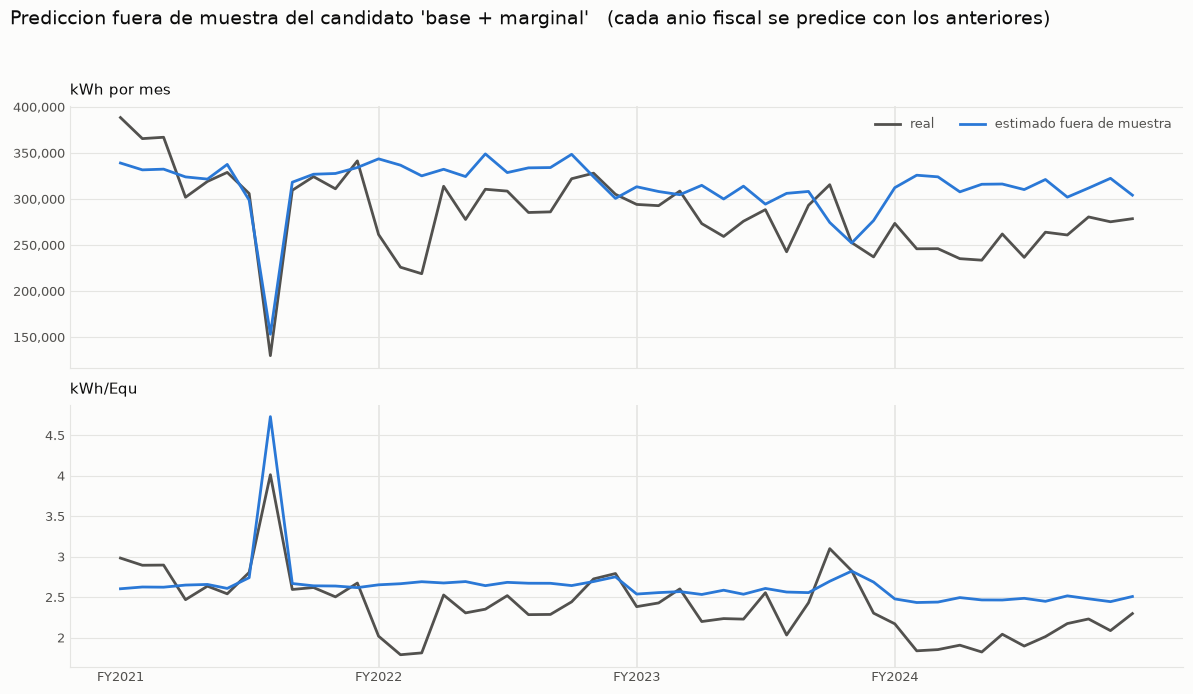

In [206]:
# Lo observado va en tinta y el modelo en azul: la figura es sobre el modelo
fuera_elegido = fuera_planta[ELEGIDO]
paneles = {
    "kWh por mes": (fuera_elegido["real"], fuera_elegido["estimado"]),
    "kWh/Equ": (
        fuera_elegido["real"] / fuera_elegido["equ"],
        fuera_elegido["estimado"] / fuera_elegido["equ"],
    ),
}

fig, axes = plt.subplots(2, 1, figsize=(12, 7), facecolor=SUPERFICIE, sharex=True)
fig.suptitle(
    f"Prediccion fuera de muestra del candidato '{ELEGIDO}'"
    "   (cada anio fiscal se predice con los anteriores)",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)
for ax, (nombre, (real, estimado)) in zip(axes, paneles.items(), strict=True):
    ax.plot(real.index, real, color=TINTA_SUAVE, linewidth=2, label="real", zorder=3)
    ax.plot(
        estimado.index,
        estimado,
        color=LINEA,
        linewidth=2,
        label="estimado fuera de muestra",
        zorder=4,
    )
    # La frontera de cada fold es el inicio de un anio fiscal
    for inicio in pd.date_range(real.index[0], real.index[-1], freq="YS-OCT")[1:]:
        ax.axvline(inicio, color=GRILLA, linewidth=1.2, zorder=1)
    estilo_eje(ax)
    ax.yaxis.set_major_formatter(rotulo_eje)
    ax.set_title(nombre, fontsize=10.5, color=TINTA, loc="left", pad=8)
axes[0].legend(loc="upper right", frameon=False, fontsize=9, labelcolor=TINTA_SUAVE, ncols=2)
eje_fiscal(axes[0], fuera_elegido.index[0], fuera_elegido.index[-1])  # eje compartido

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

#### Resumen: validacion cruzada de la planta

- **Se queda `base + marginal`.** Su WAPE agrupado en `kWh` es 13.01 %, frente a 14.04 a
  14.44 % de los otros cuatro, y ninguno la mejora en mas de 2 de los 4 folds.
- **Aun asi predice mal un año fiscal a partir de los anteriores.** Sobre los 48 meses fuera
  de muestra: RMSE 46,254 kWh, MAE 37,029, R2 -0.116 y MedAPE 12.54 %. En `kWh/Equ`: RMSE
  0.383, MAE 0.309, R2 0.118 y WAPE 12.88 %. Un R2 negativo dice que la media de esos meses,
  que solo se conoce despues, habria tenido menos error.
- **El error crece cuando el nivel de energia cambia de un año al siguiente**: WAPE de
  5.71 % en FY2021, 16.09 % en FY2022, 9.72 % en FY2023 y 22.05 % en FY2024.
- **La tendencia ayuda tarde.** Es la mejor en los dos ultimos folds (8.02 y 12.18 %) y la
  peor en el primero (19.10 %), cuando solo tiene 12 meses de ajuste.
- `MedAPE` coincide en `kWh` y en `kWh/Equ` por construccion: la produccion divide por igual
  lo real y lo estimado, asi que el error porcentual de cada mes es el mismo.

#### Ajuste en train y supuestos de la regresion

Cada candidato se ajusta ahora sobre los 60 meses de train con `statsmodels`, para tener
errores, p-valores e intervalos. Despues se prueban uno a uno los supuestos de la regresion
lineal sobre la forma base y sobre la elegida.

In [207]:
HAC_REZAGOS = PERIODO  # Newey-West con un anio de rezagos, por la autocorrelacion de los residuos
OLS = sm.regression.linear_model.RegressionResultsWrapper


def ajustar_ols(candidato_cv: Pipeline, datos: pd.DataFrame, objetivo: pd.Series) -> OLS:
    """El mismo modelo del candidato, ajustado con statsmodels para tener inferencia."""
    solo_train(datos)
    variables = clone(candidato_cv[0]).fit(datos).transform(datos).astype(float)
    if candidato_cv[-1].fit_intercept:
        variables = sm.add_constant(variables, has_constant="add")
    return sm.OLS(objetivo, variables).fit()


def tabla_coeficientes(nombre: str, modelo_ols: OLS, rezagos_nw: int | None) -> pd.DataFrame:
    """Coeficientes con error, p-valor e intervalo: clasicos y, si se pide, Newey-West."""
    terminos = modelo_ols.params.index
    intervalo = modelo_ols.conf_int()
    tabla = pd.DataFrame(
        {
            "candidato": nombre,
            "termino": terminos,
            "coeficiente": modelo_ols.params.to_numpy(),
            "error_estandar": modelo_ols.bse.to_numpy(),
            "p_valor": modelo_ols.pvalues.to_numpy(),
            "ic95_inf": intervalo[0].to_numpy(),
            "ic95_sup": intervalo[1].to_numpy(),
        }
    )
    if rezagos_nw is not None:
        robusto = modelo_ols.get_robustcov_results(cov_type="HAC", maxlags=rezagos_nw)
        intervalo_nw = np.asarray(robusto.conf_int())
        tabla["p_valor_nw"] = np.asarray(robusto.pvalues)
        tabla["ic95_inf_nw"] = intervalo_nw[:, 0]
        tabla["ic95_sup_nw"] = intervalo_nw[:, 1]
    return tabla


def resumen_ajuste(nombre: str, modelo_ols: OLS, objetivo: pd.Series) -> dict[str, object]:
    """Bondad de ajuste de un modelo: R2 frente a la media, F, error residual y Durbin-Watson."""
    con_constante = "const" in modelo_ols.params
    # Sin constante statsmodels da un R2 no centrado: se recalcula frente a la media
    r2 = 1 - modelo_ols.ssr / modelo_ols.centered_tss
    return {
        "candidato": nombre,
        "n": int(modelo_ols.nobs),
        "parametros": len(modelo_ols.params),
        "R2": r2,
        "R2_ajustado": 1 - (1 - r2) * (modelo_ols.nobs - 1) / modelo_ols.df_resid,
        "F": modelo_ols.fvalue if con_constante else np.nan,
        "p_F": modelo_ols.f_pvalue if con_constante else np.nan,
        "error_residual": np.sqrt(modelo_ols.mse_resid),
        "durbin_watson": sm.stats.durbin_watson(modelo_ols.resid),
        "carga_base_pct_mes_mediano": 100 * modelo_ols.params.get("const", 0.0) / objetivo.median(),
    }


def informe_ajuste(ajustes: dict[str, OLS], objetivo: pd.Series) -> pd.DataFrame:
    """Una fila por candidato: bondad de ajuste y, al lado, cada coeficiente."""
    bondad = pd.DataFrame(
        [resumen_ajuste(nombre, modelo_ols, objetivo) for nombre, modelo_ols in ajustes.items()]
    ).set_index("candidato")
    terminos = dict.fromkeys(t for modelo_ols in ajustes.values() for t in modelo_ols.params.index)
    en_orden = ["const", *[termino for termino in terminos if termino != "const"]]
    coeficientes = pd.DataFrame(
        {nombre: modelo_ols.params for nombre, modelo_ols in ajustes.items()}
    )
    return bondad.join(coeficientes.T[en_orden].rename(columns={"const": "alpha"}))


ajustes_planta = {
    nombre: ajustar_ols(modelo, X_planta, y_planta) for nombre, modelo in CANDIDATOS_PLANTA.items()
}
coeficientes_planta = pd.concat(
    [tabla_coeficientes(n, modelo_ols, HAC_REZAGOS) for n, modelo_ols in ajustes_planta.items()],
    ignore_index=True,
)
ajuste_planta = informe_ajuste(ajustes_planta, y_planta)

for nombre in dict.fromkeys([BASE, "+ tendencia", ELEGIDO]):
    fila = ajuste_planta.loc[nombre]
    print(
        f"{nombre}: alpha = {fila['alpha']:,.0f} kWh/mes | beta = {fila['Equ']:.3f} kWh/Equ | "
        f"R2 = {fila['R2']:.3f} | carga base = {fila['carga_base_pct_mes_mediano']:.1f} % de un "
        f"mes mediano | Durbin-Watson = {fila['durbin_watson']:.2f}"
    )
tendencia_ols = coeficientes_planta.query("candidato == '+ tendencia' and termino == 'tendencia'")
print(
    f"tendencia: {tendencia_ols['coeficiente'].iloc[0]:,.0f} kWh por cada mes que pasa "
    f"(p = {tendencia_ols['p_valor'].iloc[0]:.4f}, Newey-West p = "
    f"{tendencia_ols['p_valor_nw'].iloc[0]:.4f})"
)
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(coeficientes_planta, ajuste_planta)

base + marginal: alpha = 127,644 kWh/mes | beta = 1.352 kWh/Equ | R2 = 0.263 | carga base = 43.8 % de un mes mediano | Durbin-Watson = 0.80
+ tendencia: alpha = 129,633 kWh/mes | beta = 1.668 kWh/Equ | R2 = 0.494 | carga base = 44.5 % de un mes mediano | Durbin-Watson = 1.08
tendencia: -1,330 kWh por cada mes que pasa (p = 0.0000, Newey-West p = 0.0002)


,candidato,termino,coeficiente,error_estandar,p_valor,ic95_inf,ic95_sup,p_valor_nw,ic95_inf_nw,ic95_sup_nw
0,proporcional,Equ,2.4105,0.0481,0.0000,2.3142,2.5068,0.0000,2.1941,2.6269
1,base + marginal,const,"127,644.2108","35,490.4637",0.0007,"56,602.3290","198,686.0925",0.0005,"58,732.2542","196,556.1673"
2,base + marginal,Equ,1.3524,0.2974,0.0000,0.7570,1.9478,0.0005,0.6173,2.0875
3,+ tendencia,const,"129,632.5092","29,660.5285",0.0001,"70,238.3254","189,026.6931",0.0003,"61,629.2397","197,635.7788"
4,+ tendencia,Equ,1.6680,0.2561,0.0000,1.1551,2.1809,0.0000,1.0182,2.3177
5,+ tendencia,tendencia,"-1,329.6451",260.4869,0.0000,"-1,851.2611",-808.0290,0.0002,"-1,991.9042",-667.3859
6,+ baja carga,const,"238,633.0709","68,620.9649",0.0010,"101,221.9589","376,044.1829",0.0002,"116,763.2452","360,502.8965"
7,+ baja carga,Equ,0.4539,0.5606,0.4215,-0.6687,1.5765,0.3895,-0.5942,1.5020
8,+ baja carga,baja_carga,"-74,244.4033","39,584.2029",0.0658,"-153,510.4023","5,021.5958",0.0212,"-136,974.1206","-11,514.6859"
9,+ estacional,const,"123,589.0397","37,029.1204",0.0015,"49,410.7980","197,767.2814",0.0007,"54,830.5191","192,347.5603"


,n,parametros,R2,R2_ajustado,F,p_F,error_residual,durbin_watson,carga_base_pct_mes_mediano,alpha,Equ,tendencia,baja_carga,estacion_sen,estacion_cos
candidato,,,,,,,,,,,,,,,
proporcional,60,1,0.0984,0.0984,NaN,NaN,"44,494.5249",0.6356,0.0000,NaN,2.4105,NaN,NaN,NaN,NaN
base + marginal,60,2,0.2628,0.2501,20.6740,0.0000,"40,578.9828",0.8024,43.7755,"127,644.2108",1.3524,NaN,NaN,NaN,NaN
+ tendencia,60,3,0.4941,0.4763,27.8302,0.0000,"33,910.2439",1.0815,44.4573,"129,632.5092",1.6680,"-1,329.6451",NaN,NaN,NaN
+ baja carga,60,3,0.3056,0.2813,12.5447,0.0000,"39,725.8524",0.8404,81.8390,"238,633.0709",0.4539,NaN,"-74,244.4033",NaN,NaN
+ estacional,60,4,0.3226,0.2863,8.8889,0.0001,"39,586.8523",0.8360,42.3847,"123,589.0397",1.3868,NaN,NaN,"-8,084.6805","-13,914.4781"


In [208]:
DW_BAJO, DW_ALTO = 1.5, 2.5  # fuera de este rango el Durbin-Watson sugiere autocorrelacion
REZAGO_CORTO = 1
SCHWERT, MIN_REGRESORES_VIF = 12, 2  # regla de rezagos de ADF; regresores minimos para un VIF
SIN_PRUEBA = {"p_valor": np.nan, "H0": "-", "se_rechaza_H0": None}


def fila_prueba(
    supuesto: str,
    prueba: str,
    estadistico: float,
    p_valor: float,
    h0: str,
    lecturas: tuple[str, str],
) -> dict[str, object]:
    """Una fila de la tabla de supuestos, con la decision al nivel ALFA."""
    rechaza = bool(p_valor < ALFA)
    return {
        "supuesto": supuesto,
        "prueba": prueba,
        "estadistico": estadistico,
        "p_valor": p_valor,
        "H0": h0,
        "se_rechaza_H0": rechaza,
        "lectura": lecturas[0] if rechaza else lecturas[1],
    }


def filas_estacionariedad(residuos: pd.Series) -> list[dict[str, object]]:
    """ADF y KPSS sobre los residuos: si no son estacionarios la relacion puede ser espuria."""
    n = len(residuos)
    rezagos = min(int(SCHWERT * (n / 100) ** 0.25), n // 2 - 3)
    prueba_adf = adfuller(residuos, maxlag=rezagos, autolag="AIC", result_object=True)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        prueba_kpss = kpss(residuos, regression="c", nlags="auto", result_object=True)
    lectura = diagnostico(prueba_adf.pvalue, prueba_kpss.pvalue)
    return [
        fila_prueba(
            "relacion no espuria",
            "ADF sobre los residuos",
            prueba_adf.statistic,
            prueba_adf.pvalue,
            "los residuos tienen raiz unitaria",
            (lectura, lectura),
        ),
        fila_prueba(
            "relacion no espuria",
            "KPSS sobre los residuos",
            prueba_kpss.statistic,
            prueba_kpss.pvalue,
            "el nivel de los residuos es constante",
            (lectura, lectura),
        ),
    ]


def filas_colinealidad(modelo_ols: OLS) -> list[dict[str, object]]:
    """VIF maximo y numero de condicion de los regresores, sin la constante."""
    regresores = pd.DataFrame(modelo_ols.model.exog, columns=modelo_ols.model.exog_names)
    regresores = regresores.drop(columns="const", errors="ignore")
    if regresores.shape[1] < MIN_REGRESORES_VIF:
        return [
            {
                "supuesto": "sin colinealidad",
                "prueba": "VIF y numero de condicion",
                "estadistico": np.nan,
                **SIN_PRUEBA,
                "lectura": "un solo regresor: no hay con que ser colineal",
            }
        ]
    vif = vif_table(regresores.assign(objetivo=modelo_ols.model.endog), "objetivo", verbose=False)
    estandar = (regresores - regresores.mean()) / regresores.std()
    return [
        {
            "supuesto": "sin colinealidad",
            "prueba": "VIF maximo",
            "estadistico": vif["VIF"].max(),
            **SIN_PRUEBA,
            "lectura": "colinealidad alta" if vif["alto"].any() else "sin colinealidad apreciable",
        },
        {
            "supuesto": "sin colinealidad",
            "prueba": "numero de condicion",
            "estadistico": np.linalg.cond(estandar.to_numpy()),
            **SIN_PRUEBA,
            "lectura": "regresores estandarizados",
        },
    ]


def filas_influencia(modelo_ols: OLS) -> list[dict[str, object]]:
    """Cuantos meses pasan los umbrales habituales de influencia, y cuales son."""
    meses = modelo_ols.resid.index
    _, atipicos, palanca, influyentes = DiagnosticoOLS(modelo_ols).metricas_influencia()
    casos = {
        "residuo estudentizado mayor que 2": atipicos,
        "apalancamiento mayor que 2k/n": palanca,
        "distancia de Cook mayor que 4/n": influyentes,
    }
    return [
        {
            "supuesto": "sin observacion dominante",
            "prueba": prueba,
            "estadistico": len(marcados),
            **SIN_PRUEBA,
            "lectura": ", ".join(f"{mes:%Y-%m}" for mes in meses[marcados.index]) or "ninguno",
        }
        for prueba, marcados in casos.items()
    ]


def supuestos(modelo_ols: OLS, rezagos: list[int]) -> pd.DataFrame:
    """Pruebas de los supuestos de la regresion lineal sobre un modelo ya ajustado."""
    residuos = modelo_ols.resid
    clasicas = DiagnosticoOLS(modelo_ols).pruebas_hipotesis(mostrar=False).set_index("prueba")
    valores = clasicas[["estadistico", "p_valor"]]
    normalidad = ("los residuos son normales", ("residuos no normales", "sin evidencia en contra"))
    independencia = ("sin autocorrelacion", ("residuos autocorrelados", "sin evidencia en contra"))
    durbin = valores.loc["Durbin-Watson", "estadistico"]
    lectura_durbin = "sin indicio de autocorrelacion de orden 1"
    if not DW_BAJO <= durbin <= DW_ALTO:
        lectura_durbin = "autocorrelacion " + ("positiva" if durbin < DW_BAJO else "negativa")

    filas = [
        fila_prueba(
            "forma lineal",
            "Ramsey RESET",
            *valores.loc["Ramsey RESET"],
            "la forma lineal es adecuada",
            ("falta forma funcional", "sin evidencia en contra"),
        ),
        fila_prueba("residuos normales", "Jarque-Bera", *valores.loc["Jarque-Bera"], *normalidad),
        fila_prueba("residuos normales", "Shapiro-Wilk", *stats.shapiro(residuos), *normalidad),
        fila_prueba(
            "varianza constante",
            "Breusch-Pagan",
            *valores.loc["Breusch-Pagan"],
            "la varianza es constante",
            ("heterocedasticidad", "sin evidencia en contra"),
        ),
        {
            "supuesto": "residuos independientes",
            "prueba": "Durbin-Watson",
            "estadistico": durbin,
            **SIN_PRUEBA,
            "lectura": lectura_durbin,
        },
    ]
    for rezago in rezagos:
        estadistico, p_valor, *_ = acorr_breusch_godfrey(
            modelo_ols, nlags=rezago, result_object=True
        )
        filas.append(
            fila_prueba(
                "residuos independientes",
                f"Breusch-Godfrey, rezago {rezago}",
                estadistico,
                p_valor,
                *independencia,
            )
        )
    ljung = acorr_ljungbox(residuos, lags=[max(rezagos)])
    filas.append(
        fila_prueba(
            "residuos independientes",
            f"Ljung-Box, rezago {max(rezagos)}",
            ljung["lb_stat"].iloc[0],
            ljung["lb_pvalue"].iloc[0],
            *independencia,
        )
    )
    filas += filas_estacionariedad(residuos)
    filas += filas_colinealidad(modelo_ols)
    filas += filas_influencia(modelo_ols)
    return pd.DataFrame(filas)


# La forma base y la elegida (una sola tabla si coinciden). Las pruebas piden constante.
formas = [f for f in dict.fromkeys([BASE, ELEGIDO]) if "const" in ajustes_planta[f].params]
supuestos_planta = pd.concat(
    {forma: supuestos(ajustes_planta[forma], [REZAGO_CORTO, PERIODO]) for forma in formas},
    names=["candidato", "fila"],
).droplevel("fila")
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(supuestos_planta.round(4))

Observaciones con residuos atípicos (|student| > 2): 2
Observaciones con alto leverage (hat > 0.067): 3
Observaciones influyentes (Cook D > 0.067): 2


,supuesto,prueba,estadistico,p_valor,H0,se_rechaza_H0,lectura
candidato,,,,,,,
base + marginal,forma lineal,Ramsey RESET,6.5661,0.0131,la forma lineal es adecuada,True,falta forma funcional
base + marginal,residuos normales,Jarque-Bera,0.6150,0.7353,los residuos son normales,False,sin evidencia en contra
base + marginal,residuos normales,Shapiro-Wilk,0.9791,0.3933,los residuos son normales,False,sin evidencia en contra
base + marginal,varianza constante,Breusch-Pagan,0.1387,0.7096,la varianza es constante,False,sin evidencia en contra
base + marginal,residuos independientes,Durbin-Watson,0.8024,NaN,-,None,autocorrelacion positiva
base + marginal,residuos independientes,"Breusch-Godfrey, rezago 1",21.8134,0.0000,sin autocorrelacion,True,residuos autocorrelados
base + marginal,residuos independientes,"Breusch-Godfrey, rezago 12",24.9352,0.0151,sin autocorrelacion,True,residuos autocorrelados
base + marginal,residuos independientes,"Ljung-Box, rezago 12",57.3682,0.0000,sin autocorrelacion,True,residuos autocorrelados
base + marginal,relacion no espuria,ADF sobre los residuos,-3.7867,0.0030,los residuos tienen raiz unitaria,True,"sin raiz unitaria, pero el nivel cambia"


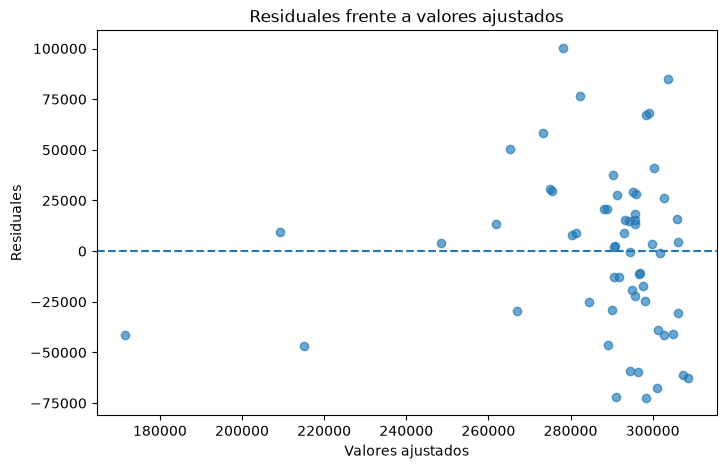

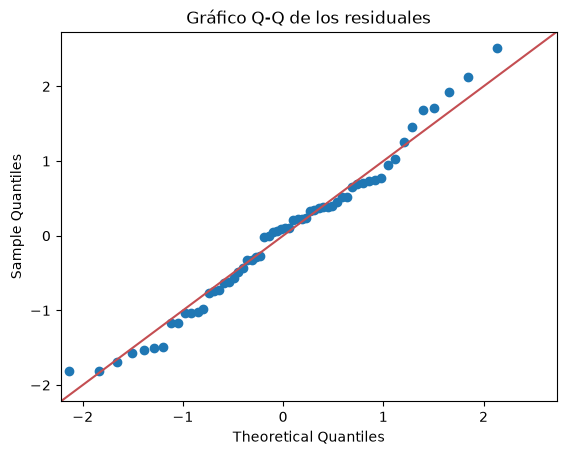

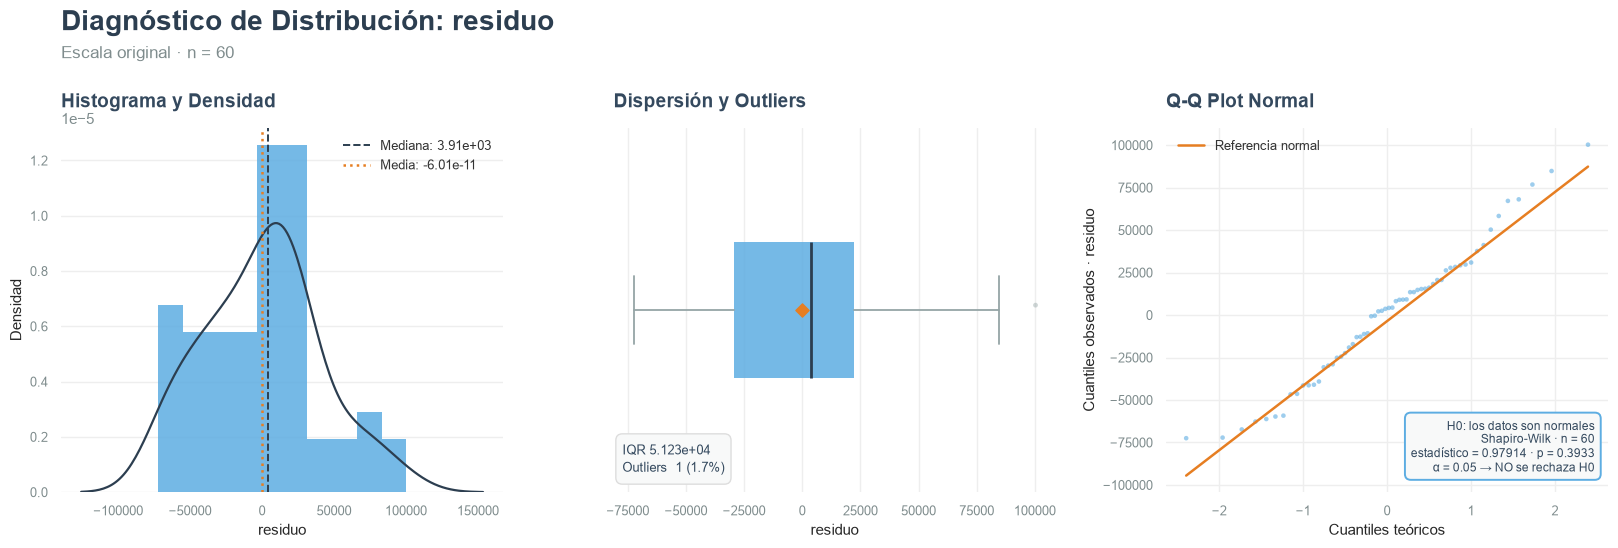

In [209]:
# Los residuos de la forma elegida, con las graficas del diagnostico OLS y la prueba previa
diagnostico_elegido = DiagnosticoOLS(ajustes_planta[formas[-1]])
diagnostico_elegido.grafico_residuales_vs_ajustados()
diagnostico_elegido.grafico_qq()
residuos_elegido = ajustes_planta[formas[-1]].resid.to_frame("residuo")
resumen_residuos = normality_report(residuos_elegido, "residuo")

#### Resumen: ajuste y supuestos de la planta

- **La forma base en train**: `KWH = 127,644 + 1.352 x Equ`, con R2 de 0.263. La carga base
  equivale al 43.8 % de un mes mediano. Con Newey-West, `alpha` va de 58,732 a 196,556 y
  `beta` de 0.62 a 2.09: distintos de cero, pero anchos.
- **Se cumplen** la normalidad de los residuos (Jarque-Bera p 0.7353, Shapiro-Wilk p 0.3933)
  y la varianza constante (Breusch-Pagan p 0.7096).
- **No se cumple la independencia.** Durbin-Watson de 0.80, Breusch-Godfrey rechaza en los
  rezagos 1 y 12 (p 0.0000 y 0.0151) y Ljung-Box tambien (p 0.0000). Por eso los intervalos
  que valen son los de Newey-West.
- **Tampoco la forma lineal** (RESET p 0.0131), y el nivel de los residuos cambia (ADF p
  0.0030, KPSS p 0.0145). Es la misma causa: a igual produccion la energia bajo con los
  años. La tendencia lo recoge (-1,330 kWh por cada mes, p 0.0002 con Newey-West, R2 0.494),
  pero no supero la validacion cruzada.
- **La pendiente descansa en los meses de baja carga.** 3 meses tienen apalancamiento alto
  (2020-04, 2020-05, 2021-05) y 2 superan la distancia de Cook (2020-04, 2021-05). Al
  separarlos con la bandera, la pendiente cae a 0.454 y deja de ser significativa (p
  0.4215), y la carga base sube al 81.8 % de un mes mediano: dentro del rango normal de
  produccion la energia casi no responde al volumen.

#### Lectura del modelo: carga base y dilucion

Con una carga fija `alpha`, la energia por equivalente es `alpha / Equ + beta`: sube cuando
el volumen baja aunque la planta no gaste mas. Las figuras usan la forma `base + marginal`,
que es la que se puede dibujar contra la produccion.

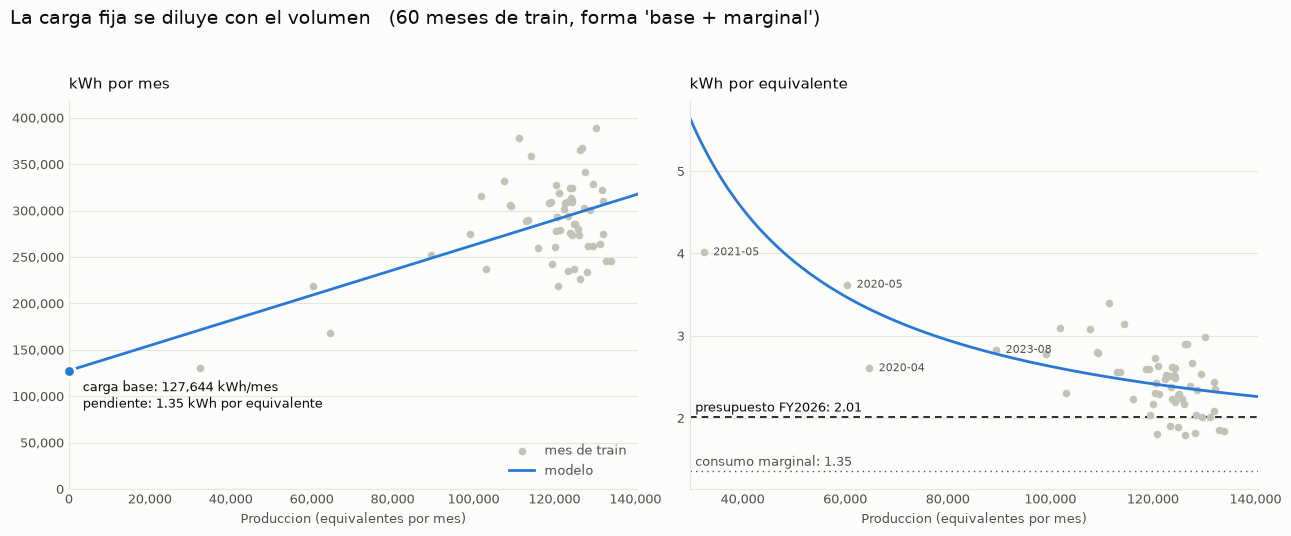

In [210]:
alpha_base, beta_base = ajustes_planta[BASE].params[["const", "Equ"]]
equ, kwh = planta_modelo["Equ"], planta_modelo["KWH"]
baja = equ / equ.max() < UMBRAL_BAJA_CARGA
malla = np.linspace(0, equ.max() * 1.05, 200)
malla_razon = malla[malla >= equ.min() * 0.9]  # cerca de cero la curva se va al infinito

fig, (ax_kwh, ax_razon) = plt.subplots(1, 2, figsize=(13, 5.4), facecolor=SUPERFICIE)
fig.suptitle(
    f"La carga fija se diluye con el volumen   ({len(equ)} meses de train, forma '{BASE}')",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)

# Izquierda: energia frente a produccion. La recta corta el eje en la carga base
ax_kwh.scatter(equ, kwh, s=30, color=OBSERVACION, linewidths=0, label="mes de train", zorder=2)
ax_kwh.plot(malla, alpha_base + beta_base * malla, color=LINEA, linewidth=2, label="modelo")
ax_kwh.scatter(
    [0],
    [alpha_base],
    s=70,
    color=LINEA,
    edgecolors=SUPERFICIE,
    linewidths=2,
    zorder=4,
    clip_on=False,
)
ax_kwh.annotate(
    f"carga base: {alpha_base:,.0f} kWh/mes\npendiente: {beta_base:.2f} kWh por equivalente",
    xy=(0, alpha_base),
    xytext=(10, -6),
    textcoords="offset points",
    color=TINTA,
    fontsize=9,
    va="top",
)
ax_kwh.set_xlim(0, malla[-1])
ax_kwh.set_ylim(0, kwh.max() * 1.08)
ax_kwh.set_title("kWh por mes", fontsize=10.5, color=TINTA, loc="left", pad=8)
ax_kwh.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=TINTA_SUAVE)

# Derecha: la misma recta leida como energia por equivalente
ax_razon.scatter(equ, kwh / equ, s=30, color=OBSERVACION, linewidths=0, zorder=2)
ax_razon.plot(malla_razon, alpha_base / malla_razon + beta_base, color=LINEA, linewidth=2)
ax_razon.axhline(beta_base, color=TINTA_SUAVE, linewidth=1, linestyle=(0, (1, 3)), zorder=1)
ax_razon.annotate(
    f"consumo marginal: {beta_base:.2f}",
    xy=(malla_razon[0], beta_base),
    xytext=(4, 4),
    textcoords="offset points",
    color=TINTA_SUAVE,
    fontsize=9,
)
# El presupuesto es una meta de gestion, no un dato de test: se dibuja como referencia
ax_razon.axhline(valor_presupuesto, color=TINTA, linewidth=1.2, linestyle=(0, (4, 3)), zorder=1)
ax_razon.annotate(
    f"presupuesto {rotulo_fiscal(FY_PRESUPUESTO)}: {valor_presupuesto:.2f}",
    xy=(malla_razon[0], valor_presupuesto),
    xytext=(4, 4),
    textcoords="offset points",
    color=TINTA,
    fontsize=9,
)
for mes in equ.index[baja]:
    ax_razon.annotate(
        f"{mes:%Y-%m}",
        xy=(equ[mes], kwh[mes] / equ[mes]),
        xytext=(7, 0),
        textcoords="offset points",
        color=TINTA_SUAVE,
        fontsize=8,
        va="center",
    )
ax_razon.set_xlim(malla_razon[0], malla[-1])
ax_razon.set_title("kWh por equivalente", fontsize=10.5, color=TINTA, loc="left", pad=8)

for ax in (ax_kwh, ax_razon):
    estilo_eje(ax)
    ax.xaxis.set_major_formatter(rotulo_eje)
    ax.yaxis.set_major_formatter(rotulo_eje)
    ax.set_xlabel("Produccion (equivalentes por mes)", fontsize=9, color=TINTA_SUAVE)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [211]:
# Metricas explicitas del resumen de abajo
def coeficientes_de(modelo: Pipeline) -> dict[str, float]:
    """Constante y pendientes de un candidato ajustado, en las unidades originales."""
    regresion = modelo[-1]
    pendientes, constante = np.asarray(regresion.coef_, dtype=float), float(regresion.intercept_)
    escala = modelo.named_steps.get("standardscaler")
    if escala is None:
        nombres = regresion.feature_names_in_
    else:
        # Ridge se ajusta sobre variables estandarizadas: se devuelven a kWh por equivalente
        nombres = escala.feature_names_in_
        pendientes = pendientes / escala.scale_
        constante -= float(pendientes @ escala.mean_)
    return {"alpha": constante, **dict(zip(nombres, pendientes, strict=True))}


# El modelo que queda para la validacion manual: la forma elegida, ajustada en todo train
modelo_planta_final = clone(CANDIDATOS_PLANTA[ELEGIDO]).fit(solo_train(X_planta), y_planta)

# 1) Estabilidad: los coeficientes con cada tramo de ajuste de la validacion cruzada
filas = []
for forma in dict.fromkeys([BASE, ELEGIDO]):
    for fold, (i_ajuste, _) in enumerate(CV_PLANTA.split(X_planta), start=1):
        ajustado = clone(CANDIDATOS_PLANTA[forma]).fit(
            X_planta.iloc[i_ajuste], y_planta.iloc[i_ajuste]
        )
        filas.append(
            {
                "candidato": forma,
                "ajuste": f"fold {fold}",
                "meses": len(i_ajuste),
                "hasta": f"{X_planta.index[i_ajuste[-1]]:%Y-%m}",
                **coeficientes_de(ajustado),
            }
        )
    todo_train = clone(CANDIDATOS_PLANTA[forma]).fit(X_planta, y_planta)
    filas.append(
        {
            "candidato": forma,
            "ajuste": "todo train",
            "meses": len(X_planta),
            "hasta": f"{X_planta.index[-1]:%Y-%m}",
            **coeficientes_de(todo_train),
        }
    )
coeficientes_por_fold = pd.DataFrame(filas)

# 2) Dilucion: lo que el modelo final estima a distintas utilizaciones del maximo de train.
# La tendencia y la estacion, si la forma las tiene, se fijan en el ultimo mes de train.
UTILIZACIONES = [1.0, 0.75, 0.5, 0.25]
equ_max_train = float(X_planta["Equ"].max())
ultimo_mes = X_planta.index[-1]


def escenario(producciones: list[float]) -> pd.DataFrame:
    """Meses hipoteticos con esas producciones, fechados en el ultimo mes de train."""
    indice = pd.DatetimeIndex([ultimo_mes] * len(producciones), name=X_planta.index.name)
    return pd.DataFrame({"Equ": producciones}, index=indice)


niveles_equ = [utilizacion * equ_max_train for utilizacion in UTILIZACIONES]
dilucion = pd.DataFrame(
    {
        "utilizacion_pct": [100 * utilizacion for utilizacion in UTILIZACIONES],
        "equ": niveles_equ,
        "kwh_estimado": modelo_planta_final.predict(escenario(niveles_equ)),
    }
)
dilucion["kwh_equ"] = dilucion["kwh_estimado"] / dilucion["equ"]
dilucion["vs_presupuesto_pct"] = 100 * (dilucion["kwh_equ"] / valor_presupuesto - 1)

# 3) Produccion a la que el modelo cumple el presupuesto. En carga normal el modelo es una
# recta en la produccion: se leen su parte fija y su pendiente con dos puntos altos.
ALTA_CARGA = 0.9
kwh_alto = modelo_planta_final.predict(escenario([ALTA_CARGA * equ_max_train, equ_max_train]))
marginal_final = (kwh_alto[1] - kwh_alto[0]) / ((1 - ALTA_CARGA) * equ_max_train)
fija_final = kwh_alto[1] - marginal_final * equ_max_train
print(
    f"forma '{ELEGIDO}' en {ultimo_mes:%Y-%m}: parte fija {fija_final:,.0f} kWh/mes, "
    f"marginal {marginal_final:.3f} kWh/Equ | maximo de train {equ_max_train:,.0f} equivalentes"
)
if marginal_final >= valor_presupuesto:
    print("el consumo marginal ya supera el presupuesto: ningun volumen lo cumple")
elif fija_final <= 0:
    print("sin parte fija, el modelo cumple el presupuesto a cualquier volumen")
else:
    equ_equilibrio = fija_final / (valor_presupuesto - marginal_final)
    print(
        f"cumple el presupuesto de {valor_presupuesto:.2f} desde {equ_equilibrio:,.0f} "
        f"equivalentes por mes ({100 * equ_equilibrio / equ_max_train:.1f} % del maximo de train)"
    )

with pd.option_context("display.float_format", "{:,.3f}".format):
    display(coeficientes_por_fold)
dilucion.round(
    {"utilizacion_pct": 0, "equ": 0, "kwh_estimado": 0, "kwh_equ": 2, "vs_presupuesto_pct": 1}
)

forma 'base + marginal' en 2024-09: parte fija 127,644 kWh/mes, marginal 1.352 kWh/Equ | maximo de train 133,884 equivalentes
cumple el presupuesto de 2.01 desde 193,576 equivalentes por mes (144.6 % del maximo de train)


,candidato,ajuste,meses,hasta,alpha,Equ
0,base + marginal,fold 1,12,2020-09,"91,666.184",1.900
1,base + marginal,fold 2,24,2021-09,"68,964.583",2.121
2,base + marginal,fold 3,36,2022-09,"91,897.081",1.794
3,base + marginal,fold 4,48,2023-09,"95,604.445",1.720
4,base + marginal,todo train,60,2024-09,"127,644.211",1.352


,utilizacion_pct,equ,kwh_estimado,kwh_equ,vs_presupuesto_pct
0,100.0,133884.0,308714.0,2.31,14.6
1,75.0,100413.0,263446.0,2.62,30.4
2,50.0,66942.0,218179.0,3.26,62.0
3,25.0,33471.0,172912.0,5.17,156.8


#### Resumen: lectura del modelo de planta

- **La dilucion, en numeros.** Con el maximo de train (133,884 equivalentes) el modelo
  estima 2.31 kWh/Equ; a 75 % de utilizacion 2.62, a 50 % 3.26 y a 25 % 5.17. La planta no
  gasta mas: reparte la misma carga fija entre menos unidades.
- **Con esta forma el presupuesto de 2.01 no se alcanza.** A plena carga queda 14.6 % por
  encima, y cumplirlo pediria 193,576 equivalentes al mes, el 144.6 % del maximo de train. Por lo que el presupuesto es imposible en relacion a la maxima capacidad que ha demostrado la planta.
- **Esa lectura es pesimista**, y la seccion del presupuesto lo muestra: la planta ya rondo
  ese nivel al cierre de train. La forma promedia cinco años en los que la energia fue
  bajando, y carga ese promedio a la base.
- **Los coeficientes se mueven con el tramo de ajuste**: `alpha` va de 68,965 a 127,644
  kWh/mes y `beta` de 1.352 a 2.121. La separacion entre carga fija y consumo marginal
  todavia no es estable.

In [212]:
alpha_base, beta_base = ajustes_planta[ELEGIDO].params[["const", "Equ"]]

In [213]:
alpha_base, beta_base  # parametros del modelo elegido

(127644.21076874371, 1.3524298527006078)

> Cabe recalcar que este modelo no tiene el mejor performace, por lo que por el momento esto es solo un indicio y primeras hipotesis

### Por lineas de produccion (indicativo)

La forma es `KWH de planta = alpha + suma(beta_i x Equ_i)`: el objetivo sigue siendo la
energia de planta, porque la de cada linea no se mide (`KWH por proceso = Indice x KWH`).
Las lineas solo reportan produccion al final de train, asi que todo lo de esta parte es
**indicativo**.

meses de train sin produccion por linea: {'Linea 1': 48, 'Linea 2': 48, 'Linea 3': 48, 'Linea 4': 48}
12 meses con produccion por linea, de 2023-10 a 2024-09


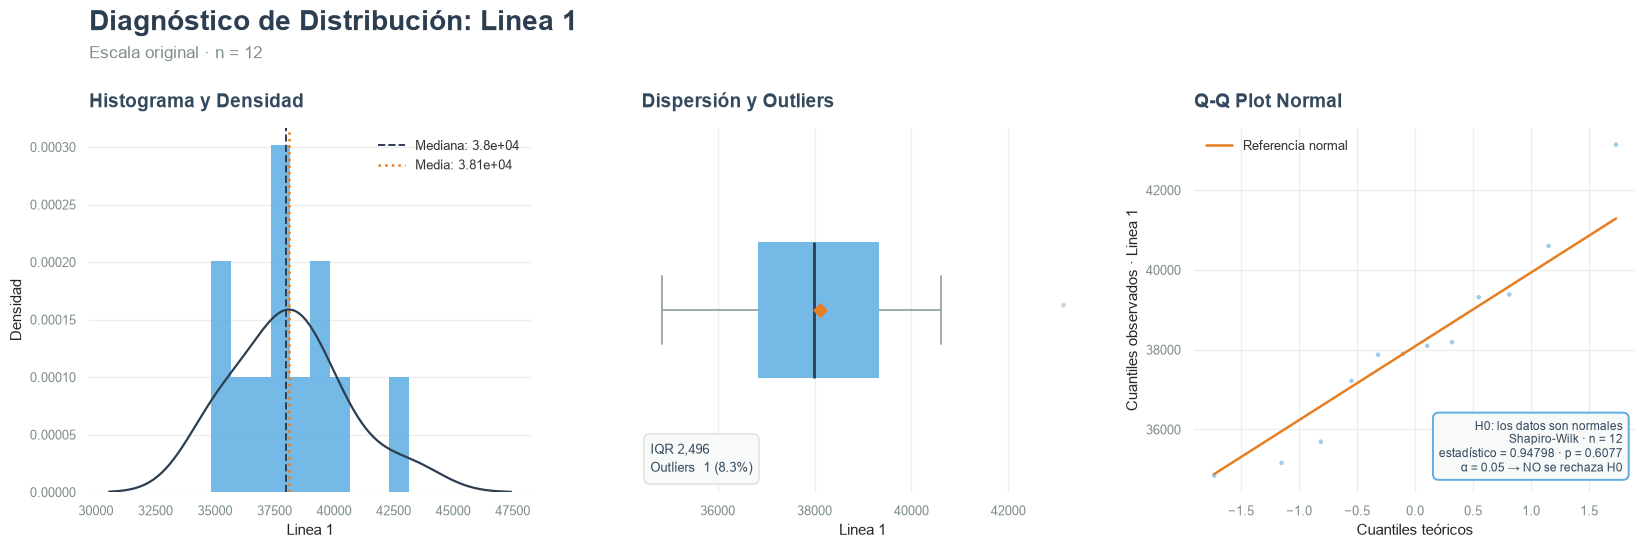

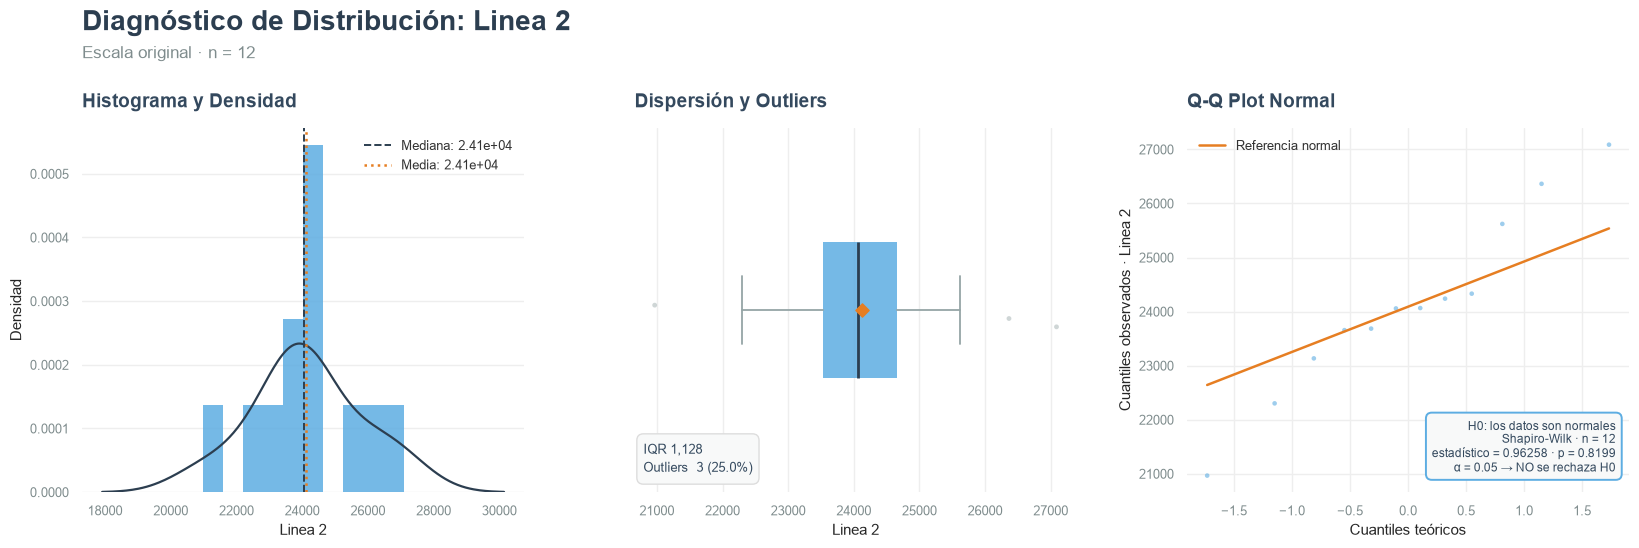

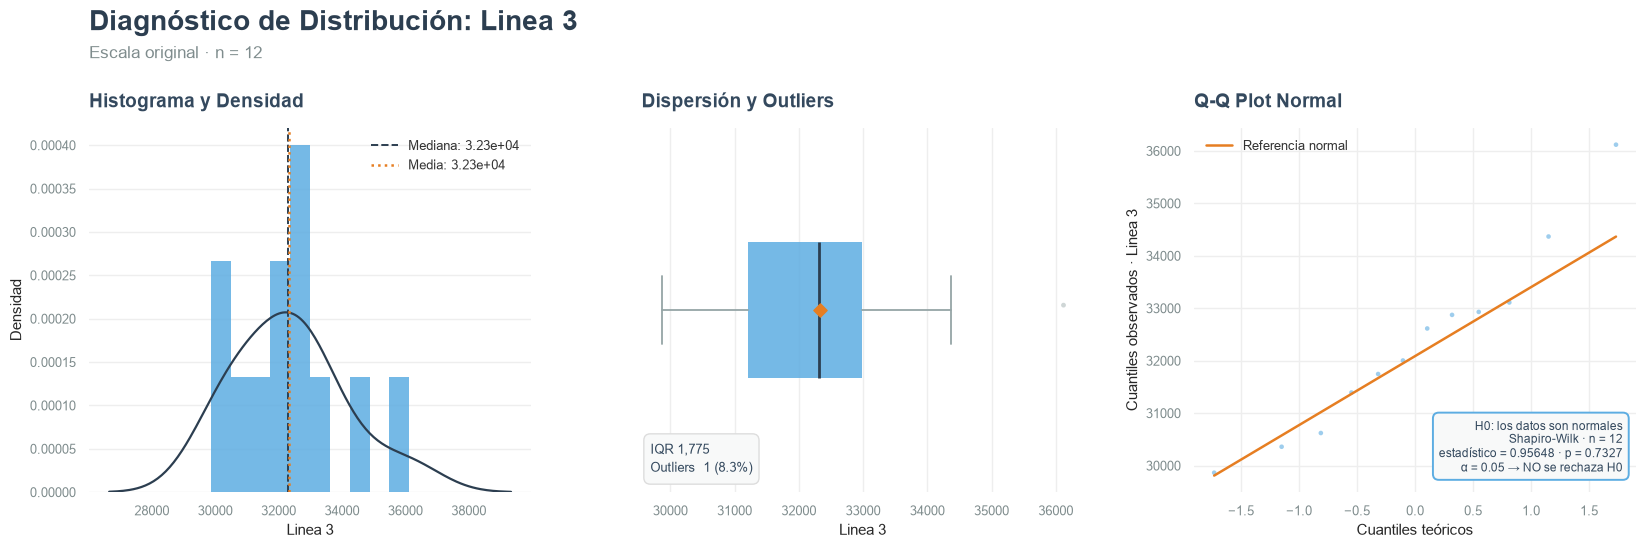

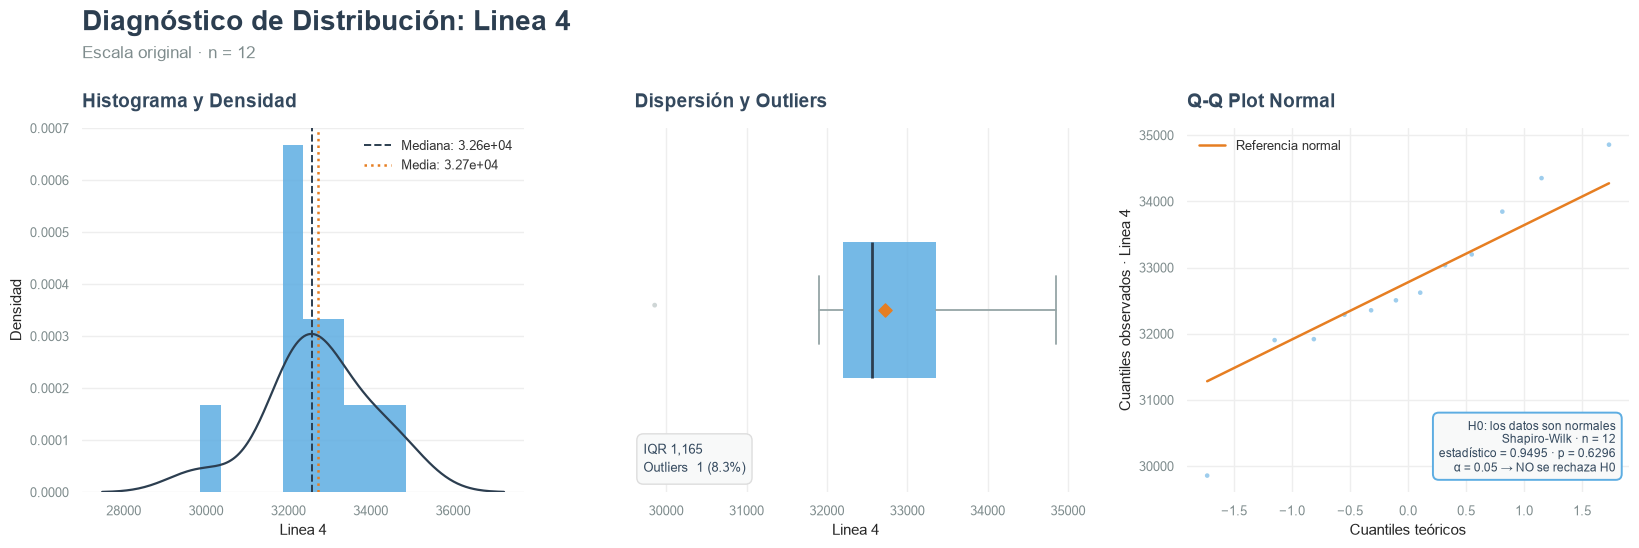

numero de condicion (lineas estandarizadas): 2.2


,n,mean,median,std,skew,kurtosis,test,statistic,p_value,is_normal
Linea 1,12,38118.071,37996.944,2348.692455,0.587127,0.652667,Shapiro-Wilk,0.947981,0.607684,True
Linea 2,12,24126.221,24062.088,1672.984394,0.040831,0.368107,Shapiro-Wilk,0.962581,0.819946,True
Linea 3,12,32333.947,32309.58,1759.638801,0.693927,0.64831,Shapiro-Wilk,0.956482,0.73268,True
Linea 4,12,32728.0257,32563.05285,1303.962883,-0.464898,1.307799,Shapiro-Wilk,0.949497,0.62964,True


Proceso,Linea 1,Linea 2,Linea 3,Linea 4
Proceso,,,,
Linea 1,1.00,-0.02,0.14,0.50
Linea 2,-0.02,1.00,0.14,0.36
Linea 3,0.14,0.14,1.00,0.23
Linea 4,0.50,0.36,0.23,1.00


,VIF,correlacion_maxima,coef_variacion_pct
Linea 1,1.43,0.50,6.16
Linea 2,1.24,0.36,6.93
Linea 3,1.06,0.23,5.44
Linea 4,1.67,0.50,3.98


In [214]:
# Las mismas pruebas previas. La energia por linea y sus derivadas reconstruyen el objetivo
FUGA = ["KWH por proceso", "KWH/Equ (Reales)", "Costo total KWH"]
lineas_filas = solo_train(df_train[df_train["Proceso"] != "Ensamble"]).drop(columns=FUGA)
mes_linea = lineas_filas["Fecha"].dt.to_period("M").dt.to_timestamp()
equ_lineas = lineas_filas.pivot_table(
    index=mes_linea, columns="Proceso", values="Produccion (Equivalente)"
).reindex(planta_modelo.index)
LINEAS = list(equ_lineas.columns)

# Nulos: no se imputan. Antes de reportar, rellenar seria inventar la variable del modelo
print(f"meses de train sin produccion por linea: {equ_lineas.isna().sum().to_dict()}")
lineas_modelo = equ_lineas.dropna().assign(KWH=planta_modelo["KWH"])
assert (lineas_modelo[LINEAS] > 0).all().all(), "hay una linea detenida en train"
assert np.allclose(
    lineas_modelo[LINEAS].sum(axis=1), planta_modelo.loc[lineas_modelo.index, "Equ"]
), "las lineas no suman la produccion de planta"
X_lineas, y_lineas = solo_train(lineas_modelo[LINEAS]), lineas_modelo["KWH"]
print(
    f"{len(lineas_modelo)} meses con produccion por linea, de {lineas_modelo.index[0]:%Y-%m} a "
    f"{lineas_modelo.index[-1]:%Y-%m}"
)

previas_lineas = pd.DataFrame(
    {linea: normality_report(lineas_modelo, linea) for linea in LINEAS}
).T[CAMPOS_NORMALIDAD]

# Colinealidad, explicita: correlacion, VIF, numero de condicion y cuanto varia cada linea
correlacion_lineas = X_lineas.corr()
fuera_diagonal = correlacion_lineas.where(~np.eye(len(LINEAS), dtype=bool))
estandar_lineas = (X_lineas - X_lineas.mean()) / X_lineas.std()
colinealidad_lineas = pd.DataFrame(
    {
        "VIF": vif_table(lineas_modelo, target_variable="KWH").set_index("Variable")["VIF"],
        "correlacion_maxima": fuera_diagonal.abs().max(),
        "coef_variacion_pct": 100 * X_lineas.std() / X_lineas.mean(),
    }
)
print(f"numero de condicion (lineas estandarizadas): {np.linalg.cond(estandar_lineas):.1f}")
display(previas_lineas, correlacion_lineas.round(2))
colinealidad_lineas.round(2)

In [215]:
PENALIZACION_RIDGE = 1.0  # fija: con tan pocos meses no hay con que ajustarla
TOTAL = "planta (produccion total)"
CANDIDATOS_LINEAS = {
    # La forma de planta en los mismos meses: la referencia para saber si separar aporta
    TOTAL: candidato(LinearRegression(), total=True),
    "MCO por linea": candidato(LinearRegression()),
    "MCO sin pendientes negativas": candidato(LinearRegression(positive=True)),
    "Ridge por linea": make_pipeline(
        Caracteristicas(), StandardScaler(), Ridge(alpha=PENALIZACION_RIDGE)
    ),
}

# Un mes adelante desde 8, 9, 10 y 11 meses: no hay historia para folds mas largos
CV_LINEAS = TimeSeriesSplit(n_splits=4, test_size=1)
fuera_lineas = {
    nombre: validar(modelo, X_lineas, y_lineas, CV_LINEAS)
    for nombre, modelo in CANDIDATOS_LINEAS.items()
}
cv_lineas = pd.concat(
    {nombre: informe_cv(fuera) for nombre, fuera in fuera_lineas.items()},
    names=["candidato", "objetivo"],
)

# Los cuatro puntos fuera de muestra, tal cual: con tan pocos conviene verlos
puntos_lineas = pd.DataFrame({nombre: fuera["estimado"] for nombre, fuera in fuera_lineas.items()})
puntos_lineas.insert(0, "real", fuera_lineas[TOTAL]["real"])
puntos_lineas.insert(0, "meses_de_ajuste", fuera_lineas[TOTAL]["meses_ajuste"])
puntos_lineas.index = puntos_lineas.index.strftime("%Y-%m")

# El que queda para la validacion manual: el de menor WAPE entre los que separan por linea
wape_lineas = cv_lineas.xs("kWh", level="objetivo")["WAPE_pct"]
ELEGIDO_LINEAS = wape_lineas.drop(TOTAL).idxmin()
modelo_lineas_final = clone(CANDIDATOS_LINEAS[ELEGIDO_LINEAS]).fit(X_lineas, y_lineas)
print(f"candidato por linea con menor WAPE: {ELEGIDO_LINEAS}")

display(puntos_lineas.round(0))
cv_lineas.round(3)

candidato por linea con menor WAPE: Ridge por linea


,meses_de_ajuste,real,planta (produccion total),MCO por linea,MCO sin pendientes negativas,Ridge por linea
mes,,,,,,
2024-06,8,261006,243907.0,271499.0,220541.0,256265.0
2024-07,9,280610,251144.0,258420.0,256195.0,257949.0
2024-08,10,275338,252151.0,283451.0,277515.0,280548.0
2024-09,11,278693,255147.0,257321.0,244554.0,257199.0


RMSE        MAE      R2  WAPE_pct  \
candidato                    objetivo                                           
planta (produccion total)    kWh       23731.347  23324.638  -8.532     8.515   
                             kWh/Equ       0.190      0.187  -5.016     8.494   
MCO por linea                kWh       16771.088  15541.936  -3.761     5.674   
                             kWh/Equ       0.136      0.125  -2.080     5.706   
MCO sin pendientes negativas kWh       29170.661  25299.026 -13.403     9.236   
                             kWh/Equ       0.240      0.207  -8.659     9.433   
Ridge por linea              kWh       16008.833  13526.441  -3.338     4.938   
                             kWh/Equ       0.129      0.109  -1.803     4.964   

                                       MedAPE_pct  
candidato                    objetivo              
planta (produccion total)    kWh            8.435  
                             kWh/Equ        8.435  
MCO por linea                kWh            5.844  
                             kWh/Equ        5.844  
MCO sin pendientes negativas kWh           10.475  
                             kWh/Equ       10.475  
Ridge por linea              kWh            4.802  
                             kWh/Equ        4.802

In [216]:
# El ajuste con inferencia solo existe para las dos formas sin restriccion ni penalizacion
ajustes_lineas = {
    nombre: ajustar_ols(CANDIDATOS_LINEAS[nombre], X_lineas, y_lineas)
    for nombre in [TOTAL, "MCO por linea"]
}
# Sin Newey-West: 12 observaciones no dan para un anio de rezagos
coeficientes_lineas = pd.concat(
    [tabla_coeficientes(n, modelo_ols, None) for n, modelo_ols in ajustes_lineas.items()],
    ignore_index=True,
)
ajuste_lineas = informe_ajuste(ajustes_lineas, y_lineas)

# Las pendientes de los cuatro candidatos, ajustados en los 12 meses
pendientes_lineas = pd.DataFrame(
    {
        nombre: coeficientes_de(clone(modelo).fit(X_lineas, y_lineas))
        for nombre, modelo in CANDIDATOS_LINEAS.items()
    }
).T

supuestos_lineas = supuestos(ajustes_lineas["MCO por linea"], [REZAGO_CORTO])
supuestos_lineas.loc[len(supuestos_lineas)] = {
    "supuesto": "residuos independientes",
    "prueba": f"rezago {PERIODO}",
    "estadistico": np.nan,
    **SIN_PRUEBA,
    "lectura": f"no se calcula con {len(X_lineas)} observaciones",
}

with pd.option_context("display.float_format", "{:,.4f}".format):
    display(coeficientes_lineas, ajuste_lineas, pendientes_lineas)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(supuestos_lineas.round(4))

Observaciones con residuos atípicos (|student| > 2): 1
Observaciones con alto leverage (hat > 0.833): 0
Observaciones influyentes (Cook D > 0.333): 4


,candidato,termino,coeficiente,error_estandar,p_valor,ic95_inf,ic95_sup
0,planta (produccion total),const,"323,332.8609","154,362.5953",0.0626,"-20,608.4350","667,274.1568"
1,planta (produccion total),Equ,-0.5150,1.2118,0.6798,-3.2151,2.1851
2,MCO por linea,const,"349,232.5992","123,783.4198",0.0257,"56,531.3228","641,933.8756"
3,MCO por linea,Linea 1,2.6279,2.1579,0.2628,-2.4748,7.7305
4,MCO por linea,Linea 2,-6.0823,2.8230,0.0682,-12.7576,0.5930
5,MCO por linea,Linea 3,-3.3560,2.4855,0.2190,-9.2331,2.5212
6,MCO por linea,Linea 4,1.9439,4.2096,0.6582,-8.0102,11.8980


,n,parametros,R2,R2_ajustado,F,p_F,error_residual,durbin_watson,carga_base_pct_mes_mediano,alpha,Equ,Linea 1,Linea 2,Linea 3,Linea 4
candidato,,,,,,,,,,,,,,,
planta (produccion total),12,2,0.0177,-0.0805,0.1806,0.6798,"18,246.4915",1.1664,123.6230,"323,332.8609",-0.5150,NaN,NaN,NaN,NaN
MCO por linea,12,5,0.5908,0.3570,2.5271,0.1344,"14,075.4045",2.7937,133.5255,"349,232.5992",NaN,2.6279,-6.0823,-3.3560,1.9439


,alpha,Equ,Linea 1,Linea 2,Linea 3,Linea 4
planta (produccion total),"323,332.8609",-0.5150,NaN,NaN,NaN,NaN
MCO por linea,"349,232.5992",NaN,2.6279,-6.0823,-3.3560,1.9439
MCO sin pendientes negativas,"146,790.9828",NaN,2.9114,0.0000,0.0000,0.0000
Ridge por linea,"344,187.6573",NaN,2.4937,-5.5659,-3.0839,1.6048


,supuesto,prueba,estadistico,p_valor,H0,se_rechaza_H0,lectura
0,forma lineal,Ramsey RESET,2.4707,0.1670,la forma lineal es adecuada,False,sin evidencia en contra
1,residuos normales,Jarque-Bera,0.9325,0.6274,los residuos son normales,False,sin evidencia en contra
2,residuos normales,Shapiro-Wilk,0.9302,0.3823,los residuos son normales,False,sin evidencia en contra
3,varianza constante,Breusch-Pagan,2.0237,0.7314,la varianza es constante,False,sin evidencia en contra
4,residuos independientes,Durbin-Watson,2.7937,NaN,-,None,autocorrelacion negativa
5,residuos independientes,"Breusch-Godfrey, rezago 1",4.7790,0.0288,sin autocorrelacion,True,residuos autocorrelados
6,residuos independientes,"Ljung-Box, rezago 1",3.6022,0.0577,sin autocorrelacion,False,sin evidencia en contra
7,relacion no espuria,ADF sobre los residuos,-5.2572,0.0000,los residuos tienen raiz unitaria,True,"sin raiz unitaria, pero el nivel cambia"
8,relacion no espuria,KPSS sobre los residuos,0.5000,0.0417,el nivel de los residuos es constante,True,"sin raiz unitaria, pero el nivel cambia"
9,sin colinealidad,VIF maximo,1.6729,NaN,-,None,sin colinealidad apreciable


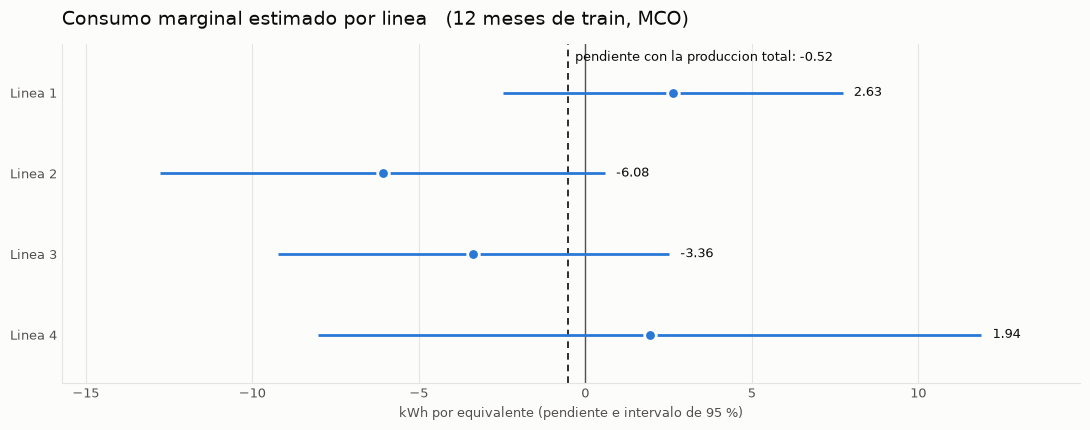

In [217]:
# Pendiente de cada linea con su intervalo de 95 %, contra la pendiente de la planta
por_linea = (
    coeficientes_lineas.query("candidato == 'MCO por linea' and termino != 'const'")
    .set_index("termino")
    .loc[LINEAS[::-1]]
)
beta_total = pendientes_lineas.loc[TOTAL, "Equ"]
posiciones = np.arange(len(por_linea))

fig, ax = plt.subplots(figsize=(11, 4.4), facecolor=SUPERFICIE)
estilo_eje(ax)
ax.grid(visible=False, axis="y")
ax.grid(axis="x", color=GRILLA, linewidth=0.8)

ax.axvline(0, color=TINTA_SUAVE, linewidth=1, zorder=1)
ax.axvline(beta_total, color=TINTA, linewidth=1.2, linestyle=(0, (4, 3)), zorder=1)
ax.annotate(
    f"pendiente con la produccion total: {beta_total:.2f}",
    xy=(beta_total, 1),
    xycoords=("data", "axes fraction"),
    xytext=(5, -12),
    textcoords="offset points",
    color=TINTA,
    fontsize=9,
)
ax.hlines(posiciones, por_linea["ic95_inf"], por_linea["ic95_sup"], color=LINEA, linewidth=2)
ax.scatter(
    por_linea["coeficiente"],
    posiciones,
    s=70,
    color=LINEA,
    edgecolors=SUPERFICIE,
    linewidths=2,
    zorder=3,
)
for posicion, (coeficiente, superior) in enumerate(
    zip(por_linea["coeficiente"], por_linea["ic95_sup"], strict=True)
):
    ax.annotate(
        f"{coeficiente:.2f}",
        xy=(superior, posicion),
        xytext=(8, 0),
        textcoords="offset points",
        color=TINTA,
        fontsize=9,
        va="center",
    )
ax.set_yticks(posiciones, por_linea.index)
ax.set_ylim(-0.6, len(por_linea) - 0.4)
ax.margins(x=0.12)
ax.set_xlabel("kWh por equivalente (pendiente e intervalo de 95 %)", fontsize=9, color=TINTA_SUAVE)
ax.set_title(
    f"Consumo marginal estimado por linea   ({len(X_lineas)} meses de train, MCO)",
    fontsize=14,
    color=TINTA,
    loc="left",
    pad=14,
)

plt.tight_layout()
plt.show()

#### Resumen: modelo por lineas

- **No hay colinealidad** (VIF de 1.06 a 1.67, correlacion maxima de 0.50, numero de
  condicion 2.2), asi que Ridge no hace falta por ese motivo. El problema es otro: en estos
  12 meses cada linea varia solo entre 3.98 y 6.93 %.
- **En esos meses la energia no responde a la produccion.** Con la produccion total la
  pendiente es -0.515 (p 0.6798) y el R2 0.0177.
- **Las pendientes por linea no se distinguen de cero**: 2.63, -6.08, -3.36 y 1.94 kWh por
  equivalente, con p de 0.0682 a 0.6582 y un ajuste global no significativo (F con p
  0.1344, R2 ajustado 0.357). Dos salen negativas, que no tiene sentido fisico.
- **La validacion cruzada son 4 puntos.** El WAPE va de 4.94 % (Ridge) a 9.24 % (sin
  pendientes negativas) y todos los R2 son negativos. `modelo_lineas_final` queda con Ridge
  por tener el menor error, no porque se pueda interpretar.
- **Indicativo, no concluyente.** Con 12 meses y tan poca variacion no se puede asignar un
  consumo marginal a cada linea: hace falta mas historia, o meses en que las lineas se
  muevan por separado.

## Intentar Splines en el modelo global

In [218]:
X_planta.head()

,Equ
mes,
2019-10-01,124270.0
2019-11-01,113586.0
2019-12-01,124397.0
2020-01-01,123173.0
2020-02-01,128683.0


In [219]:
y_planta.head()

mes
2019-10-01    309181
2019-11-01    290330
2019-12-01    324206
2020-01-01    309006
2020-02-01    300954
Name: KWH, dtype: int64

In [220]:
pipeline = Pipeline(
    [
        ("scaler", RobustScaler()),
        ("spline", SplineTransformer(degree=1, extrapolation="linear")),
        ("regressor", Ridge()),
    ]
)

param_grid = {
    "spline__n_knots": [3, 4, 5, 7, 10],  # Probar distintos nudos
    "regressor__alpha": [0.1, 1.0, 10.0],  # Probar distintas regularizaciones
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=tscv,  # o cv=TimeSeriesSplit(n_splits=5)
    scoring="r2",
)

grid_search.fit(X_planta, y_planta)

print("Mejores hiperparámetros:", grid_search.best_params_)
print("Mejor puntaje (R2):", grid_search.best_score_)

Mejores hiperparámetros: {'regressor__alpha': 10.0, 'spline__n_knots': 10}
Mejor puntaje (R2): -1.3203962348358296
